# load


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install "cell2location[tutorials]"

In [ ]:
%pip install --force-reinstall --no-deps "pyro-ppl==1.9.1"

# import

In [ ]:
import os
import scanpy as sc
import numpy as np
import pandas as pd
import scanpy.external as sce
from sklearn.decomposition import TruncatedSVD
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import gseapy as gp
from scipy.sparse import csr_matrix
import seaborn as sns
import anndata as ad
import pooch
# import sctour as sct
from gseapy.plot import barplot, dotplot
import harmonypy as hm
# import squidpy as sq


In [ ]:
from cell2location.plt import plot_spatial
from cell2location.utils import select_slide

In [ ]:
import squidpy as sq

In [ ]:
from pathlib import Path


In [ ]:
os.chdir('/content/drive/MyDrive/pharynx')

# def

In [ ]:
dot_map = LinearSegmentedColormap.from_list(
    "dot_map",
    [ '#255eaa','#efefee',"#e34051"]
)

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list(
    "niche_cmap",
    [
        "#1E2B60",  # 深蓝
        "#28457B",
        "#2C6E88",
        "#1B9593",  # 青绿
        "#68B186",
        "#A2CA6E",
        "#D2DF52",
        "#F0E636",  # 亮黄
        "#DEAC51",
        "#C5705E",
        "#A62A65",  # 紫红
    ],
    N=256
)

In [ ]:
from scipy import sparse
#辅助注释的函数，可以deepseek一下其主要功能理解以下
def anno_agent(
    adata,
    cell_type,
    cluster_key="leiden",
    min_pct_expr=0.25,
    min_fc=1,
    max_fdr=0.05,
    top_n=10,
):
    """
    Annotate cell types using top-ranked marker genes with filtering thresholds.
    """
    # 1. 取表达矩阵和基因名
    X_use = adata.raw.X if adata.raw is not None else adata.X
    var_names = adata.raw.var_names if adata.raw is not None else adata.var_names

    clusters = sorted(
        adata.obs[cluster_key].unique(),
        key=lambda x: float(x) if str(x).replace(".", "", 1).isdigit() else str(x),
    )
    output_lines = []

    for cluster in clusters:
        # 2. 差异表达结果
        df = sc.get.rank_genes_groups_df(adata, group=cluster).set_index("names")

        # 3. 计算表达比例
        mask = (adata.obs[cluster_key] == cluster).to_numpy()  # ← 关键修复
        if sparse.issparse(X_use):
            frac = (X_use[mask] > 0).mean(axis=0).A1  # .A1 转一维
        else:
            frac = (X_use[mask] > 0).mean(axis=0)

        expr_frac_series = pd.Series(frac, index=var_names)

        # 4. 对齐并拼接
        common = df.index.intersection(expr_frac_series.index)
        df = df.loc[common]
        df["pct_expr"] = expr_frac_series.loc[common]

        # 5. 过滤阈值
        df = df[
            (df["pct_expr"] >= min_pct_expr)
            & (df["logfoldchanges"] >= np.log2(min_fc))
            & (df["pvals_adj"] <= max_fdr)
        ]

        # 6. 去除线粒体/核糖体基因
        df = df[~df.index.str.startswith(("MT-", "RPS", "RPL"))]

        # 7. 收集 top-n marker
        top_genes = df.head(top_n).index.tolist()
        output_lines.append(f"{cluster}: {','.join(top_genes)}")

    # 8. 生成提示文本
    return (
        f"Identify cell types of {cell_type} using the following markers. "
        "Identify one cell type for each row. Attention - Determine the Subtype, Characteristic Genes, Phenotype, and Predict Function for Each Cell Type."
        " Present the Results in a Tabular Format：\n"
        + "\n".join(output_lines)
    )

# read

In [ ]:
# !unzip /content/drive/MyDrive/pharynx/1.rawdata/HNSCC14_LN/HNSCC14_LN.zip -d /content/drive/MyDrive/pharynx/1.rawdata/HNSCC14_LN/

In [ ]:
# !unzip /content/drive/MyDrive/pharynx/1.rawdata/HNSCC59_LN/HNSCC59_LN.zip -d /content/drive/MyDrive/pharynx/1.rawdata/HNSCC59_LN/

In [ ]:
adata_1 = sc.read_visium(
    path="/content/drive/MyDrive/pharynx/1.rawdata/HNSCC14_LN/",
    count_file="filtered_feature_bc_matrix.h5",  # 或者不写默认也行
    load_images=True
)
print(adata_1)

/tmp/ipykernel_1082/433637839.py:1: FutureWarning: The function read_visium is deprecated and will be removed in the future. Use :func:`squidpy.read.visium` instead.
  adata_1 = sc.read_visium(
/usr/local/lib/python3.13/dist-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


AnnData object with n_obs × n_vars = 3932 × 17943
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
    layers: None (.X)


/tmp/ipykernel_1768/1013598331.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


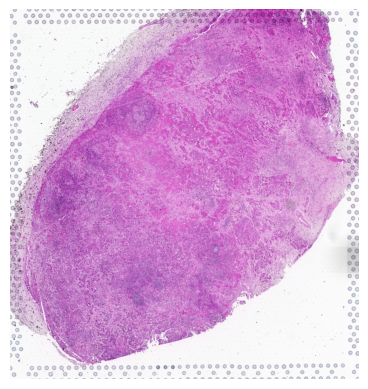

In [ ]:
sc.pl.spatial(
        adata_1,
        cmap='RdBu_r',
        # color=["leiden"],
        ncols=1, size=1.3,
        img_key='hires',
        vmin=0, vmax='p99.2',
        colorbar_loc=None,
        frameon=False,
    )

In [ ]:
adata_2 = sc.read_visium(
    path="/content/drive/MyDrive/pharynx/1.rawdata/HNSCC59_LN/",
    count_file="filtered_feature_bc_matrix.h5",  # 或者不写默认也行
    load_images=True
)
print(adata_2)

/tmp/ipykernel_1594/3655847501.py:1: FutureWarning: The function read_visium is deprecated and will be removed in the future. Use :func:`squidpy.read.visium` instead.
  adata_2 = sc.read_visium(
/usr/local/lib/python3.13/dist-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


AnnData object with n_obs × n_vars = 4536 × 17943
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
    layers: None (.X)


/tmp/ipykernel_1768/466265145.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


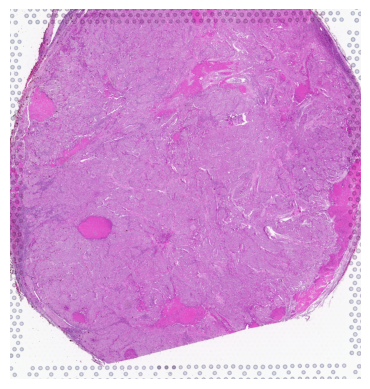

In [ ]:
sc.pl.spatial(
        adata_2,
        cmap='RdBu_r',
        # color=["leiden"],
        ncols=1, size=1.3,
        img_key='hires',
        vmin=0, vmax='p99.2',
        colorbar_loc=None,
        frameon=False,
    )

In [ ]:
adata_1.obs["sample"] = "HNSCC14"
adata_2.obs["sample"] = "HNSCC59"

In [ ]:
adata_1.var_names_make_unique()
adata_2.var_names_make_unique()

In [ ]:
adata_1.uns["spatial"] = {
    "HNSCC14": adata_1.uns["spatial"][
        list(adata_1.uns["spatial"].keys())[0]
    ]
}
adata_2.uns["spatial"] = {
    "HNSCC59": adata_2.uns["spatial"][
        list(adata_2.uns["spatial"].keys())[0]
    ]
}

spatial_1 = adata_1.uns["spatial"]
spatial_2 = adata_2.uns["spatial"]

In [ ]:
import scanpy as sc

# 改成你的实际样本名
adatas = {
    "HNSCC14": adata_1.copy(),
    "HNSCC59": adata_2.copy()
}

# 1. 给每张切片的空间信息设置独立名称
for sample_name, adata in adatas.items():

    # 检查坐标和图像信息
    assert "spatial" in adata.obsm, f"{sample_name} 缺少空间坐标"
    assert "spatial" in adata.uns, f"{sample_name} 缺少空间图像信息"
    assert len(adata.uns["spatial"]) == 1, (
        f"{sample_name} 包含多张切片，需分别处理"
    )

    old_key = next(iter(adata.uns["spatial"]))

    # 直接重建字典，避免同名赋值后误删
    adata.uns["spatial"] = {
        sample_name: adata.uns["spatial"][old_key]
    }

    adata.var_names_make_unique()

# 2. 合并
import anndata as ad

adata = ad.concat(
    [adata_1, adata_2],
    join="inner",
    merge="same",
    label="sample",
    keys=["HNSCC14", "HNSCC59"]
)

adata.obs["sample"] = adata.obs["sample"].astype("category")

print(adata)
adata.obs_names_make_unique()

# 3. 检查空间信息是否保留
print(adata)
print(adata.obs["sample"].value_counts())
# print("图像所属样本：", list(adata.uns["spatial"].keys()))
print("空间坐标维度：", adata.obsm["spatial"].shape)

ModuleNotFoundError: No module named 'scanpy'

In [ ]:
adata.uns["spatial"] = {
    **adata_1.uns["spatial"],
    **adata_2.uns["spatial"]
}

In [ ]:
print(adata)

AnnData object with n_obs × n_vars = 8468 × 17943
    obs: 'in_tissue', 'array_row', 'array_col', 'sample'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
    layers: None (.X)


In [ ]:
adata.write("./visum/data/LN inte.h5ad")

In [ ]:
adata.raw = adata.copy()

In [ ]:
# annotate the group of mitochondrial genes as "mt"
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)

In [ ]:
adata

AnnData object with n_obs × n_vars = 8468 × 17943
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'spatial', 'sample_colors'
    obsm: 'spatial'
    layers: None (.X), 'counts'

[<Axes: xlabel='sample', ylabel='n_genes_by_counts'>,
 <Axes: xlabel='sample', ylabel='total_counts'>,
 <Axes: xlabel='sample', ylabel='pct_counts_mt'>]

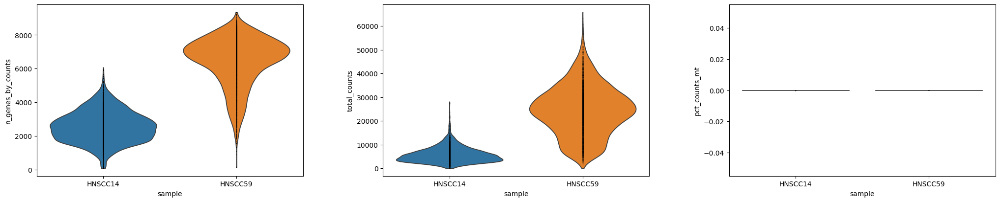

In [ ]:
sc.pl.violin(
    adata,
    ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'],
    groupby='sample',
    jitter=False,
    multi_panel=True,
    show=False
)

In [ ]:
sc.pp.filter_genes(adata, min_cells=3)

In [ ]:
adata.layers["counts"] = adata.X.copy()

In [ ]:
adata.raw = adata.copy()

In [ ]:
adata.X = adata.layers["counts"].copy()
sc.pp.normalize_total(
    adata,
    target_sum=1e4
)

sc.pp.log1p(adata)

sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor="seurat_v3",
    layer = "counts",batch_key="sample"
)

adata = adata[:, adata.var.highly_variable].copy()

In [ ]:
sc.pp.regress_out(adata, ['total_counts'])

sc.pp.scale(adata)
sc.tl.pca(adata, svd_solver="arpack")

/usr/local/lib/python3.13/dist-packages/scanpy/preprocessing/_simple.py:660: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 2, 'C', False, aligned=True))
  data[i] -= regressor[i] @ coeff
/usr/local/lib/python3.13/dist-packages/scanpy/preprocessing/_simple.py:660: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 2, 'C', False, aligned=True))
  data[i] -= regressor[i] @ coeff


In [ ]:
pcs = adata.obsm['X_pca']

# Run Harmony on the PCA embedding
harmony_out = hm.run_harmony(pcs,adata.obs, ["sample"],max_iter_harmony= 30)

# Store corrected PCs back in the AnnData object
adata.obsm['X_pca_harmony'] = harmony_out.Z_corr

2026-09-25 08:11:14,018 - harmonypy - INFO - Running Harmony
INFO:harmonypy:Running Harmony
2026-09-25 08:11:14,021 - harmonypy - INFO -   Parameters:
INFO:harmonypy:  Parameters:
2026-09-25 08:11:14,025 - harmonypy - INFO -     max_iter_harmony: 30
INFO:harmonypy:    max_iter_harmony: 30
2026-09-25 08:11:14,028 - harmonypy - INFO -     max_iter_kmeans: 4
INFO:harmonypy:    max_iter_kmeans: 4
2026-09-25 08:11:14,032 - harmonypy - INFO -     epsilon_cluster: 0.001
INFO:harmonypy:    epsilon_cluster: 0.001
2026-09-25 08:11:14,035 - harmonypy - INFO -     epsilon_harmony: 0.01
INFO:harmonypy:    epsilon_harmony: 0.01
2026-09-25 08:11:14,038 - harmonypy - INFO -     nclust: 100
INFO:harmonypy:    nclust: 100
2026-09-25 08:11:14,042 - harmonypy - INFO -     block_size: 0.05
INFO:harmonypy:    block_size: 0.05
2026-09-25 08:11:14,044 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
INFO:harmonypy:    lamb: dynamic (alpha=0.2)
2026-09-25 08:11:14,048 - harmonypy - INFO -     theta: [2. 2.]


In [ ]:
sc.pp.neighbors(adata,n_pcs=30,use_rep="X_pca_harmony")
sc.tl.umap(adata,min_dist=0.3)

In [ ]:
adata = adata.raw.to_adata()
# t_adata.X = t_adata.X.astype(np.int64) ## make sure the matrix is int64
adata.raw = adata.copy()
adata.layers["counts"] = adata.X.copy()

In [ ]:
sc.pp.normalize_total(adata,target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata.copy()
adata.X = adata.layers["counts"].copy()

In [ ]:
adata.X = adata.layers["counts"].copy()

# c2l

In [ ]:
adata

In [ ]:
adata_ref = sc.read_h5ad("./1.rawdata/sc/Final_rebuilt_subtype.h5ad")
adata_ref.X = adata_ref.layers['counts'].copy()

In [ ]:
adata_ref

AnnData object with n_obs × n_vars = 40980 × 13879
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'original_index', 'sample', 'sampleid', 'rawbc', 'species', 'group', 'batchid', 'percent.mito', 'percent.HB', 'sampleid_col', 'group_col', 'log10GenesPerUMI', 'is_metric_outlier', 'is_valid', 'is_doublets', 'clusters', 'RNA_snn_res.0.4', 'seurat_clusters', 'RNA.umap.res.0.4', 'raw_main_celltype', 'hpca.main.celltype', 'celltype', 'new_celltype', 'dataset_source', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ig', 'pct_counts_ig', 'n_genes', 'leiden_0.1', 'leiden_0.2', 'leiden_0.3', 'leiden_0.4', 'leiden_0.5', 'leiden_0.6', 'leiden_0.7', 'leiden_0.8', 'leiden_0.9', 'leiden_1.0', 'leiden_1.1', 'leiden_1.2', 'leiden_1.3', 'leiden_1.4', 'leiden_1.5', 'leiden_1.6', 'leiden_1.7', 'leiden_1.8', 'leiden_1.9', 'leiden_2.0', 'subtype', 'Sample', 'leiden_0.30', 'leiden_0.40', 'leiden_0.50', 'leiden_0.60', 'leiden_0.70', 'leiden_0.80', 'leiden_0.90', 'lei

In [ ]:
adata_ref.obs["subtype"].unique().tolist()

['Plasma',
 'Mac_SPP1',
 'CD8T_GZMK',
 'CD8T_str',
 'mregDC',
 'Treg',
 'CD4T_GZMB',
 'CD8T_CXCL13',
 'CD8T_naive',
 'Neutrophil',
 'Cycling_T',
 'iCAF_CXCL8',
 'CD4T_PTPRC',
 'apCAF',
 'Capillary_EC',
 'B',
 'myCAF_CTHRC1',
 'Mast',
 'Mac_CXCL5',
 'Basal_Epi',
 'CD4T_naive',
 'Arterial_EC',
 'Mac_FOLR2',
 'CD8T_GZMA',
 'NK',
 'myCAF_COL14A1',
 'Cycling_CAF',
 'EC_PGF',
 'CD4T_CXCL13',
 'qEC',
 'EC_ACKR1',
 'Diff_Epi',
 'Mono_FCN1',
 'iCAF_CXCL1',
 'Hypoxia_Epi',
 'Cycling_EC',
 'Normal_Epi',
 'Prolif_Epi',
 'EMT_like_Epi',
 'Stem_like_Epi',
 'Str_Epi']

In [ ]:
import cell2location
from cell2location.models import RegressionModel

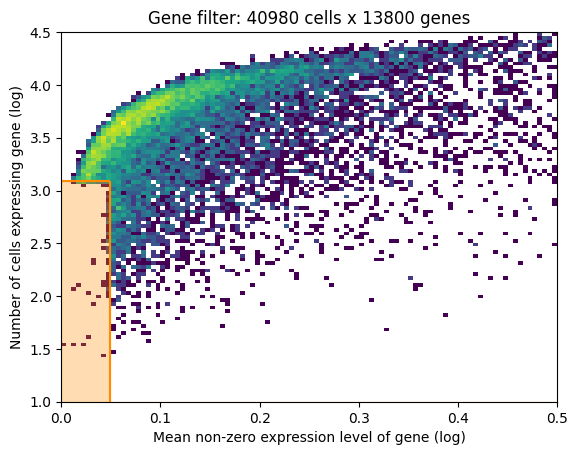

In [ ]:
from cell2location.utils.filtering import filter_genes
selected = filter_genes(adata_ref, cell_count_cutoff=5, cell_percentage_cutoff2=0.03, nonz_mean_cutoff=1.12)

# # filter the object
adata_ref = adata_ref[:, selected].copy()

In [ ]:
cell2location.models.RegressionModel.setup_anndata(adata=adata_ref,#参考数据集
      batch_key='orig.ident',#adata.obs中批次/sample列。
      labels_key='subtype',# celltype注释列
      categorical_covariate_keys=None#矫正技术因素（例如platform, 3' vs 5', donor effect）
      )

In [ ]:
from cell2location.models import RegressionModel
mod = RegressionModel(adata_ref)

In [ ]:
# view anndata_setup as a sanity check
mod.view_anndata_setup()

Anndata setup with scvi-tools version 1.5.1.

Setup via `RegressionModel.setup_anndata` with arguments:

{
│   'layer': None,
│   'batch_key': 'orig.ident',
│   'labels_key': 'subtype',
│   'categorical_covariate_keys': None,
│   'continuous_covariate_keys': None
}

         Summary Statistics         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃     Summary Stat Key     ┃ Value ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│         n_batch          │   6   │
│         n_cells          │ 40980 │
│ n_extra_categorical_covs │   0   │
│ n_extra_continuous_covs  │   0   │
│         n_labels         │  41   │
│          n_vars          │ 13800 │
└──────────────────────────┴───────┘

               Data Registry                
┏━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Registry Key ┃    scvi-tools Location    ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│      X       │          adata.X          │
│    batch     │ adata.obs['_scvi_batch']  │
│    ind_x     │   adata.obs['_indices']   │
│    labels    │ adata.obs['_scvi_labels'] │
└──────────────┴───────────────────────────┘

                     batch State Registry                     
┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃     Source Location     ┃ Categories ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['orig.ident'] │    NO_1    │          0          │
│                         │    NO_2    │          1          │
│                         │    NO_3    │          2          │
│                         │  Smoke_1   │          3          │
│                         │  Smoke_2   │          4          │
│                         │  Smoke_3   │          5          │
└─────────────────────────┴────────────┴─────────────────────┘

                    labels State Registry                     
┏━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃   Source Location    ┃  Categories   ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['subtype'] │  Arterial_EC  │          0          │
│                      │       B       │          1          │
│                      │   Basal_Epi   │          2          │
│                      │  CD4T_CXCL13  │          3          │
│                      │   CD4T_GZMB   │          4          │
│                      │  CD4T_PTPRC   │          5          │
│                      │  CD4T_naive   │          6          │
│                      │  CD8T_CXCL13  │          7          │
│                      │   CD8T_GZMA   │          8          │
│                      │   CD8T_GZMK   │          9          │
│                      │  CD8T_naive   │         10          │
│                      │   CD8T_str    │         11          │
│                      │ Capillary_EC  │         12          │
│                      │  Cycling_CAF  │         13          │
│                      │  Cycling_EC   │         14          │
│                      │   Cycling_T   │         15          │
│                      │   Diff_Epi    │         16          │
│                      │   EC_ACKR1    │         17          │
│                      │    EC_PGF     │         18          │
│                      │ EMT_like_Epi  │         19          │
│                      │  Hypoxia_Epi  │         20          │
│                      │   Mac_CXCL5   │         21          │
│                      │   Mac_FOLR2   │         22          │
│                      │   Mac_SPP1    │         23          │
│                      │     Mast      │         24          │
│                      │   Mono_FCN1   │         25          │
│                      │      NK       │         26          │
│                      │  Neutrophil   │         27          │
│                      │  Normal_Epi   │         28          │
│                      │    Plasma     │         29          │
│                      │  Prolif_Epi   │         30          │
│                      │ Stem_like_Epi │         31          │
│                      │    Str_Epi    │         32          │
│                      │     Treg      │         33          │
│                      │     apCAF     │         34          │
│                      │  iCAF_CXCL1   │         35          │
│                      │  iCAF_CXCL8   │         36          │
│                      │    mregDC     │         37          │
│                      │ myCAF_COL14A1 │         38          │
│                      │ myCAF_CTHRC1  │         39          │
│                      │      qEC      │         40          │
└──────────────────────┴───────────────┴─────────────────────┘

In [ ]:
mod.train(max_epochs=1000,accelerator="cuda")

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/configuration_validator.py:68: You passed in a `val_dataloader` but have no `validation_step`. Skipping val loop.
INFO: You are using a CUDA device ('NVIDIA A100-SXM4-

Training:   0%|          | 0/1000 [00:00<?, ?it/s]

INFO: `Trainer.fit` stopped: `max_epochs=1000` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=1000` reached.


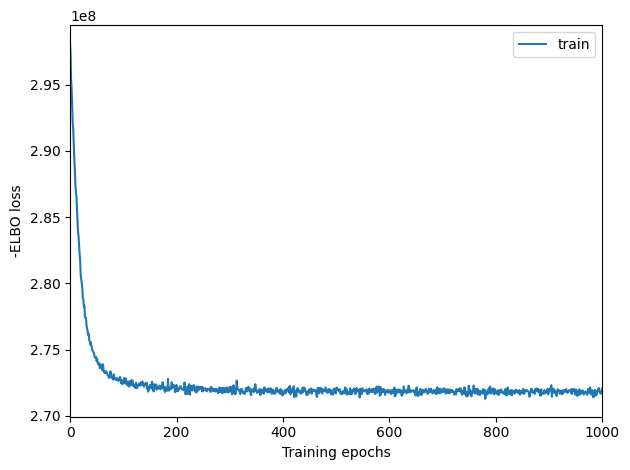

In [ ]:
mod.plot_history()

In [ ]:
# In this section, we export the estimated cell abundance (summary of the posterior distribution).
adata_ref = mod.export_posterior(
    adata_ref, sample_kwargs={'num_samples': 1000, 'batch_size': 2500, 'accelerator': 'cuda'}
)
adata_ref = mod.export_posterior(
    adata_ref, use_quantiles=True,
    # choose quantiles
    add_to_varm=["q05","q50", "q95", "q0001"],
    sample_kwargs={'batch_size': 2500, 'accelerator': 'cuda'}
)
# Save model
mod.save("./visum/reference_signatures/mob_train_intecaf", overwrite=True)

# Save anndata object with results
adata_ref.write("./visum/sc_cell2location_intecaf.h5ad")

Sampling local variables, batch:   0%|          | 0/17 [00:00<?, ?it/s]

Sampling global variables, sample:   0%|          | 0/999 [00:00<?, ?it/s]

In [ ]:
#模型和输出的h5ad，可以像这样加载:
adata_ref = sc.read_h5ad("./visum/sc_cell2location_intecaf.h5ad")
mod = cell2location.models.RegressionModel.load("./visum/reference_signatures/mob_train", adata_ref)

INFO     File ./visum/reference_signatures/mob_train/model.pt already downloaded                                   


ValueError: Category myCAF_COL14A1 not found in source registry. Cannot transfer setup without `extend_categories = True`.

In [ ]:
# export estimated expression in each cluster
if 'means_per_cluster_mu_fg' in adata_ref.varm.keys():
    inf_aver = adata_ref.varm['means_per_cluster_mu_fg'][[f'means_per_cluster_mu_fg_{i}'
                                    for i in adata_ref.uns['mod']['factor_names']]].copy()
else:
    inf_aver = adata_ref.var[[f'means_per_cluster_mu_fg_{i}'
                                    for i in adata_ref.uns['mod']['factor_names']]].copy()
inf_aver.columns = adata_ref.uns['mod']['factor_names']
inf_aver.iloc[0:5, 0:15]

          Arterial_EC         B  Basal_Epi  CD4T_CXCL13  CD4T_GZMB  \
gene_id                                                              
A1BG-AS1     0.017899  0.023494   0.021688     0.027063   0.038656   
A2M         26.272076  0.010085   0.015844     0.010600   0.004930   
A2ML1        0.006376  0.003081   0.171921     0.004395   0.003425   
A4GALT       1.270882  0.005179   1.058326     0.003853   0.001370   
AAAS         0.148132  0.033517   0.391488     0.035907   0.058440   

          CD4T_PTPRC  CD4T_naive  CD8T_CXCL13  CD8T_GZMA  CD8T_GZMK  \
gene_id                                                               
A1BG-AS1    0.035014    0.017323     0.040729   0.018416   0.037972   
A2M         0.039931    0.016478     0.003984   0.170861   0.049778   
A2ML1       0.005460    0.002305     0.001079   0.000971   0.001082   
A4GALT      0.003037    0.001247     0.002806   0.002589   0.004154   
AAAS        0.096693    0.040338     0.050361   0.042600   0.034751   

          C

In [ ]:
adata=sc.read_h5ad("./visum/data/st.h5ad")

In [ ]:
adata

AnnData object with n_obs × n_vars = 4640 × 12179
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt', 'clusters', 'leiden', 'gene_niche', 'subtype', '_indices', '_scvi_batch', '_scvi_labels', 'Program_1', 'Program_2', 'Program_3', 'Program_4', 'Program_5', 'Program_6', 'Program_7', 'LAMA2_positive', 'LAMA2_expr', 'Arterial_EC', 'B', 'Basal_Epi', 'CAF_COL14A1', 'CD4T_CXCL13', 'CD4T_GZMB', 'CD4T_PTPRC', 'CD4T_naive', 'CD8T_CXCL13', 'CD8T_GZMA', 'CD8T_GZMK', 'CD8T_naive', 'CD8T_str', 'Capillary_EC', 'Cycling_CAF', 'Cycling_EC', 'Cycling_T', 'Diff_Epi', 'EC_ACKR1', 'EC_PGF', 'EMT_like_Epi', 'Hypoxia_Epi', 'Mac_CXCL5', 'Mac_FOLR2', 'Mac_SPP1', 'Mast', 'Mono_FCN1', 'NK', 'Neutrophil', 'Normal_Epi', 'Plasma', 'Prolif_Epi'

In [ ]:
# find shared genes and subset both anndata and reference signatures
intersect = np.intersect1d(adata.var_names, inf_aver.index)
adata = adata[:, intersect].copy()
inf_aver = inf_aver.loc[intersect, :].copy()

# prepare anndata for cell2location model
cell2location.models.Cell2location.setup_anndata(adata=adata,layer="counts",batch_key="sample" )

In [ ]:
# create and train the model
mod = cell2location.models.Cell2location(
    adata, cell_state_df=inf_aver,
    # the expected average cell abundance: tissue-dependent
    # hyper-prior which can be estimated from paired histology:
    N_cells_per_location=30,
    # hyperparameter controlling normalisation of
    # within-experiment variation in RNA detection:
    detection_alpha=20
)
mod.view_anndata_setup()

Anndata setup with scvi-tools version 1.5.1.

Setup via `Cell2location.setup_anndata` with arguments:

{
│   'layer': 'counts',
│   'batch_key': 'sample',
│   'labels_key': None,
│   'categorical_covariate_keys': None,
│   'continuous_covariate_keys': None
}

         Summary Statistics         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃     Summary Stat Key     ┃ Value ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│         n_batch          │   2   │
│         n_cells          │ 4640  │
│ n_extra_categorical_covs │   0   │
│ n_extra_continuous_covs  │   0   │
│         n_labels         │   1   │
│          n_vars          │ 12120 │
└──────────────────────────┴───────┘

               Data Registry                
┏━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Registry Key ┃    scvi-tools Location    ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│      X       │  adata.layers['counts']   │
│    batch     │ adata.obs['_scvi_batch']  │
│    ind_x     │   adata.obs['_indices']   │
│    labels    │ adata.obs['_scvi_labels'] │
└──────────────┴───────────────────────────┘

                   batch State Registry                   
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃   Source Location   ┃ Categories ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['sample'] │  HNSCC14   │          0          │
│                     │  HNSCC59   │          1          │
└─────────────────────┴────────────┴─────────────────────┘

                     labels State Registry                      
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃      Source Location      ┃ Categories ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['_scvi_labels'] │     0      │          0          │
└───────────────────────────┴────────────┴─────────────────────┘

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/configuration_validator.py:68: You passed in a `val_dataloader` but have no `validation_step`. Skipping val loop.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:

Training:   0%|          | 0/30000 [00:00<?, ?it/s]

INFO: `Trainer.fit` stopped: `max_epochs=30000` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=30000` reached.


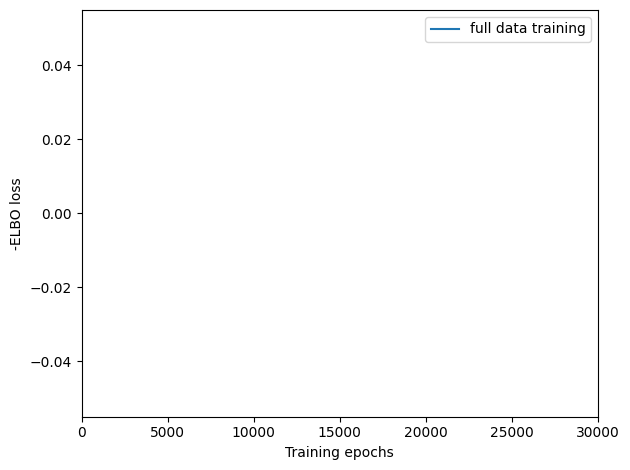

In [ ]:
mod.train(max_epochs=30000,
          # train using full data (batch_size=None)
          batch_size=None,
          # use all data points in training because
          # we need to estimate cell abundance at all locations
          train_size=1,
          accelerator="cuda"         )

# plot ELBO loss history during training, removing first 100 epochs from the plot
mod.plot_history(30000)
plt.legend(labels=['full data training']);

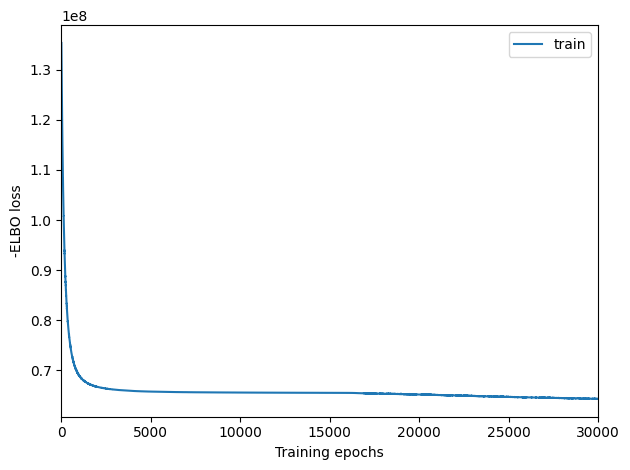

In [ ]:
mod.plot_history()

## 导出

In [ ]:
# In this section, we export the estimated cell abundance (summary of the posterior distribution).
adata = mod.export_posterior(
    adata, sample_kwargs={'num_samples': 1000, 'batch_size': mod.adata.n_obs, 'accelerator': 'cuda'}
)

# Save model
mod.save("./visum/reference_signatures/mod_pred_intecaf", overwrite=True)

# Save anndata object with results
adata.write("./visum/LN inte.h5ad")

Sampling local variables, batch:   0%|          | 0/1 [00:00<?, ?it/s]

Sampling global variables, sample:   0%|          | 0/999 [00:00<?, ?it/s]

In [ ]:
# adata = mod.export_posterior(
#     adata, sample_kwargs={'num_samples': 1000, 'batch_size': mod.adata.n_obs, 'accelerator': 'cuda'}
# )

Sampling local variables, batch:   0%|          | 0/1 [00:00<?, ?it/s]

Sampling global variables, sample:   0%|          | 0/999 [00:00<?, ?it/s]

In [ ]:
adata_st = sc.read_h5ad("./visum/LN inte.h5ad")
mod = cell2location.models.Cell2location.load("./visum/reference_signatures/mod_pred_LN", adata_st)

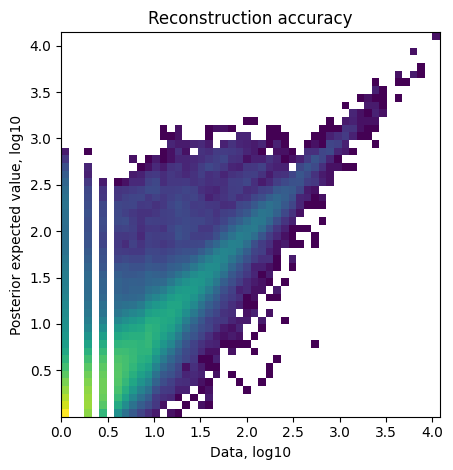

In [ ]:
mod.plot_QC()

In [ ]:
pd.DataFrame(adata.obsm['q05_cell_abundance_w_sf']).to_csv("./visum/st_cell2location_res_subtype_intecaf.csv")

In [ ]:
pd.DataFrame(adata.obsm['q05_cell_abundance_w_sf'])

                                    Arterial_EC         B  Basal_Epi  \
HNSCC14_HNSCC14_AAACAATCTACTAGCA-1     0.008079  0.030580   2.477014   
HNSCC14_HNSCC14_AAACAGAGCGACTCCT-1     0.000478  0.011913   2.256019   
HNSCC14_HNSCC14_AAACCGGGTAGGTACC-1     0.116977  0.019368   2.644791   
HNSCC14_HNSCC14_AAACCGTTCGTCCAGG-1     0.066176  0.279103   0.124850   
HNSCC14_HNSCC14_AAACCTCATGAAGTTG-1     0.049649  0.117733   0.804105   
...                                         ...       ...        ...   
HNSCC59_HNSCC59_TTGTTGTGTGTCAAGA-1     0.023494  0.225296   7.019543   
HNSCC59_HNSCC59_TTGTTTCACATCCAGG-1     0.026259  0.149612   4.538115   
HNSCC59_HNSCC59_TTGTTTCATTAGTCTA-1     0.007824  0.009433   0.007851   
HNSCC59_HNSCC59_TTGTTTCCATACAACT-1     0.040483  0.246646   8.550743   
HNSCC59_HNSCC59_TTGTTTGTATTACACG-1     0.000014  0.000160   0.000072   

                                    CAF_COL14A1  CD4T_CXCL13  CD4T_GZMB  \
HNSCC14_HNSCC14_AAACAATCTACTAGCA-1     0.092287     0.059782

In [ ]:
adata = sc.read_h5ad("./visum//LN inte.h5ad")
print(adata)

AnnData object with n_obs × n_vars = 4640 × 12120
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt', 'clusters', 'leiden', 'gene_niche', 'subtype', '_indices', '_scvi_batch', '_scvi_labels', 'Program_1', 'Program_2', 'Program_3', 'Program_4', 'Program_5', 'Program_6', 'Program_7', 'LAMA2_positive', 'LAMA2_expr', 'Arterial_EC', 'B', 'Basal_Epi', 'CAF_COL14A1', 'CD4T_CXCL13', 'CD4T_GZMB', 'CD4T_PTPRC', 'CD4T_naive', 'CD8T_CXCL13', 'CD8T_GZMA', 'CD8T_GZMK', 'CD8T_naive', 'CD8T_str', 'Capillary_EC', 'Cycling_CAF', 'Cycling_EC', 'Cycling_T', 'Diff_Epi', 'EC_ACKR1', 'EC_PGF', 'EMT_like_Epi', 'Hypoxia_Epi', 'Mac_CXCL5', 'Mac_FOLR2', 'Mac_SPP1', 'Mast', 'Mono_FCN1', 'NK', 'Neutrophil', 'Normal_Epi', 'Plasma', 'Prolif_Epi'

In [ ]:
c2l = pd.read_csv(
    "./visum/st_cell2location_res_LN_subtype_intecaf.csv",   # 修改为实际路径
    index_col=0,
)

In [ ]:
import pandas as pd
import numpy as np

# 1. 读取之前保存的 cell2location 结果
c2l = pd.read_csv(
    "./visum/st_cell2location_res_LN_subtype_intecaf.csv",   # 修改为实际路径
    index_col=0,
)

c2l.index = c2l.index.astype(str)

# 去掉细胞类型列名前的 c2l 前缀
# 例如 q05cell_abundance_w_sf_CAF_IL11 → CAF_IL11
c2l.columns = c2l.columns.str.replace(
    r"^q05_?cell_abundance_w_sf_",
    "",
    regex=True,
)

import re
import numpy as np
import pandas as pd

# 1. 清理连续重复的样本前缀，保留一份
def clean_spot_name(name):
    return re.sub(r"^([^_]+_)(?:\1)+", r"\1", str(name).strip())

adata_match = pd.Index([clean_spot_name(x) for x in adata.obs_names])

c2l_match = c2l.copy()
c2l_match.index = pd.Index([
    clean_spot_name(x) for x in c2l_match.index
])

# 2. 防止清理后出现重复名称，造成错误匹配
if not adata_match.is_unique:
    raise ValueError("adata 的匹配名称清理后有重复，请检查。")

if not c2l_match.index.is_unique:
    raise ValueError("CSV 的匹配名称清理后有重复，请检查。")

missing = adata_match.difference(c2l_match.index)

print(f"匹配成功：{len(adata_match) - len(missing)} / {adata.n_obs}")

if len(missing) > 0:
    print("adata 未匹配示例：", missing[:5].tolist())
    print("CSV 名称示例：", c2l_match.index[:5].tolist())
    raise ValueError("仍有未匹配 spot，请检查以上名称。")

# 3. 按 adata 的顺序提取旧结果
c2l_new = c2l_match.loc[adata_match].copy()

# 恢复为 adata 的原始名称，确保 obsm/obs 索引一致
c2l_new.index = adata.obs_names.copy()
c2l_new = c2l_new.apply(pd.to_numeric, errors="raise")
unknown_cols = [
    c for c in c2l_new.columns
    if "unknown" in str(c).lower()
]

print("删除Unknown列:", unknown_cols)

c2l_new = c2l_new.drop(
    columns=unknown_cols,
    errors="ignore"
)
if (
    not np.isfinite(c2l_new.to_numpy()).all()
    or (c2l_new.to_numpy() < 0).any()
):
    raise ValueError("c2l 结果存在缺失值、无穷值或负值。")

# 4. 写入
adata.obsm["q05_cell_abundance_w_sf"] = c2l_new.copy()
adata.obs[c2l_new.columns] = c2l_new

print("写入完成：", c2l_new.shape)

匹配成功：8466 / 8466
删除Unknown列: []
写入完成： (8466, 41)


In [ ]:
adata.write_h5ad("./visum/LN inte.h5ad")

In [ ]:
import pandas as pd
import re

cluster = pd.read_csv(
    "./visum/adata_clusters.csv",
    index_col=0,
    dtype=str
)

# 去掉重复的样本前缀，保留一个
def clean_name(x):
    return re.sub(r"^(HNSCC\d+_)(?:\1)+", r"\1", str(x))

cluster.index = cluster.index.map(clean_name)

# 构建 adata 的匹配键，不修改原始 obs_names
target_keys = pd.Index([
    clean_name(
        str(spot) if str(spot).startswith(f"{sample}_")
        else f"{sample}_{spot}"
    )
    for spot, sample in zip(adata.obs_names, adata.obs["sample"])
])

# 检查唯一性及匹配情况
if not cluster.index.is_unique or not target_keys.is_unique:
    raise ValueError("统一前缀后存在重复 spot 名，请先检查。")

labels = cluster["clusters"].reindex(target_keys)

if labels.isna().any():
    missing = target_keys[labels.isna()]
    raise ValueError(
        f"{len(missing)} 个 spot 未匹配或缺少标签，例如：{missing[:5].tolist()}"
    )

# 已按 adata 顺序对齐，写入分类变量
adata.obs["clusters"] = pd.Categorical(labels.to_numpy())

print(adata.obs["clusters"].value_counts())
print(pd.crosstab(adata.obs["sample"], adata.obs["clusters"]))

# 保存为新文件
# adata.write_h5ad("./visum/st_with_clusters.h5ad")

clusters
5     571
11    534
3     518
12    503
1     378
2     365
9     348
10    333
7     308
0     294
8     223
4     176
6      98
Name: count, dtype: int64
clusters    0    1   10   11   12    2    3    4    5   6    7    8    9
sample                                                                  
HNSCC14   294  378    0    0    0  365  518    0  570  97    0    0    0
HNSCC59     0    0  333  534  503    0    0  176    1   1  308  223  348


In [ ]:
adata.write_h5ad("./visum/LN inte.h5ad")

In [ ]:
import numpy as np
import pandas as pd
from scipy import sparse

x = adata.obsm["q05_cell_abundance_w_sf"]

if isinstance(x, pd.DataFrame):
    # 总丰度为 0 的 spot 保留为全 0
    prop = x.div(x.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)
elif sparse.issparse(x):
    totals = np.asarray(x.sum(axis=1)).ravel()
    inv = np.divide(
        1.0, totals,
        out=np.zeros_like(totals, dtype=float),
        where=totals != 0
    )
    prop = sparse.diags(inv).dot(x).tocsr()
else:
    x = np.asarray(x)
    totals = x.sum(axis=1, keepdims=True)
    prop = np.divide(
        x, totals,
        out=np.zeros_like(x, dtype=float),
        where=totals != 0
    )

adata.obsm["q05_cell_abundance_w_sf_norm"] = prop

# 检查：非零 spot 的行总和应约为 1
print(np.asarray(prop.sum(axis=1)).ravel()[:10])

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [ ]:
# adata.obs[adata.uns['mod']['factor_names']] = adata.obsm['q05_cell_abundance_w_sf']
# adata.obs[adata.uns['mod']['factor_names']] = adata.obsm['q05_cell_abundance_w_sf_norm']
import pandas as pd

norm = adata.obsm["q05_cell_abundance_w_sf_norm"]

# 前面导入的原始 c2l 矩阵已包含细胞类型列名
celltypes = adata.obsm["q05_cell_abundance_w_sf"].columns.tolist()

if isinstance(norm, pd.DataFrame):
    # 按 spot 和细胞类型名称对齐
    norm_df = norm.loc[adata.obs_names, celltypes].copy()
else:
    # 数组的列顺序应与原始 c2l 矩阵一致
    norm_df = pd.DataFrame(
        norm,
        index=adata.obs_names,
        columns=celltypes,
    )

# 写入 obs；同名列会更新为归一化后的值
adata.obs[celltypes] = norm_df

print(adata.obs[celltypes].head())

                    Arterial_EC         B  Basal_Epi  CD4T_CXCL13  CD4T_GZMB  \
AAACAAGTATCTCCCA-1     0.001702  0.032228   0.000360     0.006187   0.007263   
AAACAATCTACTAGCA-1     0.020191  0.042556   0.003230     0.006080   0.009839   
AAACACCAATAACTGC-1     0.000843  0.018926   0.252100     0.003819   0.005761   
AAACAGAGCGACTCCT-1     0.053568  0.053283   0.001099     0.009713   0.025478   
AAACAGCTTTCAGAAG-1     0.002013  0.105689   0.166831     0.006170   0.010334   

                    CD4T_PTPRC  CD4T_naive  CD8T_CXCL13  CD8T_GZMA  CD8T_GZMK  \
AAACAAGTATCTCCCA-1    0.001328    0.018820     0.005141   0.012399   0.009386   
AAACAATCTACTAGCA-1    0.001507    0.016155     0.009663   0.010066   0.013101   
AAACACCAATAACTGC-1    0.007602    0.008003     0.007094   0.005882   0.011024   
AAACAGAGCGACTCCT-1    0.002100    0.026721     0.037696   0.021878   0.050989   
AAACAGCTTTCAGAAG-1    0.005287    0.016842     0.011822   0.009889   0.013667   

                    ...  Stem_li

In [ ]:
# adata.uns["spatial"] = {
#     **adata_1.uns["spatial"],
#     **adata_2.uns["spatial"]
# }

In [ ]:
adata.X =adata.layers["counts"].copy()

In [ ]:
sc.pp.normalize_total(
    adata,
    target_sum=1e4
)

sc.pp.log1p(adata)

### plot

In [ ]:
adata=sc.read_h5ad("./visum/data/LN inte.h5ad")

In [ ]:
adata.raw=adata.copy()

In [ ]:
adata.X =adata.layers["counts"].copy()

LAMA2 颜色范围：0–1.5614


/tmp/ipykernel_70522/412117543.py:54: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  fig = sc.pl.spatial(


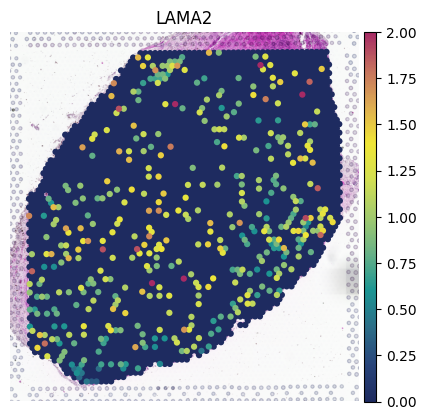

保存完成：
visum/figure/st_ln_figure/HNSCC14_LAMA2_spatial.tiff
visum/figure/st_ln_figure/HNSCC14_LAMA2_spatial.png


In [ ]:
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# =========================
# 1. 参数
# =========================
SAMPLE = "HNSCC14"
GENE = "LAMA2"

# 输出目录
outdir = Path("./visum/figure/st_ln_figure")
outdir.mkdir(parents=True, exist_ok=True)

# 当前切片
adata_HNSCC14 = adata[adata.obs["sample"] == SAMPLE].copy()

# =========================
# 2. 检查基因是否存在
# =========================
if adata_HNSCC14.raw is not None and GENE in adata_HNSCC14.raw.var_names:
    use_raw = True
    expr = adata_HNSCC14.raw[:, GENE].X
else:
    use_raw = False
    if GENE not in adata_HNSCC14.var_names:
        raise ValueError(f"{GENE} 不在 adata.var_names 或 adata.raw.var_names 中")
    expr = adata_HNSCC14[:, GENE].X

# 转成一维数组
if hasattr(expr, "toarray"):
    expr = expr.toarray().ravel()
else:
    expr = np.asarray(expr).ravel()

expr = expr[np.isfinite(expr)]

if expr.size == 0:
    raise ValueError(f"{GENE} 没有有效表达值")

# =========================
# 3. 统一颜色范围
# =========================
common_vmax = np.percentile(expr, 99.2)
if common_vmax <= 0:
    common_vmax = expr.max() if expr.max() > 0 else 1.0

print(f"{GENE} 颜色范围：0–{common_vmax:.4f}")

# =========================
# 4. 绘图
# =========================
fig = sc.pl.spatial(
    adata_HNSCC14,
    library_id=SAMPLE,
    color=[GENE],
    spot_size=150,
    img_key="hires",
    vmin=0,
    vmax="2",   # 若你想固定也可直接改成具体数值，例如 0.4
    cmap=cmap,          # 这里沿用你前面定义好的 cmap
    frameon=False,
    use_raw=use_raw,
    return_fig=True
)

# 可选：标题改得更简洁
ax = fig.axes[0]
ax.set_title(GENE, fontsize=16)

# =========================
# 5. 保存
# =========================
tiff_path = outdir / f"{SAMPLE}_{GENE}_spatial.tiff"
png_path = outdir / f"{SAMPLE}_{GENE}_spatial.png"

fig.savefig(
    tiff_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
    pil_kwargs={"compression": "tiff_lzw"}
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("保存完成：")
print(tiff_path)
print(png_path)

plt.show()

LAMA2 颜色范围：0–0.7404


/tmp/ipykernel_70522/626391425.py:54: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  fig = sc.pl.spatial(


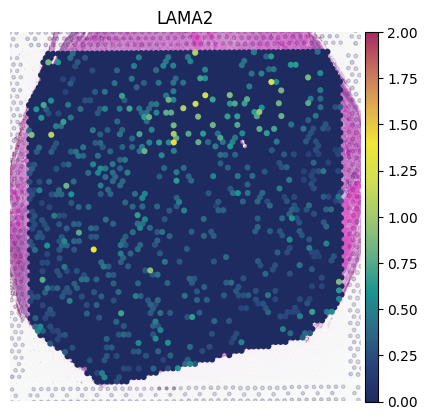

保存完成：
visum/figure/st_ln_figure/HNSCC59_LAMA2_spatial.tiff
visum/figure/st_ln_figure/HNSCC59_LAMA2_spatial.png


In [ ]:
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# =========================
# 1. 参数
# =========================
SAMPLE = "HNSCC59"
GENE = "LAMA2"

# 输出目录
outdir = Path("./visum/figure/st_ln_figure")
outdir.mkdir(parents=True, exist_ok=True)

# 当前切片
adata_HNSCC14 = adata[adata.obs["sample"] == SAMPLE].copy()

# =========================
# 2. 检查基因是否存在
# =========================
if adata_HNSCC14.raw is not None and GENE in adata_HNSCC14.raw.var_names:
    use_raw = True
    expr = adata_HNSCC14.raw[:, GENE].X
else:
    use_raw = False
    if GENE not in adata_HNSCC14.var_names:
        raise ValueError(f"{GENE} 不在 adata.var_names 或 adata.raw.var_names 中")
    expr = adata_HNSCC14[:, GENE].X

# 转成一维数组
if hasattr(expr, "toarray"):
    expr = expr.toarray().ravel()
else:
    expr = np.asarray(expr).ravel()

expr = expr[np.isfinite(expr)]

if expr.size == 0:
    raise ValueError(f"{GENE} 没有有效表达值")

# =========================
# 3. 统一颜色范围
# =========================
common_vmax = np.percentile(expr, 99.2)
if common_vmax <= 0:
    common_vmax = expr.max() if expr.max() > 0 else 1.0

print(f"{GENE} 颜色范围：0–{common_vmax:.4f}")

# =========================
# 4. 绘图
# =========================
fig = sc.pl.spatial(
    adata_HNSCC14,
    library_id=SAMPLE,
    color=[GENE],
    spot_size=150,
    img_key="hires",
    vmin=0,
    vmax="2",   # 若你想固定也可直接改成具体数值，例如 0.4
    cmap=cmap,          # 这里沿用你前面定义好的 cmap
    frameon=False,
    use_raw=use_raw,
    return_fig=True
)

# 可选：标题改得更简洁
ax = fig.axes[0]
ax.set_title(GENE, fontsize=16)

# =========================
# 5. 保存
# =========================
tiff_path = outdir / f"{SAMPLE}_{GENE}_spatial.tiff"
png_path = outdir / f"{SAMPLE}_{GENE}_spatial.png"

fig.savefig(
    tiff_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
    pil_kwargs={"compression": "tiff_lzw"}
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("保存完成：")
print(tiff_path)
print(png_path)

plt.show()

In [ ]:
adata

AnnData object with n_obs × n_vars = 4640 × 12179
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt', 'clusters', 'leiden', 'gene_niche', 'subtype', '_indices', '_scvi_batch', '_scvi_labels', 'Arterial_EC', 'B', 'Basal_Epi', 'CAF_COL14A1', 'CD4T_CXCL13', 'CD4T_GZMB', 'CD4T_PTPRC', 'CD4T_naive', 'CD8T_CXCL13', 'CD8T_GZMA', 'CD8T_GZMK', 'CD8T_naive', 'CD8T_str', 'Capillary_EC', 'Cycling_CAF', 'Cycling_EC', 'Cycling_T', 'Diff_Epi', 'EC_ACKR1', 'EC_PGF', 'EMT_like_Epi', 'Hypoxia_Epi', 'Mac_CXCL5', 'Mac_FOLR2', 'Mac_SPP1', 'Mast', 'Mono_FCN1', 'NK', 'Neutrophil', 'Normal_Epi', 'Plasma', 'Prolif_Epi', 'Stem_like_Epi', 'Str_Epi', 'Treg', 'Unknown', 'apCAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'mregDC', 'myCAF_CTHRC1', 'qCAF', 'qE

In [ ]:
# adata.obs.drop(columns=["qCAF"], inplace=True)

绘制: ['myCAF_COL14A1', 'Cycling_CAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'myCAF_CTHRC1', 'apCAF']
绘制: ['myCAF_COL14A1', 'Cycling_CAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'myCAF_CTHRC1', 'apCAF']
统一颜色范围：0–0.3579


/tmp/ipykernel_1070/2294969419.py:51: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


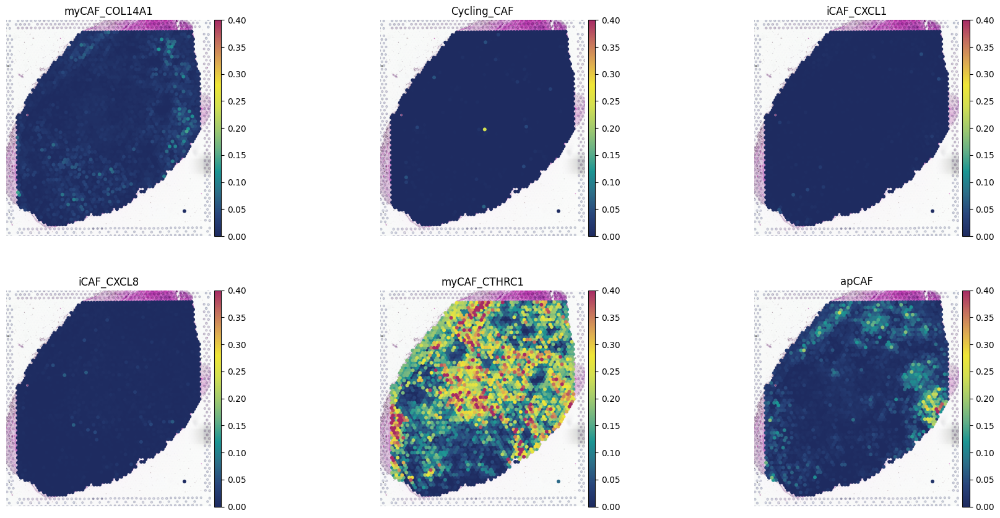

In [ ]:
import scanpy as sc
import matplotlib.pyplot as plt


# 上皮亚型
epi_types = [
    "myCAF_COL14A1",
    "Cycling_CAF",
    "iCAF_CXCL1",
    "iCAF_CXCL8",
    "myCAF_CTHRC1",
    "apCAF",

]

# 当前slice
adata_HNSCC14 = adata[adata.obs["sample"]=="HNSCC14"]


# 检查存在的亚型
epi_types = [
    x for x in epi_types
    if x in adata_HNSCC14.obs.columns
]

print("绘制:", epi_types)


# 检查存在的亚型
epi_types = [
    x for x in epi_types
    if x in adata_HNSCC14.obs.columns
]

print("绘制:", epi_types)


# 所有上皮亚型共同计算颜色上限
values = adata_HNSCC14.obs[epi_types].to_numpy(dtype=float)
values = values[np.isfinite(values)]

if values.size == 0:
    raise ValueError("没有可用于绘图的有效丰度值")

common_vmax = np.percentile(values, 99.2)
if common_vmax <= 0:
    common_vmax = values.max() if values.max() > 0 else 1.0

print(f"统一颜色范围：0–{common_vmax:.4f}")

sc.pl.spatial(
    adata_HNSCC14,
    library_id="HNSCC14",
    color=epi_types,
    ncols=3,
    spot_size=150,
    img_key="hires",
    vmin=0,
    vmax=0.4,      # 所有面板共用相同数值
    cmap=cmap,#"RdBu_r"
    frameon=False
)

绘制: ['myCAF_COL14A1', 'Cycling_CAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'myCAF_CTHRC1', 'apCAF', 'CAF']
统一颜色范围：0–0.3835


/tmp/ipykernel_1070/3077935348.py:46: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


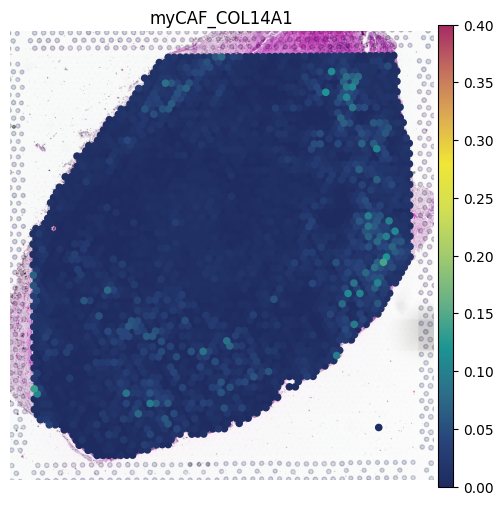

/tmp/ipykernel_1070/3077935348.py:46: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


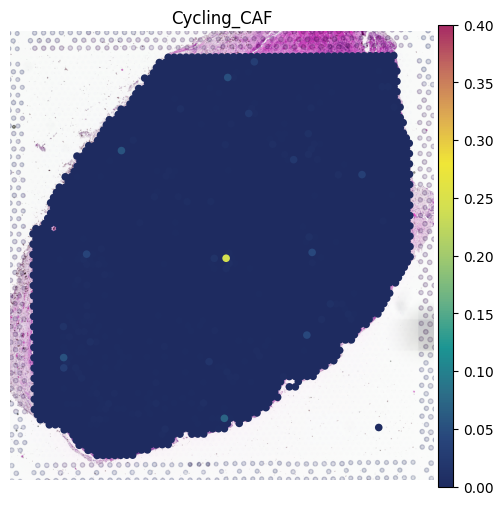

/tmp/ipykernel_1070/3077935348.py:46: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


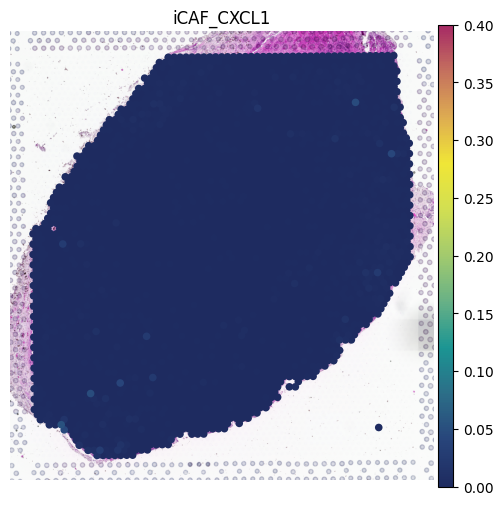

/tmp/ipykernel_1070/3077935348.py:46: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


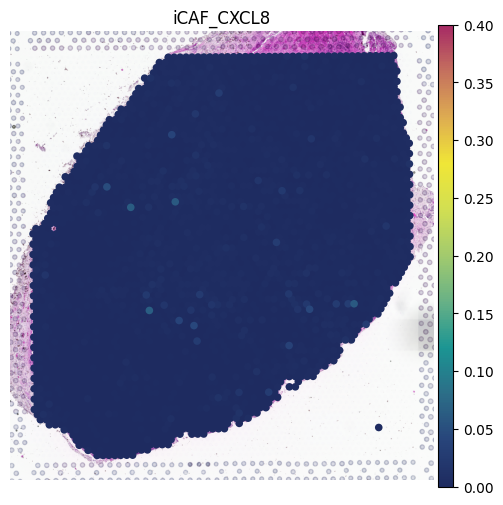

/tmp/ipykernel_1070/3077935348.py:46: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


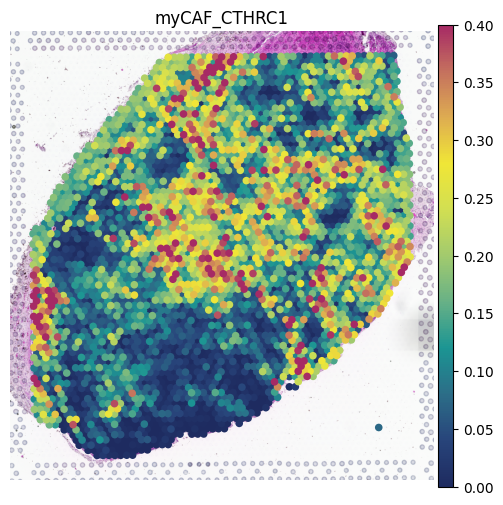

/tmp/ipykernel_1070/3077935348.py:46: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


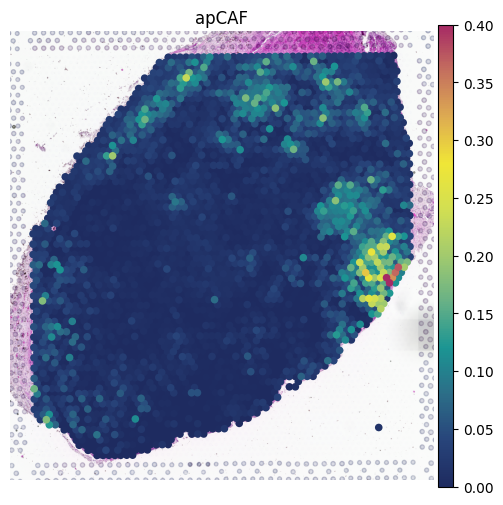

/tmp/ipykernel_1070/3077935348.py:46: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


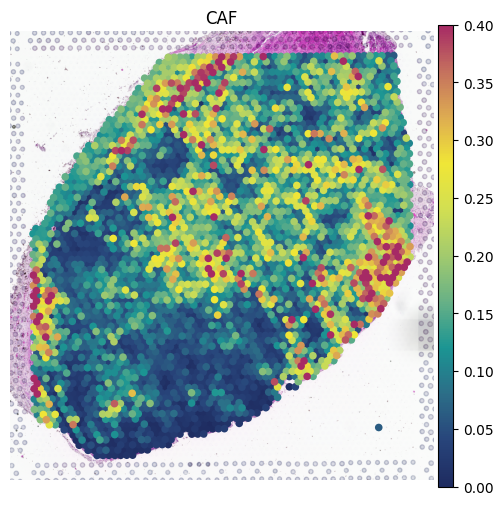

In [ ]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
from pathlib import Path

caf_types = [
    "myCAF_COL14A1",
    "Cycling_CAF",
    "iCAF_CXCL1",
    "iCAF_CXCL8",
    "myCAF_CTHRC1",
    "apCAF",
    "CAF"
]

sample = "HNSCC14"
slide = adata[adata.obs["sample"] == sample].copy()

outdir = Path("./visum/st_ln_figure") / sample
outdir.mkdir(parents=True, exist_ok=True)

# 保留存在的亚型
caf_types = [x for x in caf_types if x in slide.obs.columns]
if not caf_types:
    raise ValueError("obs 中未找到指定的 CAF 亚型")

print("绘制:", caf_types)

# 所有亚型共同计算颜色上限
values = slide.obs[caf_types].to_numpy(dtype=float)
values = values[np.isfinite(values)]

if values.size == 0:
    raise ValueError("没有可用于绘图的有效丰度值")

common_vmax = np.percentile(values, 99.2)
if common_vmax <= 0:
    common_vmax = values.max() if values.max() > 0 else 1.0

print(f"统一颜色范围：0–{common_vmax:.4f}")

# 每个亚型单独绘制、保存
for celltype in caf_types:
    fig, ax = plt.subplots(figsize=(6, 6))

    sc.pl.spatial(
        slide,
        library_id=sample,
        color=celltype,
        spot_size=150,
        img_key="hires",
        vmin=0,
        vmax="0.4",
        cmap=cmap,
        frameon=False,
        title=celltype,
        ax=ax,
        show=False,
    )

    fig.savefig(
        outdir / f"{sample}_{celltype}.tiff",
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
        pil_kwargs={"compression": "tiff_lzw"},
    )

    plt.show()
    plt.close(fig)

绘制: ['myCAF_COL14A1', 'Cycling_CAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'myCAF_CTHRC1', 'apCAF']
绘制: ['myCAF_COL14A1', 'Cycling_CAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'myCAF_CTHRC1', 'apCAF']
统一颜色范围：0–0.0987


/tmp/ipykernel_1070/4288193808.py:52: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


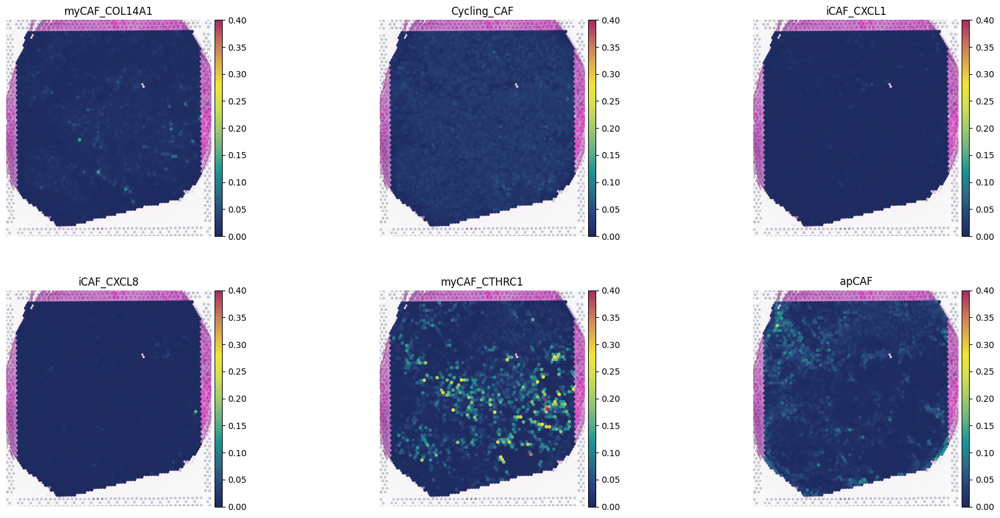

In [ ]:
import scanpy as sc
import matplotlib.pyplot as plt


# 上皮亚型
epi_types = [
    "myCAF_COL14A1",
    "Cycling_CAF",
    "iCAF_CXCL1",
    "iCAF_CXCL8",
    "myCAF_CTHRC1",
    "apCAF",

]


# 当前slice
adata_HNSCC59 = adata[adata.obs["sample"]=="HNSCC59"]


# 检查存在的亚型
epi_types = [
    x for x in epi_types
    if x in adata_HNSCC59.obs.columns
]

print("绘制:", epi_types)


# 检查存在的亚型
epi_types = [
    x for x in epi_types
    if x in adata_HNSCC59.obs.columns
]

print("绘制:", epi_types)


# 所有上皮亚型共同计算颜色上限
values = adata_HNSCC59.obs[epi_types].to_numpy(dtype=float)
values = values[np.isfinite(values)]

if values.size == 0:
    raise ValueError("没有可用于绘图的有效丰度值")

common_vmax = np.percentile(values, 99.2)
if common_vmax <= 0:
    common_vmax = values.max() if values.max() > 0 else 1.0

print(f"统一颜色范围：0–{common_vmax:.4f}")

sc.pl.spatial(
    adata_HNSCC59,
    library_id="HNSCC59",
    color=epi_types,
    ncols=3,
    spot_size=150,
    img_key="hires",
    vmin=0,
    vmax="0.4",      # 所有面板共用相同数值
    cmap=cmap,
    frameon=False

)

绘制: ['myCAF_COL14A1', 'Cycling_CAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'myCAF_CTHRC1', 'apCAF', 'CAF']
统一颜色范围：0–0.1118


/tmp/ipykernel_70522/3973135806.py:46: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


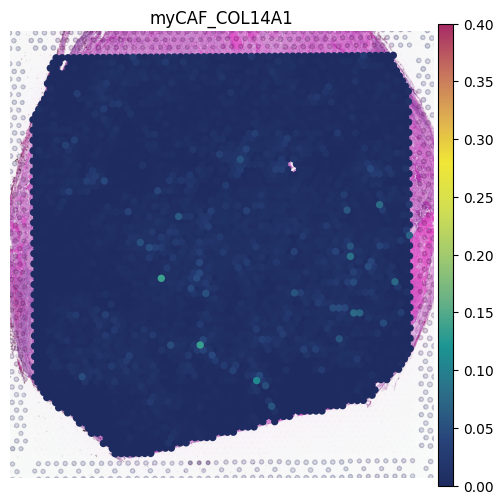

/tmp/ipykernel_70522/3973135806.py:46: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


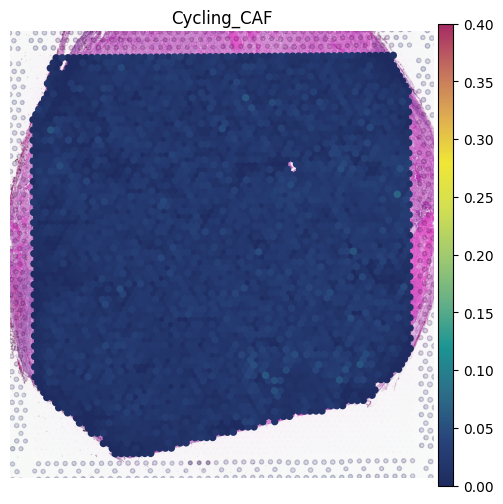

/tmp/ipykernel_70522/3973135806.py:46: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


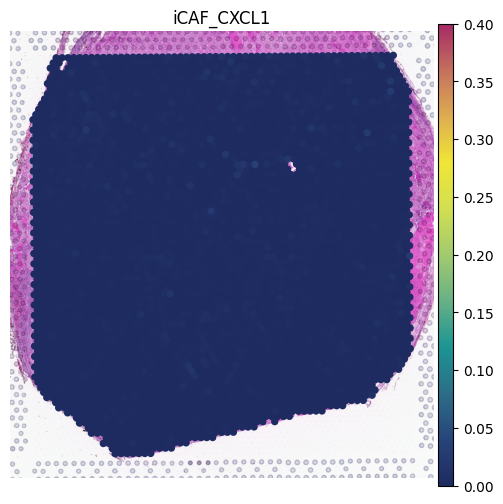

/tmp/ipykernel_70522/3973135806.py:46: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


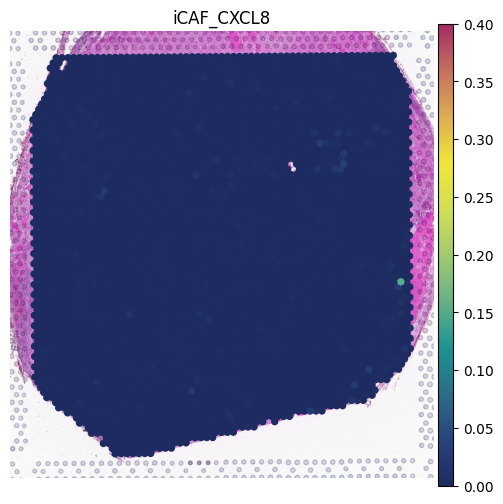

/tmp/ipykernel_70522/3973135806.py:46: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


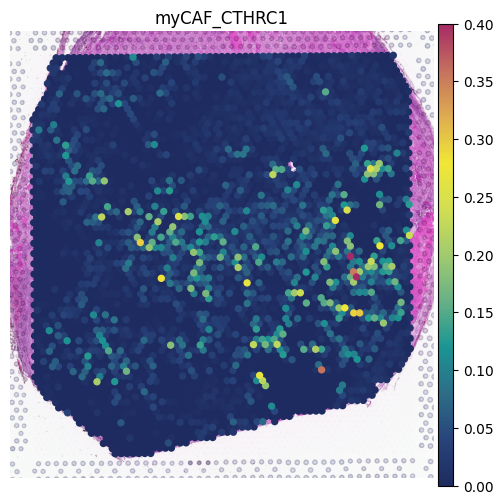

/tmp/ipykernel_70522/3973135806.py:46: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


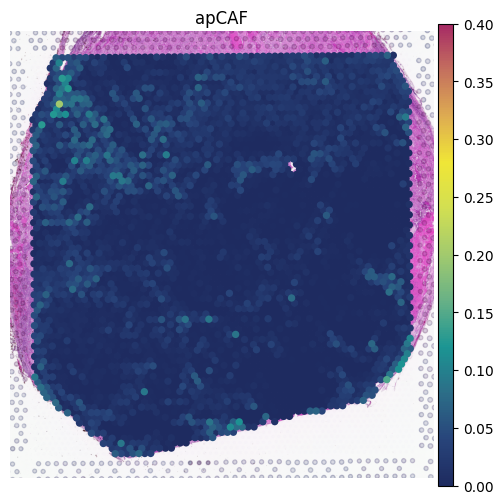

/tmp/ipykernel_70522/3973135806.py:46: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


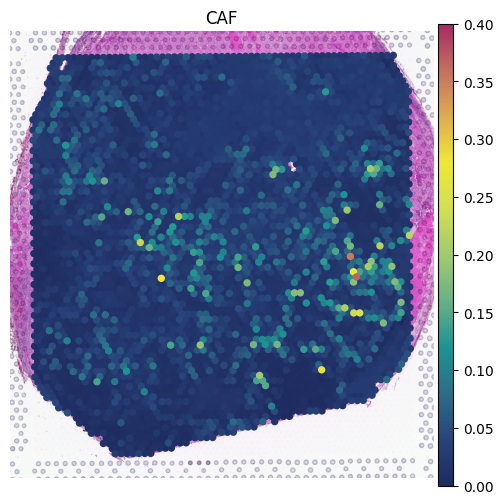

In [ ]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
from pathlib import Path

caf_types = [
    "myCAF_COL14A1",
    "Cycling_CAF",
    "iCAF_CXCL1",
    "iCAF_CXCL8",
    "myCAF_CTHRC1",
    "apCAF",
    "CAF",

]

sample = "HNSCC59"
slide = adata[adata.obs["sample"] == sample].copy()

outdir = Path("./visum/st_ln_figure") / sample
outdir.mkdir(parents=True, exist_ok=True)

# 保留存在的亚型
caf_types = [x for x in caf_types if x in slide.obs.columns]
if not caf_types:
    raise ValueError("obs 中未找到指定的 CAF 亚型")

print("绘制:", caf_types)

# 所有亚型共同计算颜色上限
values = slide.obs[caf_types].to_numpy(dtype=float)
values = values[np.isfinite(values)]

if values.size == 0:
    raise ValueError("没有可用于绘图的有效丰度值")

common_vmax = np.percentile(values, 99.2)
if common_vmax <= 0:
    common_vmax = values.max() if values.max() > 0 else 1.0

print(f"统一颜色范围：0–{common_vmax:.4f}")

# 每个亚型单独绘制、保存
for celltype in caf_types:
    fig, ax = plt.subplots(figsize=(6, 6))

    sc.pl.spatial(
        slide,
        library_id=sample,
        color=celltype,
        spot_size=150,
        img_key="hires",
        vmin=0,
        vmax="0.4",
        cmap=cmap,
        frameon=False,
        title=celltype,
        ax=ax,
        show=False,
    )

    fig.savefig(
        outdir / f"{sample}_{celltype}.tiff",
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
        pil_kwargs={"compression": "tiff_lzw"},
    )

    plt.show()
    plt.close(fig)

In [ ]:
adata

AnnData object with n_obs × n_vars = 4640 × 12179
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt', 'clusters', 'leiden', 'gene_niche', 'subtype', '_indices', '_scvi_batch', '_scvi_labels', 'Arterial_EC', 'B', 'Basal_Epi', 'CAF_COL14A1', 'CD4T_CXCL13', 'CD4T_GZMB', 'CD4T_PTPRC', 'CD4T_naive', 'CD8T_CXCL13', 'CD8T_GZMA', 'CD8T_GZMK', 'CD8T_naive', 'CD8T_str', 'Capillary_EC', 'Cycling_CAF', 'Cycling_EC', 'Cycling_T', 'Diff_Epi', 'EC_ACKR1', 'EC_PGF', 'EMT_like_Epi', 'Hypoxia_Epi', 'Mac_CXCL5', 'Mac_FOLR2', 'Mac_SPP1', 'Mast', 'Mono_FCN1', 'NK', 'Neutrophil', 'Normal_Epi', 'Plasma', 'Prolif_Epi', 'Stem_like_Epi', 'Str_Epi', 'Treg', 'Unknown', 'apCAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'mregDC', 'myCAF_CTHRC1', 'qCAF', 'qE

/tmp/ipykernel_1594/2219905515.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()


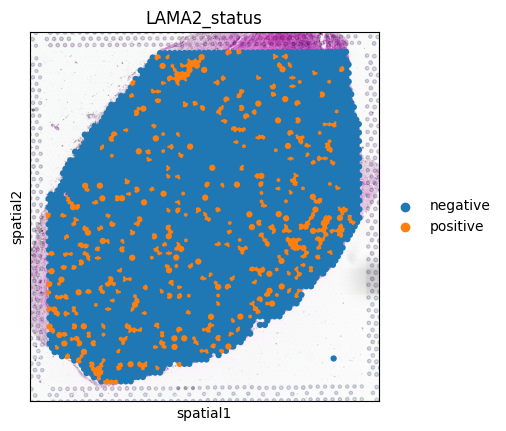

In [ ]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC14"],
    color="LAMA2_status",
    library_id="HNSCC14",
    img_key="hires",
    spot_size=150,
    cmap="RdBu_r",
    vmin=vmin,
    vmax="3"
)

/tmp/ipykernel_1594/751519860.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()


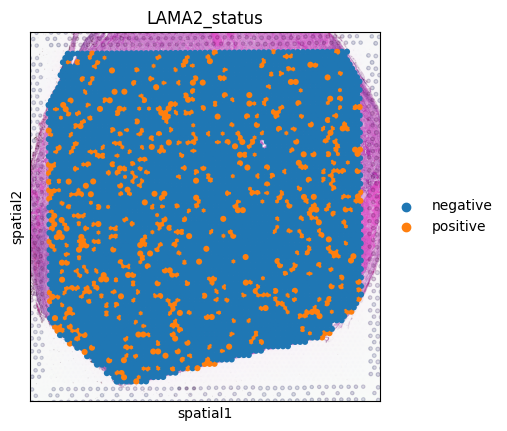

In [ ]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC59"],
    color="LAMA2_status",
    library_id="HNSCC59",
    img_key="hires",
    spot_size=150,
    cmap="RdBu_r",
    vmin=vmin,
    vmax="3"
)

## celltype c2l


In [ ]:
adata_ref = sc.read_h5ad("./1.rawdata/sc/Final_rebuilt_subtype.h5ad")
adata_ref.X = adata_ref.layers['counts'].copy()

In [ ]:
adata_ref.obs = adata_ref.obs.replace("T/NK", "T_NK")

/tmp/ipykernel_707/1808746426.py:1: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  adata_ref.obs = adata_ref.obs.replace("T/NK", "T_NK")


In [ ]:
adata_ref.obs["celltype"].unique()

['Plasma', 'Myeloid', 'T_NK', 'Neutrophil', 'CAF', 'Endo', 'B', 'Mast', 'Epi']
Categories (9, object): ['B', 'CAF', 'Endo', 'Epi', ..., 'Myeloid', 'Neutrophil', 'Plasma', 'T_NK']

In [ ]:
import cell2location
from cell2location.models import RegressionModel

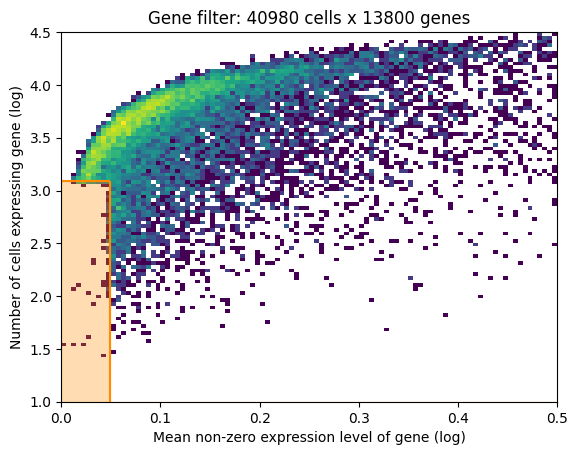

In [ ]:
from cell2location.utils.filtering import filter_genes
selected = filter_genes(adata_ref, cell_count_cutoff=5, cell_percentage_cutoff2=0.03, nonz_mean_cutoff=1.12)

# # filter the object
adata_ref = adata_ref[:, selected].copy()

In [ ]:
cell2location.models.RegressionModel.setup_anndata(adata=adata_ref,#参考数据集
      batch_key='orig.ident',#adata.obs中批次/sample列。
      labels_key='celltype',# celltype注释列
      categorical_covariate_keys=None#矫正技术因素（例如platform, 3' vs 5', donor effect）
      )

In [ ]:
from cell2location.models import RegressionModel
mod = RegressionModel(adata_ref)

In [ ]:
# view anndata_setup as a sanity check
mod.view_anndata_setup()

Anndata setup with scvi-tools version 1.5.1.

Setup via `RegressionModel.setup_anndata` with arguments:

{
│   'layer': None,
│   'batch_key': 'orig.ident',
│   'labels_key': 'celltype',
│   'categorical_covariate_keys': None,
│   'continuous_covariate_keys': None
}

         Summary Statistics         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃     Summary Stat Key     ┃ Value ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│         n_batch          │   6   │
│         n_cells          │ 40980 │
│ n_extra_categorical_covs │   0   │
│ n_extra_continuous_covs  │   0   │
│         n_labels         │   9   │
│          n_vars          │ 13800 │
└──────────────────────────┴───────┘

               Data Registry                
┏━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Registry Key ┃    scvi-tools Location    ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│      X       │          adata.X          │
│    batch     │ adata.obs['_scvi_batch']  │
│    ind_x     │   adata.obs['_indices']   │
│    labels    │ adata.obs['_scvi_labels'] │
└──────────────┴───────────────────────────┘

                     batch State Registry                     
┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃     Source Location     ┃ Categories ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['orig.ident'] │    NO_1    │          0          │
│                         │    NO_2    │          1          │
│                         │    NO_3    │          2          │
│                         │  Smoke_1   │          3          │
│                         │  Smoke_2   │          4          │
│                         │  Smoke_3   │          5          │
└─────────────────────────┴────────────┴─────────────────────┘

                   labels State Registry                    
┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃    Source Location    ┃ Categories ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['celltype'] │     B      │          0          │
│                       │    CAF     │          1          │
│                       │    Endo    │          2          │
│                       │    Epi     │          3          │
│                       │    Mast    │          4          │
│                       │  Myeloid   │          5          │
│                       │ Neutrophil │          6          │
│                       │   Plasma   │          7          │
│                       │    T_NK    │          8          │
└───────────────────────┴────────────┴─────────────────────┘

In [ ]:
mod.train(max_epochs=1000,accelerator="cuda")

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/configuration_validator.py:68: You passed in a `val_dataloader` but have no `validation_step`. Skipping val loop.
INFO: You are using a CUDA device ('NVIDIA A100-SXM4-

Training:   0%|          | 0/1000 [00:00<?, ?it/s]

INFO: `Trainer.fit` stopped: `max_epochs=1000` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=1000` reached.


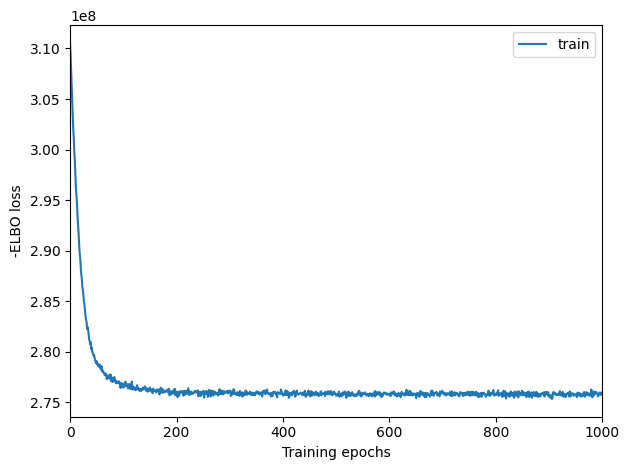

In [ ]:
mod.plot_history()

In [ ]:
# In this section, we export the estimated cell abundance (summary of the posterior distribution).
adata_ref = mod.export_posterior(
    adata_ref, sample_kwargs={'num_samples': 1000, 'batch_size': 2500, 'accelerator': 'cuda'}
)
adata_ref = mod.export_posterior(
    adata_ref, use_quantiles=True,
    # choose quantiles
    add_to_varm=["q05","q50", "q95", "q0001"],
    sample_kwargs={'batch_size': 2500, 'accelerator': 'cuda'}
)
# Save model
mod.save("./visum/reference_signatures/mob_train_celltype", overwrite=True)

# Save anndata object with results
adata_ref.write("./visum/sc_cell2location_celltype.h5ad")

Sampling local variables, batch:   0%|          | 0/17 [00:00<?, ?it/s]

Sampling global variables, sample:   0%|          | 0/999 [00:00<?, ?it/s]

In [ ]:
# #模型和输出的h5ad，可以像这样加载:
# adata_ref = sc.read_h5ad("./visum/sc_cell2location_celltype.h5ad")
# mod = cell2location.models.RegressionModel.load("./visum/reference_signatures/mob_train_celltype", adata_ref)

In [ ]:
# export estimated expression in each cluster
if 'means_per_cluster_mu_fg' in adata_ref.varm.keys():
    inf_aver = adata_ref.varm['means_per_cluster_mu_fg'][[f'means_per_cluster_mu_fg_{i}'
                                    for i in adata_ref.uns['mod']['factor_names']]].copy()
else:
    inf_aver = adata_ref.var[[f'means_per_cluster_mu_fg_{i}'
                                    for i in adata_ref.uns['mod']['factor_names']]].copy()
inf_aver.columns = adata_ref.uns['mod']['factor_names']
inf_aver.iloc[0:5, 0:15]

                 B       CAF       Endo       Epi      Mast   Myeloid  \
gene_id                                                                 
A1BG-AS1  0.016656  0.116985   0.014377  0.001778  0.069093  0.056265   
A2M       0.001708  0.993461  12.727815  0.009436  0.447519  2.748027   
A2ML1     0.002825  0.003251   0.000956  0.295427  0.004400  0.001442   
A4GALT    0.004520  0.777590   0.899679  0.835425  0.012169  0.023658   
AAAS      0.032419  0.217443   0.113041  0.399315  0.063087  0.092096   

          Neutrophil    Plasma      T_NK  
gene_id                                   
A1BG-AS1    0.000827  0.034941  0.026253  
A2M         0.003777  0.026881  0.030783  
A2ML1       0.002612  0.003284  0.000356  
A4GALT      0.001864  0.007805  0.003188  
AAAS        0.001226  0.172611  0.045380  

In [ ]:
adata=sc.read_h5ad("./visum/data/st.h5ad")

In [ ]:
# find shared genes and subset both anndata and reference signatures
intersect = np.intersect1d(adata.var_names, inf_aver.index)
adata = adata[:, intersect].copy()
inf_aver = inf_aver.loc[intersect, :].copy()

# prepare anndata for cell2location model
cell2location.models.Cell2location.setup_anndata(adata=adata,layer="counts",batch_key="sample" )

In [ ]:
# create and train the model
mod = cell2location.models.Cell2location(
    adata, cell_state_df=inf_aver,
    # the expected average cell abundance: tissue-dependent
    # hyper-prior which can be estimated from paired histology:
    N_cells_per_location=30,
    # hyperparameter controlling normalisation of
    # within-experiment variation in RNA detection:
    detection_alpha=20
)
mod.view_anndata_setup()

Anndata setup with scvi-tools version 1.5.1.

Setup via `Cell2location.setup_anndata` with arguments:

{
│   'layer': 'counts',
│   'batch_key': 'sample',
│   'labels_key': None,
│   'categorical_covariate_keys': None,
│   'continuous_covariate_keys': None
}

         Summary Statistics         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃     Summary Stat Key     ┃ Value ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│         n_batch          │   2   │
│         n_cells          │ 4640  │
│ n_extra_categorical_covs │   0   │
│ n_extra_continuous_covs  │   0   │
│         n_labels         │   1   │
│          n_vars          │ 12126 │
└──────────────────────────┴───────┘

               Data Registry                
┏━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Registry Key ┃    scvi-tools Location    ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│      X       │  adata.layers['counts']   │
│    batch     │ adata.obs['_scvi_batch']  │
│    ind_x     │   adata.obs['_indices']   │
│    labels    │ adata.obs['_scvi_labels'] │
└──────────────┴───────────────────────────┘

                   batch State Registry                   
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃   Source Location   ┃ Categories ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['sample'] │  HNSCC14   │          0          │
│                     │  HNSCC59   │          1          │
└─────────────────────┴────────────┴─────────────────────┘

                     labels State Registry                      
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃      Source Location      ┃ Categories ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['_scvi_labels'] │     0      │          0          │
└───────────────────────────┴────────────┴─────────────────────┘

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/configuration_validator.py:68: You passed in a `val_dataloader` but have no `validation_step`. Skipping val loop.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:

Training:   0%|          | 0/30000 [00:00<?, ?it/s]

INFO: `Trainer.fit` stopped: `max_epochs=30000` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=30000` reached.


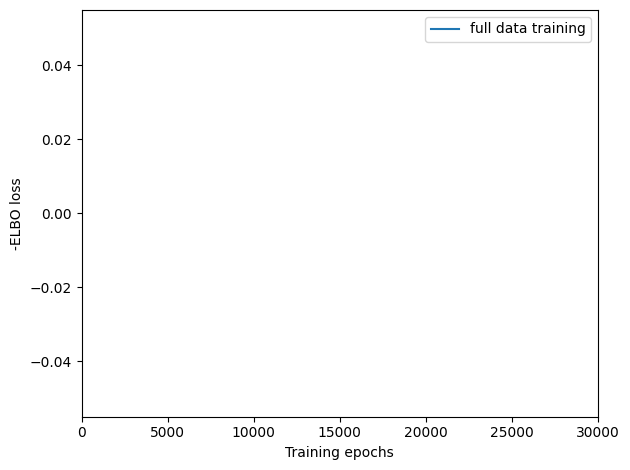

In [ ]:
mod.train(max_epochs=30000,
          # train using full data (batch_size=None)
          batch_size=None,
          # use all data points in training because
          # we need to estimate cell abundance at all locations
          train_size=1,
          accelerator="cuda"         )

# plot ELBO loss history during training, removing first 100 epochs from the plot
mod.plot_history(30000)
plt.legend(labels=['full data training']);

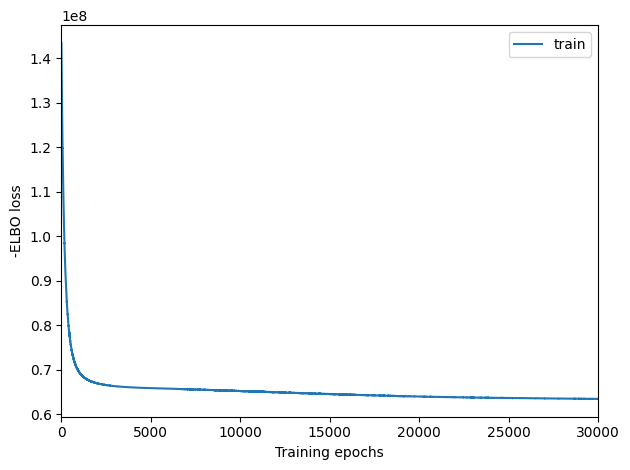

In [ ]:
mod.plot_history()

### 导出

In [ ]:
# In this section, we export the estimated cell abundance (summary of the posterior distribution).
adata = mod.export_posterior(
    adata, sample_kwargs={'num_samples': 1000, 'batch_size': mod.adata.n_obs, 'accelerator': 'cuda'}
)

# Save model
mod.save("./visum/reference_signatures/mod_pred_celltype", overwrite=True)

# Save anndata object with results
# adata.write("./visum/LN inte.h5ad")

Sampling local variables, batch:   0%|          | 0/1 [00:00<?, ?it/s]

Sampling global variables, sample:   0%|          | 0/999 [00:00<?, ?it/s]

In [ ]:
# adata = mod.export_posterior(
#     adata, sample_kwargs={'num_samples': 1000, 'batch_size': mod.adata.n_obs, 'accelerator': 'cuda'}
# )

In [ ]:
# adata_st = sc.read_h5ad("./visum/LN inte.h5ad")
# mod = cell2location.models.Cell2location.load("./visum/reference_signatures/mod_pred_LN", adata_st)

In [ ]:
mod.plot_QC()

In [ ]:
pd.DataFrame(adata.obsm['q05_cell_abundance_w_sf']).to_csv("./visum/st_cell2location_res_celltype.csv")

# caf


In [ ]:
adata =sc.read_h5ad("./visum/data/LN inte.h5ad")

In [ ]:
adata

AnnData object with n_obs × n_vars = 8468 × 17770
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'hvg', 'log1p', 'neighbors', 'pca', 'spatial', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'spatial'
    obsp: 'connectivities', 'distances'
    layers: 'counts', None (.X)

In [ ]:
sc.pp.normalize_total(
    adata,
    target_sum=1e4
)

sc.pp.log1p(adata)

In [ ]:
adata.raw = adata.copy()

/tmp/ipykernel_1070/2625100879.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


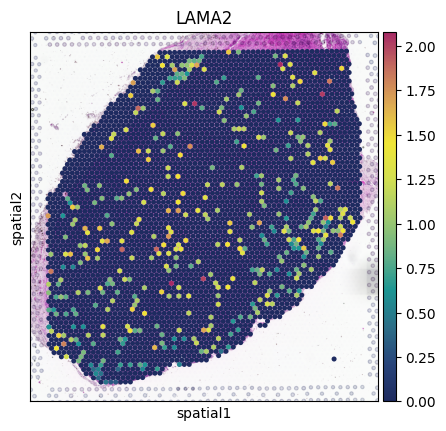

In [ ]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC14"],
    color=["LAMA2"],
    library_id="HNSCC14",
    cmap=cmap,
    img_key="hires",
    spot_size =120,
    # vmin=0, vmax='2.5'

)

/tmp/ipykernel_4821/452850053.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


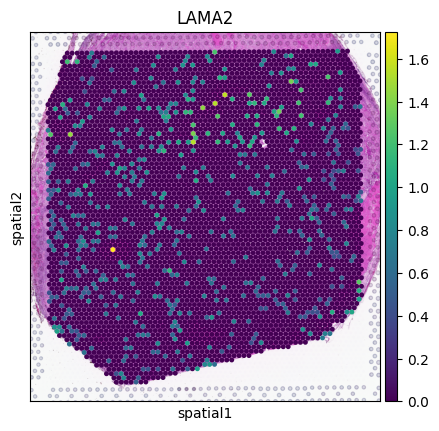

In [ ]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC59"],
    color=["LAMA2"],
    library_id="HNSCC59",
    # cmap="magma",
    img_key="hires",
    spot_size =120,
    # vmin=0, vmax='1'

)

In [ ]:
import pandas as pd
import numpy as np

# 1. 读取之前保存的 cell2location 结果
c2l = pd.read_csv(
    "./visum/st_cell2location_res_LN_celltype.csv",   # 修改为实际路径
    index_col=0,
)

c2l.index = c2l.index.astype(str)

# 去掉细胞类型列名前的 c2l 前缀
# 例如 q05cell_abundance_w_sf_CAF_IL11 → CAF_IL11
c2l.columns = c2l.columns.str.replace(
    r"^q05_?cell_abundance_w_sf_",
    "",
    regex=True,
)

import re
import numpy as np
import pandas as pd

# 1. 清理连续重复的样本前缀，保留一份
def clean_spot_name(name):
    return re.sub(r"^([^_]+_)(?:\1)+", r"\1", str(name).strip())

adata_match = pd.Index([clean_spot_name(x) for x in adata.obs_names])

c2l_match = c2l.copy()
c2l_match.index = pd.Index([
    clean_spot_name(x) for x in c2l_match.index
])

# 2. 防止清理后出现重复名称，造成错误匹配
if not adata_match.is_unique:
    raise ValueError("adata 的匹配名称清理后有重复，请检查。")

if not c2l_match.index.is_unique:
    raise ValueError("CSV 的匹配名称清理后有重复，请检查。")

missing = adata_match.difference(c2l_match.index)

print(f"匹配成功：{len(adata_match) - len(missing)} / {adata.n_obs}")

if len(missing) > 0:
    print("adata 未匹配示例：", missing[:5].tolist())
    print("CSV 名称示例：", c2l_match.index[:5].tolist())
    raise ValueError("仍有未匹配 spot，请检查以上名称。")

# 3. 按 adata 的顺序提取旧结果
c2l_new = c2l_match.loc[adata_match].copy()

# 恢复为 adata 的原始名称，确保 obsm/obs 索引一致
c2l_new.index = adata.obs_names.copy()
c2l_new = c2l_new.apply(pd.to_numeric, errors="raise")
unknown_cols = [
    c for c in c2l_new.columns
    if "unknown" in str(c).lower()
]

print("删除Unknown列:", unknown_cols)

c2l_new = c2l_new.drop(
    columns=unknown_cols,
    errors="ignore"
)
if (
    not np.isfinite(c2l_new.to_numpy()).all()
    or (c2l_new.to_numpy() < 0).any()
):
    raise ValueError("c2l 结果存在缺失值、无穷值或负值。")

# 4. 写入
adata.obsm["q05_cell_abundance_w_sf"] = c2l_new.copy()
adata.obs[c2l_new.columns] = c2l_new

print("写入完成：", c2l_new.shape)

匹配成功：8466 / 8466
删除Unknown列: []
写入完成： (8466, 9)


In [ ]:
import numpy as np
import pandas as pd
from scipy import sparse

x = adata.obsm["q05_cell_abundance_w_sf"]

if isinstance(x, pd.DataFrame):
    # 总丰度为 0 的 spot 保留为全 0
    prop = x.div(x.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)
elif sparse.issparse(x):
    totals = np.asarray(x.sum(axis=1)).ravel()
    inv = np.divide(
        1.0, totals,
        out=np.zeros_like(totals, dtype=float),
        where=totals != 0
    )
    prop = sparse.diags(inv).dot(x).tocsr()
else:
    x = np.asarray(x)
    totals = x.sum(axis=1, keepdims=True)
    prop = np.divide(
        x, totals,
        out=np.zeros_like(x, dtype=float),
        where=totals != 0
    )

adata.obsm["q05_cell_abundance_w_sf_norm"] = prop

# 检查：非零 spot 的行总和应约为 1
print(np.asarray(prop.sum(axis=1)).ravel()[:10])

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [ ]:
# adata.obs[adata.uns['mod']['factor_names']] = adata.obsm['q05_cell_abundance_w_sf']
# adata.obs[adata.uns['mod']['factor_names']] = adata.obsm['q05_cell_abundance_w_sf_norm']
import pandas as pd

norm = adata.obsm["q05_cell_abundance_w_sf_norm"]

# 前面导入的原始 c2l 矩阵已包含细胞类型列名
celltypes = adata.obsm["q05_cell_abundance_w_sf_norm"].columns.tolist()

if isinstance(norm, pd.DataFrame):
    # 按 spot 和细胞类型名称对齐
    norm_df = norm.loc[adata.obs_names, celltypes].copy()
else:
    # 数组的列顺序应与原始 c2l 矩阵一致
    norm_df = pd.DataFrame(
        norm,
        index=adata.obs_names,
        columns=celltypes,
    )

# 写入 obs；同名列会更新为归一化后的值
adata.obs[celltypes] = norm_df

print(adata.obs[celltypes].head())

                           B       CAF      Endo       Epi      Mast  \
AAACAAGTATCTCCCA-1  0.020827  0.197234  0.010346  0.087988  0.035018   
AAACAATCTACTAGCA-1  0.072290  0.148245  0.096462  0.288106  0.034928   
AAACACCAATAACTGC-1  0.090688  0.081212  0.002814  0.556077  0.021463   
AAACAGAGCGACTCCT-1  0.078518  0.074273  0.121987  0.153996  0.001523   
AAACAGCTTTCAGAAG-1  0.330664  0.078433  0.035894  0.329694  0.088588   

                     Myeloid  Neutrophil    Plasma      T/NK  
AAACAAGTATCTCCCA-1  0.137625    0.150907  0.350138  0.009919  
AAACAATCTACTAGCA-1  0.160798    0.053068  0.079305  0.066799  
AAACACCAATAACTGC-1  0.058869    0.018256  0.009047  0.161575  
AAACAGAGCGACTCCT-1  0.168047    0.063038  0.066738  0.271879  
AAACAGCTTTCAGAAG-1  0.027832    0.031737  0.023630  0.053528  


/tmp/ipykernel_1070/1011435685.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


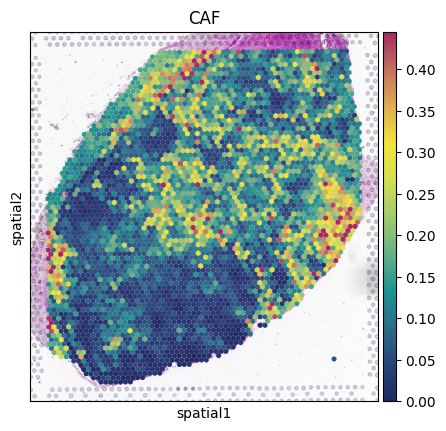

In [ ]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC14"],
    color=["CAF"],
    library_id="HNSCC14",
    cmap=cmap,
    img_key="hires",
    spot_size =120,
    vmin=0, vmax='p99'

)

/tmp/ipykernel_1070/1804776515.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


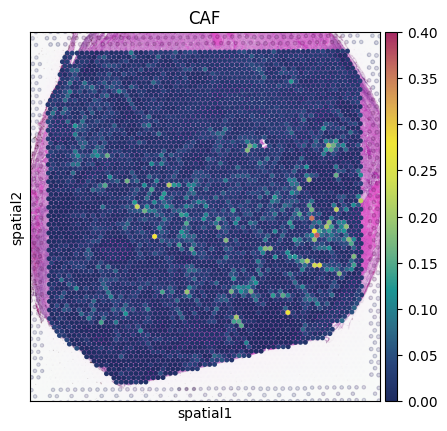

In [ ]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC59"],
    color=["CAF"],
    library_id="HNSCC59",
    cmap=cmap,
    img_key="hires",
    spot_size =120,
    vmin=0, vmax='0.4'

)

/tmp/ipykernel_1826/771049222.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


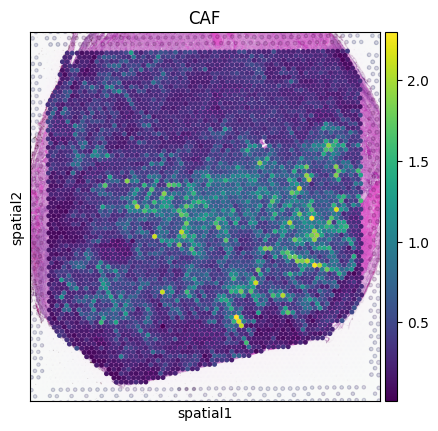

In [ ]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC59"],
    color=["CAF"],
    library_id="HNSCC59",
    # cmap="magma",
    img_key="hires",
    spot_size =120,
    # vmin=0, vmax='p99'

)

# boundary14

In [ ]:
adata =sc.read_h5ad("./visum/data/LN inte.h5ad")

In [ ]:
adata

AnnData object with n_obs × n_vars = 8468 × 17770
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'hvg', 'log1p', 'neighbors', 'pca', 'spatial', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'spatial'
    obsp: 'connectivities', 'distances'
    layers: 'counts', None (.X)

In [ ]:
import pandas as pd

# 1. 读取注释
anno = pd.read_csv("./visum/anno14 LN.csv", index_col=0)
print(anno.head())   # 查看实际的分组列名

ANNO_COL = "anno2"       # 修改为 CSV 中的分组列名
OUT_COL = "ENE_region"    # 写入 adata.obs 的列名

# 兼容 AAACA...-1、HNSCC14_AAACA...-1、
# HNSCC14_HNSCC14_AAACA...-1 等 spot 名
def clean_spot(index):
    return (
        pd.Index(index).astype(str).str.strip()
        .str.replace(r"^(?:HNSCC14_)+", "", regex=True)
    )

anno.index = clean_spot(anno.index)

if not anno.index.is_unique:
    raise ValueError("anno.csv 中清理后的 spot 名存在重复，请检查")

# 2. 整理区域名称，将 extrnodal 拼写统一为 extranodal
region = (
    anno[ANNO_COL]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({"extrnodal": "extranodal"})
)

# 3. 仅匹配 HNSCC14
mask = adata.obs["sample"].eq("HNSCC14")
spot_ids = clean_spot(adata.obs_names[mask])
matched = region.reindex(spot_ids)

if matched.notna().sum() == 0:
    raise ValueError(
        "没有匹配到有效注释，请检查 spot 名和分组列名。\n"
        f"adata 示例：{spot_ids[:3].tolist()}\n"
        f"CSV 示例：{anno.index[:3].tolist()}"
    )

# 4. 写入 obs；未匹配的 spot 保留为空
if OUT_COL not in adata.obs:
    adata.obs[OUT_COL] = pd.Series(
        pd.NA, index=adata.obs_names, dtype="string"
    )
else:
    adata.obs[OUT_COL] = adata.obs[OUT_COL].astype("string")

# 使用数组，避免清理后的 spot 名再次参与索引对齐
adata.obs.loc[mask, OUT_COL] = matched.to_numpy()

print(f"HNSCC14：成功注释 {matched.notna().sum()} / {mask.sum()} 个 spot")
print(adata.obs.loc[mask, OUT_COL].value_counts(dropna=False))

                                        anno2
Barcode                                      
AAACAAGTATCTCCCA-1                      Tumor
AAACAATCTACTAGCA-1  Thickened fibrous capsule
AAACACCAATAACTGC-1                      Tumor
AAACAGAGCGACTCCT-1                      Tumor
AAACAGCTTTCAGAAG-1                      Tumor
HNSCC14：成功注释 3931 / 3932 个 spot
ENE_region
tumor                        3385
thickened fibrous capsule     317
caf                           229
<NA>                            1
Name: count, dtype: Int64


In [ ]:
adata = adata[adata.obs["sample"]=="HNSCC14"].copy()

In [ ]:
adata

AnnData object with n_obs × n_vars = 3932 × 17770
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'ENE_region'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'hvg', 'log1p', 'neighbors', 'pca', 'spatial', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'spatial'
    obsp: 'connectivities', 'distances'
    layers: 'counts', None (.X)

/tmp/ipykernel_48267/1973409917.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()


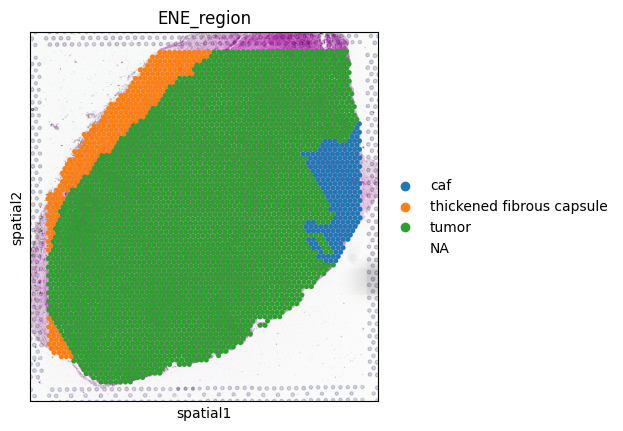

In [ ]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC14"],
    color=["ENE_region"],
    library_id="HNSCC14",
    # cmap="magma",
    img_key="hires",
    spot_size =120,
    # vmin=0, vmax='p99'

)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.spatial import cKDTree
from pathlib import Path

# ========= 参数 =========
SAMPLE = "HNSCC14"
REGION = "ENE_region"
GENE = "LAMA2"

USE_RAW = True       # 确认 raw 中是归一化后的 log1p 表达
MAX_BIN = 6          # 第6层及更远的 spot 合并
MIN_SPOTS = 5
ADJ_FACTOR = 1.2     # 相邻判定：距离 <= 1.2 × spot 间距
SAVE = False

outdir = Path("./visum/figure/ENE_gradient")

# ========= 1. 提取样本与区域 =========
slide = adata[adata.obs["sample"].eq(SAMPLE)].copy()

if slide.n_obs < 2:
    raise ValueError(f"{SAMPLE} 的 spot 数不足")

region_all = (
    slide.obs[REGION]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "intra": "intranodal",
        "outra": "extranodal",
        "extra": "extranodal",
        "extrnodal": "extranodal",
    })
)

keep = region_all.isin(["intranodal", "extranodal"])
sub = slide[keep.to_numpy()].copy()
region = region_all.loc[sub.obs_names]

xy_all = np.asarray(slide.obsm["spatial"], dtype=float)
xy = np.asarray(sub.obsm["spatial"], dtype=float)

if not np.isfinite(xy_all).all():
    raise ValueError("spatial 坐标包含缺失值或无穷值")

intra_mask = region.eq("intranodal").to_numpy(dtype=bool)
extra_mask = region.eq("extranodal").to_numpy(dtype=bool)

if not intra_mask.any() or not extra_mask.any():
    raise ValueError("需要同时包含 intra 和 outra 两类 spot")

# ========= 2. 估计 spot 中心间距 =========
nn_dist = cKDTree(xy_all).query(xy_all, k=2)[0][:, 1]
valid_dist = nn_dist[np.isfinite(nn_dist) & (nn_dist > 0)]

if valid_dist.size == 0:
    raise ValueError("无法估计 spot 间距，请检查 spatial 坐标")

spacing = np.median(valid_dist)

# ========= 3. 根据跨区域相邻 spot 估计交界 =========
xy_intra = xy[intra_mask]
xy_extra = xy[extra_mask]

neighbors = cKDTree(xy_intra).query_ball_tree(
    cKDTree(xy_extra),
    r=ADJ_FACTOR * spacing,
)

# 每一对分别属于 intra / extra 的相邻 spot
pairs = np.array(
    [(i, j) for i, js in enumerate(neighbors) for j in js],
    dtype=int,
).reshape(-1, 2)

if len(pairs) == 0:
    raise ValueError(
        "没有找到相邻的 intra/outra spot。"
        "请检查两类区域是否直接接壤；"
        "如果中间仍保留一带未标注或 boundary spot，"
        "不能直接用此方法估计交界。"
    )

# 相邻 spot 中点作为交界参考点
interface_xy = (
    xy_intra[pairs[:, 0]] + xy_extra[pairs[:, 1]]
) / 2

interface_xy = np.unique(interface_xy, axis=0)

# ========= 4. 计算到估计交界的距离并分层 =========
distance = cKDTree(interface_xy).query(xy, k=1)[0]
distance_units = distance / spacing

# 第1层：(0, 1] 个 spot 间距
# 第2层：(1, 2] 个 spot 间距
# ...
level = np.maximum(
    1,
    np.ceil(distance_units - 1e-6).astype(int),
)
level = np.minimum(level, MAX_BIN)

sign = np.where(intra_mask, -1, 1)
distance_bin = sign * level

sub.obs["interface_distance_signed"] = sign * distance_units
sub.obs["interface_distance_bin"] = distance_bin

# ========= 5. 提取基因表达 =========
source = sub.raw if USE_RAW else sub

if source is None:
    raise ValueError("sub.raw 不存在，请设置 USE_RAW=False")

if GENE not in source.var_names:
    raise ValueError(f"{GENE} 不在所选表达矩阵中")

x = source[:, [GENE]].X
expression = (
    x.toarray().ravel()
    if sp.issparse(x)
    else np.asarray(x).ravel()
)
expression = expression.astype(float)
expression[~np.isfinite(expression)] = np.nan

df = pd.DataFrame({
    "region": region.to_numpy(),
    "distance_signed": sign * distance_units,
    "distance_bin": distance_bin,
    "expression": expression,
}, index=sub.obs_names)

# ========= 6. 按距离层汇总，包含零表达 spot =========
# 没有第0层：0仅表示估计交界
bin_order = np.r_[
    np.arange(-MAX_BIN, 0),
    np.arange(1, MAX_BIN + 1),
]

profile = (
    df.groupby("distance_bin")["expression"]
    .agg(
        mean_expression="mean",
        median_expression="median",
        n_spots="count",
    )
    .reindex(bin_order)
)

profile.index.name = "distance_bin"
profile["n_spots"] = profile["n_spots"].fillna(0).astype(int)

y = profile["mean_expression"].where(
    profile["n_spots"] >= MIN_SPOTS
)

# ========= 7. 绘图 =========
fig, ax = plt.subplots(figsize=(5, 4))

# 两侧分别绘制，避免暗示0处有表达观测值
for bins in [
    np.arange(-MAX_BIN, 0),
    np.arange(1, MAX_BIN + 1),
]:
    ax.plot(
        bins,
        y.reindex(bins),
        color="#bb4055",
        linewidth=2.5,
        marker="o",
        markersize=5,
    )

ax.axvline(
    0,
    color="0.6",
    linestyle="--",
    linewidth=1,
    zorder=0,
)

ticks = np.arange(-MAX_BIN, MAX_BIN + 1)
labels = [str(i) for i in ticks]
labels[0] = f"≤−{MAX_BIN}"
labels[-1] = f"≥{MAX_BIN}"

ax.set_xticks(ticks)
ax.set_xticklabels(labels)
ax.set_xlim(-MAX_BIN - 0.3, MAX_BIN + 0.3)
ax.set_ylim(bottom=0)

ax.set_title(GENE, fontsize=15)
ax.set_ylabel("Mean log1p expression", fontsize=12)
ax.set_xlabel(
    "Distance bin (spot spacing)",
    labelpad=33,
    fontsize=11,
)

for pos, label in [
    (0.18, "Intranodal"),
    (0.50, "Interface"),
    (0.82, "Extranodal"),
]:
    ax.text(
        pos,
        -0.15,
        label,
        transform=ax.transAxes,
        ha="center",
        fontsize=10,
    )

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

fig.tight_layout()

if SAVE:
    outdir.mkdir(parents=True, exist_ok=True)

    fig.savefig(
        outdir / f"{SAMPLE}_{GENE}_interface_gradient.tiff",
        dpi=600,
        bbox_inches="tight",
        pil_kwargs={"compression": "tiff_lzw"},
    )

    profile.to_csv(
        outdir / f"{SAMPLE}_{GENE}_interface_expression.csv"
    )

plt.show()

print(profile)

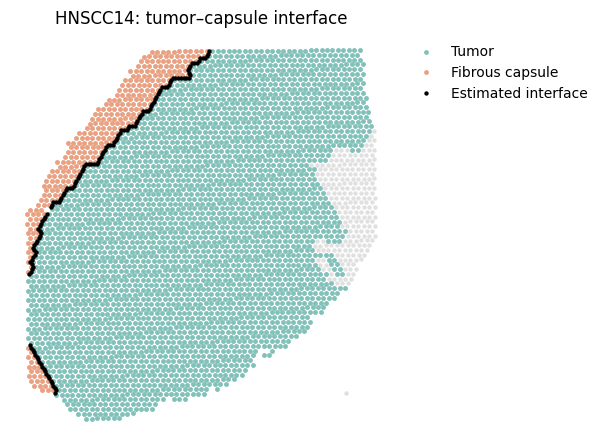

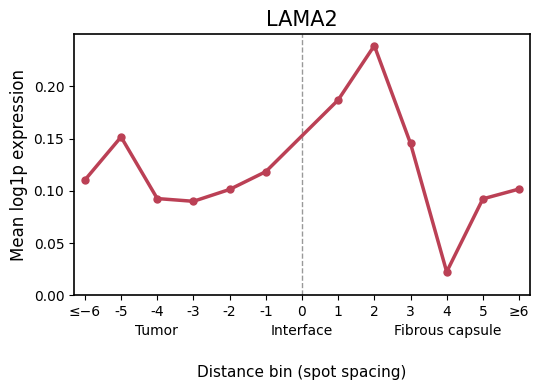

              mean_expression  median_expression  n_spots
distance_bin                                             
-6                   0.110416                0.0     2927
-5                   0.151602                0.0       94
-4                   0.092675                0.0      132
-3                   0.090042                0.0       80
-2                   0.101388                0.0       78
-1                   0.118419                0.0       74
 1                   0.186961                0.0       70
 2                   0.238937                0.0       63
 3                   0.145430                0.0       56
 4                   0.022559                0.0       65
 5                   0.092385                0.0       31
 6                   0.101774                0.0       32


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.spatial import cKDTree
from pathlib import Path

# ========= 参数 =========
SAMPLE = "HNSCC14"        # 改成这张切片的实际 sample 名称
REGION = "ENE_region"
GENE = "LAMA2"

TUMOR_LABEL = "tumor"
CAPSULE_LABEL = "thickened fibrous capsule"

USE_RAW = True           # 确认 raw.X 是归一化后的 log1p 表达
MAX_BIN = 6               # 第6层及更远的 spot 合并
MIN_SPOTS = 5
ADJ_FACTOR = 1.2          # 跨区域相邻 spot 的最大距离 / spot间距
SAVE = False             # 改为 True 保存 TIFF 和 CSV

outdir = Path("./visum/figure/tumor_capsule_gradient")

# ========= 1. 提取样本 =========
slide = adata[adata.obs["sample"].eq(SAMPLE)].copy()

if slide.n_obs < 2:
    raise ValueError(f"{SAMPLE} 的 spot 数不足，请检查 SAMPLE")

region_all = (
    slide.obs[REGION]
    .astype("string")
    .str.strip()
    .str.lower()
)

# 仅保留 tumor 和被膜
keep = region_all.isin([TUMOR_LABEL, CAPSULE_LABEL])
sub = slide[keep.to_numpy()].copy()
region = region_all.loc[sub.obs_names]

xy_all = np.asarray(slide.obsm["spatial"], dtype=float)
xy = np.asarray(sub.obsm["spatial"], dtype=float)

if not np.isfinite(xy_all).all():
    raise ValueError("spatial 坐标包含缺失值或无穷值")

tumor_mask = region.eq(TUMOR_LABEL).to_numpy(dtype=bool)
capsule_mask = region.eq(CAPSULE_LABEL).to_numpy(dtype=bool)

if not tumor_mask.any() or not capsule_mask.any():
    raise ValueError(
        "需要同时存在 tumor 和 thickened fibrous capsule。\n"
        f"当前标签：{region_all.dropna().unique().tolist()}"
    )

# ========= 2. 估计 spot 中心间距 =========
nn_dist = cKDTree(xy_all).query(xy_all, k=2)[0][:, 1]
valid_dist = nn_dist[np.isfinite(nn_dist) & (nn_dist > 0)]

if valid_dist.size == 0:
    raise ValueError("无法估计 spot 间距")

spacing = np.median(valid_dist)

# ========= 3. 找到 tumor–被膜交界 =========
xy_tumor = xy[tumor_mask]
xy_capsule = xy[capsule_mask]

neighbors = cKDTree(xy_tumor).query_ball_tree(
    cKDTree(xy_capsule),
    r=ADJ_FACTOR * spacing,
)

pairs = np.array(
    [(i, j) for i, js in enumerate(neighbors) for j in js],
    dtype=int,
).reshape(-1, 2)

if len(pairs) == 0:
    raise ValueError(
        "没有找到相邻的 tumor–被膜 spot，"
        "请检查两类标注是否直接接壤。"
    )

# 跨区域相邻 spot 的中点，作为交界参考点
interface_xy = (
    xy_tumor[pairs[:, 0]] + xy_capsule[pairs[:, 1]]
) / 2

interface_xy = np.unique(interface_xy, axis=0)

# ========= 4. 计算距离分层 =========
# 到最近交界参考点的欧氏距离
distance = cKDTree(interface_xy).query(xy, k=1)[0]
distance_units = distance / spacing

# 第1层：(0, 1]；第2层：(1, 2]；以此类推
level = np.maximum(
    1,
    np.ceil(distance_units - 1e-6).astype(int),
)
level = np.minimum(level, MAX_BIN)

# tumor 为负，被膜为正
sign = np.where(tumor_mask, -1, 1)
distance_bin = sign * level

sub.obs["tumor_capsule_distance"] = sign * distance_units
sub.obs["tumor_capsule_bin"] = distance_bin

# ========= 5. 提取表达 =========
source = sub.raw if USE_RAW else sub

if source is None:
    raise ValueError("sub.raw 不存在，请设置 USE_RAW=False")

if GENE not in source.var_names:
    raise ValueError(f"{GENE} 不在所选表达矩阵中")

x = source[:, [GENE]].X
expression = (
    x.toarray().ravel()
    if sp.issparse(x)
    else np.asarray(x).ravel()
).astype(float)

expression[~np.isfinite(expression)] = np.nan

df = pd.DataFrame({
    "region": region.to_numpy(),
    "distance_signed": sign * distance_units,
    "distance_bin": distance_bin,
    "expression": expression,
}, index=sub.obs_names)

# ========= 6. 汇总每层表达，包含0值 =========
bin_order = np.r_[
    np.arange(-MAX_BIN, 0),
    np.arange(1, MAX_BIN + 1),
]

profile = (
    df.groupby("distance_bin")["expression"]
    .agg(
        mean_expression="mean",
        median_expression="median",
        n_spots="count",
    )
    .reindex(bin_order)
)

profile.index.name = "distance_bin"
profile["n_spots"] = profile["n_spots"].fillna(0).astype(int)

y = profile["mean_expression"].where(
    profile["n_spots"] >= MIN_SPOTS
)

# ========= 7. 交界定位检查图 =========
fig_check, ax_check = plt.subplots(figsize=(6, 6))

# 整张切片作为浅灰色背景
ax_check.scatter(
    xy_all[:, 0], xy_all[:, 1],
    s=10, color="#E0E0E0",
    linewidths=0,
)

ax_check.scatter(
    xy_tumor[:, 0], xy_tumor[:, 1],
    s=12, color="#80c2ba",
    linewidths=0, label="Tumor",
)

ax_check.scatter(
    xy_capsule[:, 0], xy_capsule[:, 1],
    s=12, color="#eba07f",
    linewidths=0, label="Fibrous capsule",
)

# 不连接中点，避免把不连续的交界强行连起来
ax_check.scatter(
    interface_xy[:, 0], interface_xy[:, 1],
    s=10, color="black",
    linewidths=0, label="Estimated interface",
    zorder=5,
)

ax_check.set_aspect("equal")
ax_check.invert_yaxis()
ax_check.set_axis_off()
ax_check.set_title(f"{SAMPLE}: tumor–capsule interface")
ax_check.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False,
)
fig_check.tight_layout()

# ========= 8. 表达梯度图 =========
fig, ax = plt.subplots(figsize=(5.5, 4))

# 两侧分别画；0处没有实际表达观测值
ax.plot(
    profile.index,
    y,
    color="#bb4055",
    linewidth=2.5,
    marker="o",
    markersize=5,
)

ax.axvline(
    0,
    color="0.6",
    linestyle="--",
    linewidth=1,
    zorder=0,
)

ticks = np.arange(-MAX_BIN, MAX_BIN + 1)
labels = [str(i) for i in ticks]
labels[0] = f"≤−{MAX_BIN}"
labels[-1] = f"≥{MAX_BIN}"

ax.set_xticks(ticks)
ax.set_xticklabels(labels)
ax.set_xlim(-MAX_BIN - 0.3, MAX_BIN + 0.3)
ax.set_ylim(bottom=0)

ax.set_title(GENE, fontsize=15)
ax.set_ylabel("Mean log1p expression", fontsize=12)
ax.set_xlabel(
    "Distance bin (spot spacing)",
    labelpad=33,
    fontsize=11,
)

for pos, label in [
    (0.18, "Tumor"),
    (0.50, "Interface"),
    (0.82, "Fibrous capsule"),
]:
    ax.text(
        pos, -0.15, label,
        transform=ax.transAxes,
        ha="center",
        fontsize=10,
    )

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

fig.tight_layout()

# ========= 9. 保存 =========
if SAVE:
    outdir.mkdir(parents=True, exist_ok=True)
    prefix = f"{SAMPLE}_{GENE}_tumor_capsule"

    for figure, suffix in [
        (fig_check, "interface_check"),
        (fig, "gradient"),
    ]:
        figure.savefig(
            outdir / f"{prefix}_{suffix}.tiff",
            dpi=600,
            bbox_inches="tight",
            pil_kwargs={"compression": "tiff_lzw"},
        )

    profile.to_csv(outdir / f"{prefix}_profile.csv")
    df.to_csv(outdir / f"{prefix}_spot_data.csv")

plt.show()
print(profile)

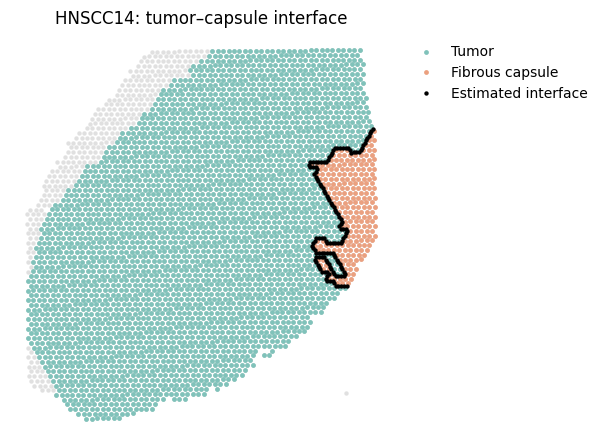

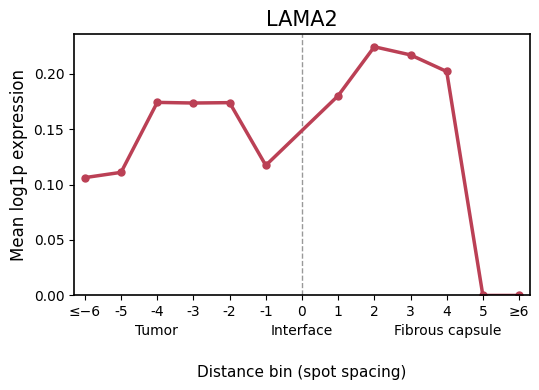

              mean_expression  median_expression  n_spots
distance_bin                                             
-6                   0.106240                0.0     3070
-5                   0.110985                0.0       57
-4                   0.174061                0.0       85
-3                   0.173496                0.0       52
-2                   0.173840                0.0       54
-1                   0.117271                0.0       67
 1                   0.180084                0.0       64
 2                   0.224212                0.0       39
 3                   0.216865                0.0       33
 4                   0.201919                0.0       46
 5                   0.000000                0.0       23
 6                   0.000000                0.0       24


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.spatial import cKDTree
from pathlib import Path

# ========= 参数 =========
SAMPLE = "HNSCC14"        # 改成这张切片的实际 sample 名称
REGION = "ENE_region"
GENE = "LAMA2"

TUMOR_LABEL = "tumor"
CAPSULE_LABEL = "caf"

USE_RAW = True           # 确认 raw.X 是归一化后的 log1p 表达
MAX_BIN = 6               # 第6层及更远的 spot 合并
MIN_SPOTS = 5
ADJ_FACTOR = 1.2          # 跨区域相邻 spot 的最大距离 / spot间距
SAVE = False             # 改为 True 保存 TIFF 和 CSV

outdir = Path("./visum/figure/tumor_capsule_gradient")

# ========= 1. 提取样本 =========
slide = adata[adata.obs["sample"].eq(SAMPLE)].copy()

if slide.n_obs < 2:
    raise ValueError(f"{SAMPLE} 的 spot 数不足，请检查 SAMPLE")

region_all = (
    slide.obs[REGION]
    .astype("string")
    .str.strip()
    .str.lower()
)

# 仅保留 tumor 和被膜
keep = region_all.isin([TUMOR_LABEL, CAPSULE_LABEL])
sub = slide[keep.to_numpy()].copy()
region = region_all.loc[sub.obs_names]

xy_all = np.asarray(slide.obsm["spatial"], dtype=float)
xy = np.asarray(sub.obsm["spatial"], dtype=float)

if not np.isfinite(xy_all).all():
    raise ValueError("spatial 坐标包含缺失值或无穷值")

tumor_mask = region.eq(TUMOR_LABEL).to_numpy(dtype=bool)
capsule_mask = region.eq(CAPSULE_LABEL).to_numpy(dtype=bool)

if not tumor_mask.any() or not capsule_mask.any():
    raise ValueError(
        "需要同时存在 tumor 和 thickened fibrous capsule。\n"
        f"当前标签：{region_all.dropna().unique().tolist()}"
    )

# ========= 2. 估计 spot 中心间距 =========
nn_dist = cKDTree(xy_all).query(xy_all, k=2)[0][:, 1]
valid_dist = nn_dist[np.isfinite(nn_dist) & (nn_dist > 0)]

if valid_dist.size == 0:
    raise ValueError("无法估计 spot 间距")

spacing = np.median(valid_dist)

# ========= 3. 找到 tumor–被膜交界 =========
xy_tumor = xy[tumor_mask]
xy_capsule = xy[capsule_mask]

neighbors = cKDTree(xy_tumor).query_ball_tree(
    cKDTree(xy_capsule),
    r=ADJ_FACTOR * spacing,
)

pairs = np.array(
    [(i, j) for i, js in enumerate(neighbors) for j in js],
    dtype=int,
).reshape(-1, 2)

if len(pairs) == 0:
    raise ValueError(
        "没有找到相邻的 tumor–被膜 spot，"
        "请检查两类标注是否直接接壤。"
    )

# 跨区域相邻 spot 的中点，作为交界参考点
interface_xy = (
    xy_tumor[pairs[:, 0]] + xy_capsule[pairs[:, 1]]
) / 2

interface_xy = np.unique(interface_xy, axis=0)

# ========= 4. 计算距离分层 =========
# 到最近交界参考点的欧氏距离
distance = cKDTree(interface_xy).query(xy, k=1)[0]
distance_units = distance / spacing

# 第1层：(0, 1]；第2层：(1, 2]；以此类推
level = np.maximum(
    1,
    np.ceil(distance_units - 1e-6).astype(int),
)
level = np.minimum(level, MAX_BIN)

# tumor 为负，被膜为正
sign = np.where(tumor_mask, -1, 1)
distance_bin = sign * level

sub.obs["tumor_capsule_distance"] = sign * distance_units
sub.obs["tumor_capsule_bin"] = distance_bin

# ========= 5. 提取表达 =========
source = sub.raw if USE_RAW else sub

if source is None:
    raise ValueError("sub.raw 不存在，请设置 USE_RAW=False")

if GENE not in source.var_names:
    raise ValueError(f"{GENE} 不在所选表达矩阵中")

x = source[:, [GENE]].X
expression = (
    x.toarray().ravel()
    if sp.issparse(x)
    else np.asarray(x).ravel()
).astype(float)

expression[~np.isfinite(expression)] = np.nan

df = pd.DataFrame({
    "region": region.to_numpy(),
    "distance_signed": sign * distance_units,
    "distance_bin": distance_bin,
    "expression": expression,
}, index=sub.obs_names)

# ========= 6. 汇总每层表达，包含0值 =========
bin_order = np.r_[
    np.arange(-MAX_BIN, 0),
    np.arange(1, MAX_BIN + 1),
]

profile = (
    df.groupby("distance_bin")["expression"]
    .agg(
        mean_expression="mean",
        median_expression="median",
        n_spots="count",
    )
    .reindex(bin_order)
)

profile.index.name = "distance_bin"
profile["n_spots"] = profile["n_spots"].fillna(0).astype(int)

y = profile["mean_expression"].where(
    profile["n_spots"] >= MIN_SPOTS
)

# ========= 7. 交界定位检查图 =========
fig_check, ax_check = plt.subplots(figsize=(6, 6))

# 整张切片作为浅灰色背景
ax_check.scatter(
    xy_all[:, 0], xy_all[:, 1],
    s=10, color="#E0E0E0",
    linewidths=0,
)

ax_check.scatter(
    xy_tumor[:, 0], xy_tumor[:, 1],
    s=12, color="#80c2ba",
    linewidths=0, label="Tumor",
)

ax_check.scatter(
    xy_capsule[:, 0], xy_capsule[:, 1],
    s=12, color="#eba07f",
    linewidths=0, label="Fibrous capsule",
)

# 不连接中点，避免把不连续的交界强行连起来
ax_check.scatter(
    interface_xy[:, 0], interface_xy[:, 1],
    s=10, color="black",
    linewidths=0, label="Estimated interface",
    zorder=5,
)

ax_check.set_aspect("equal")
ax_check.invert_yaxis()
ax_check.set_axis_off()
ax_check.set_title(f"{SAMPLE}: tumor–capsule interface")
ax_check.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False,
)
fig_check.tight_layout()

# ========= 8. 表达梯度图 =========
fig, ax = plt.subplots(figsize=(5.5, 4))

# 两侧分别画；0处没有实际表达观测值
ax.plot(
    profile.index,
    y,
    color="#bb4055",
    linewidth=2.5,
    marker="o",
    markersize=5,
)

ax.axvline(
    0,
    color="0.6",
    linestyle="--",
    linewidth=1,
    zorder=0,
)

ticks = np.arange(-MAX_BIN, MAX_BIN + 1)
labels = [str(i) for i in ticks]
labels[0] = f"≤−{MAX_BIN}"
labels[-1] = f"≥{MAX_BIN}"

ax.set_xticks(ticks)
ax.set_xticklabels(labels)
ax.set_xlim(-MAX_BIN - 0.3, MAX_BIN + 0.3)
ax.set_ylim(bottom=0)

ax.set_title(GENE, fontsize=15)
ax.set_ylabel("Mean log1p expression", fontsize=12)
ax.set_xlabel(
    "Distance bin (spot spacing)",
    labelpad=33,
    fontsize=11,
)

for pos, label in [
    (0.18, "Tumor"),
    (0.50, "Interface"),
    (0.82, "Fibrous capsule"),
]:
    ax.text(
        pos, -0.15, label,
        transform=ax.transAxes,
        ha="center",
        fontsize=10,
    )

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

fig.tight_layout()

# ========= 9. 保存 =========
if SAVE:
    outdir.mkdir(parents=True, exist_ok=True)
    prefix = f"{SAMPLE}_{GENE}_tumor_capsule"

    for figure, suffix in [
        (fig_check, "interface_check"),
        (fig, "gradient"),
    ]:
        figure.savefig(
            outdir / f"{prefix}_{suffix}.tiff",
            dpi=600,
            bbox_inches="tight",
            pil_kwargs={"compression": "tiff_lzw"},
        )

    profile.to_csv(outdir / f"{prefix}_profile.csv")
    df.to_csv(outdir / f"{prefix}_spot_data.csv")

plt.show()
print(profile)

HNSCC14 | LAMA2
                           mean_expression  median_expression  n_spots
region                                                                
tumor                               0.1104                0.0     3385
thickened fibrous capsule           0.1384                0.0      317
caf                                 0.1603                0.0      229


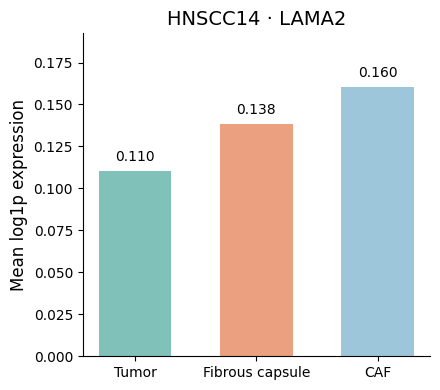

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from pathlib import Path

# ========= 参数 =========
SAMPLE = "HNSCC14"       # 改为实际样本名
REGION = "ENE_region"
GENE = "LAMA2"
USE_RAW = True          # 确认 raw.X 为归一化后的 log1p 表达
SAVE = False

ORDER = ["tumor", "thickened fibrous capsule", "caf"]
LABELS = ["Tumor", "Fibrous capsule", "CAF"]
COLORS = ["#80c2ba", "#eba07f", "#9ec6da"]

outdir = Path("./visum/figure/region_expression")

# ========= 1. 提取样本和区域 =========
slide = adata[adata.obs["sample"].eq(SAMPLE)].copy()

region = (
    slide.obs[REGION]
    .astype("string")
    .str.strip()
    .str.lower()
)

keep = region.isin(ORDER)
sub = slide[keep.to_numpy()].copy()
region = region.loc[sub.obs_names]

if sub.n_obs == 0:
    raise ValueError("没有匹配的 spot，请检查 SAMPLE 和区域名称")

# ========= 2. 提取表达 =========
source = sub.raw if USE_RAW else sub

if source is None:
    raise ValueError("raw 不存在，请设置 USE_RAW=False")
if GENE not in source.var_names:
    raise ValueError(f"{GENE} 不在所选表达矩阵中")

x = source[:, [GENE]].X
expression = (
    x.toarray().ravel()
    if sp.issparse(x)
    else np.asarray(x).ravel()
).astype(float)

expression[~np.isfinite(expression)] = np.nan

df = pd.DataFrame({
    "region": region.to_numpy(),
    "expression": expression,
}, index=sub.obs_names)

# ========= 3. 量化：包含零表达 spot =========
summary = (
    df.groupby("region")["expression"]
    .agg(
        mean_expression="mean",
        median_expression="median",
        n_spots="count",
    )
    .reindex(ORDER)
)

print(f"{SAMPLE} | {GENE}")
print(summary.round(4))

# ========= 4. 柱状图 =========
fig, ax = plt.subplots(figsize=(4.5, 4))

# 没有有效表达数据的区域不画柱子
valid = summary["mean_expression"].notna().to_numpy()
positions = np.arange(len(ORDER))[valid]
means = summary.loc[valid, "mean_expression"].to_numpy()

bars = ax.bar(
    positions,
    means,
    width=0.6,
    color=np.array(COLORS)[valid],
    edgecolor="none",
)

# 标注均值
for bar, value in zip(bars, means):
    ax.annotate(
        f"{value:.3f}",
        xy=(bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
    )

ax.set_xticks(np.arange(len(ORDER)))
ax.set_xticklabels(LABELS, fontsize=10)
ax.set_ylabel("Mean log1p expression", fontsize=12)
ax.set_title(f"{SAMPLE} · {GENE}", fontsize=14)
ax.set_ylim(
    0,
    max(float(means.max()) * 1.2, 0.1) if len(means) else 1,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()

# ========= 5. 保存 =========
if SAVE:
    outdir.mkdir(parents=True, exist_ok=True)

    fig.savefig(
        outdir / f"{SAMPLE}_{GENE}_region_mean.tiff",
        dpi=600,
        bbox_inches="tight",
        pil_kwargs={"compression": "tiff_lzw"},
    )
    summary.to_csv(
        outdir / f"{SAMPLE}_{GENE}_region_summary.csv"
    )

plt.show()

In [ ]:
sc.tl.rank_genes_groups(adata, groupby='ENE_region', method="wilcoxon",use_raw=True)
sc.tl.dendrogram(adata, groupby='ENE_region')
result = adata.uns['rank_genes_groups']
groups = result['names'].dtype.names
degs = pd.DataFrame(
    {group + '_' + key: result[key][group]
    for group in groups for key in ['names','scores', 'pvals','pvals_adj','logfoldchanges']})

{'mainplot_ax': <Axes: >,
 'group_extra_ax': <Axes: >,
 'gene_group_ax': <Axes: >,
 'size_legend_ax': <Axes: title={'center': 'Fraction of cells\nin group (%)'}>,
 'color_legend_ax': <Axes: title={'center': 'Mean expression\nin group'}>}

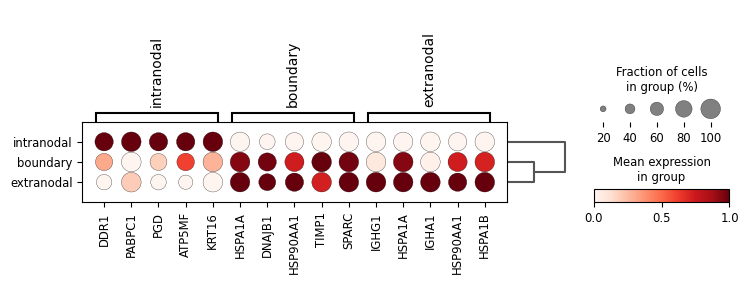

In [ ]:
sc.pl.rank_genes_groups_dotplot(
    adata, groupby="ENE_region",
    standard_scale="var",
    n_genes=5,
    show =False
)


/tmp/ipykernel_1826/362677523.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


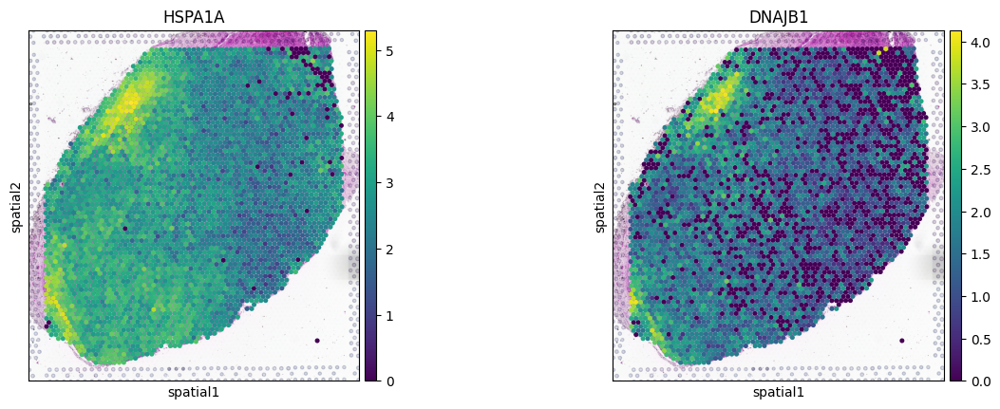

In [ ]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC14"],
    color=["HSPA1A","DNAJB1"],
    library_id="HNSCC14",
    # cmap="magma",
    img_key="hires",
    spot_size =120,
    # vmin=0, vmax='1'

)

In [ ]:
result = adata.uns['rank_genes_groups']
groups = result['names'].dtype.names  # 获取所有 cluster 名称

# 整理成一个 DataFrame
dfs = []
for group in groups:
    df = pd.DataFrame({
        'cluster': group,
        'gene': result['names'][group],
        'log2FC': result['logfoldchanges'][group],
        'pval': result['pvals'][group],
        'pval_adj': result['pvals_adj'][group],
        'scores': result['scores'][group]
    })
    dfs.append(df)

# 合并所有 cluster
markers = pd.concat(dfs, axis=0)

# 保存为 CSV 文件
# markers.to_csv('./fibro_degene_new.csv', index=False)

In [ ]:
top200_per_cluster = markers.groupby('cluster', group_keys=False).apply(
    lambda x: x.sort_values('scores', ascending=False).head(200)
)

/tmp/ipykernel_1826/3688369590.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  top200_per_cluster = markers.groupby('cluster', group_keys=False).apply(


In [ ]:


res_all = []

for clu in top200_per_cluster['cluster'].unique():
    print(f'Running enrichment for {clu} ...')

    gene_list = (
        top200_per_cluster
        .loc[top200_per_cluster['cluster'] == clu, 'gene']
        .dropna()
        .unique()
        .tolist()
    )

    # #
    # if len(gene_list) < 5:
    #     print(f'Skip {clu}, too few genes')
    #     continue

    # enr = gp.enrichr(
    #     gene_list=gene_list,
    #     gene_sets='KEGG_2021_Human',
    #     organism='Human',
    #     outdir='./',
    #     cutoff=0.05
    # )

    enr = gp.enrichr(
        gene_list=gene_list,
        gene_sets='GO_Biological_Process_2025',
        organism='human',
        outdir='./',
        cutoff=0.05
    )
    # msig = gp.Msigdb()
    # gmt = msig.get_gmt(category='h.all', dbver="2025.1.Hs")
    # enr = gp.enrichr(
    # gene_list=gene_list,
    # gene_sets=gmt,
    # organism='Human',
    # outdir='./',
    # cutoff=0.05
    # )

    if enr.results is not None and enr.results.shape[0] > 0:
        df = enr.results.copy()
        df['cluster'] = clu
        res_all.append(df)

# 5. concat
enr_all = pd.concat(res_all, axis=0, ignore_index=True)


Running enrichment for boundary ...
Running enrichment for extranodal ...
Running enrichment for intranodal ...


In [ ]:
plot_df = (
    enr_all
    .groupby('cluster', group_keys=False)
    .apply(lambda x: x.sort_values('Adjusted P-value').head(30))
)

/tmp/ipykernel_1826/3810599432.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sort_values('Adjusted P-value').head(30))


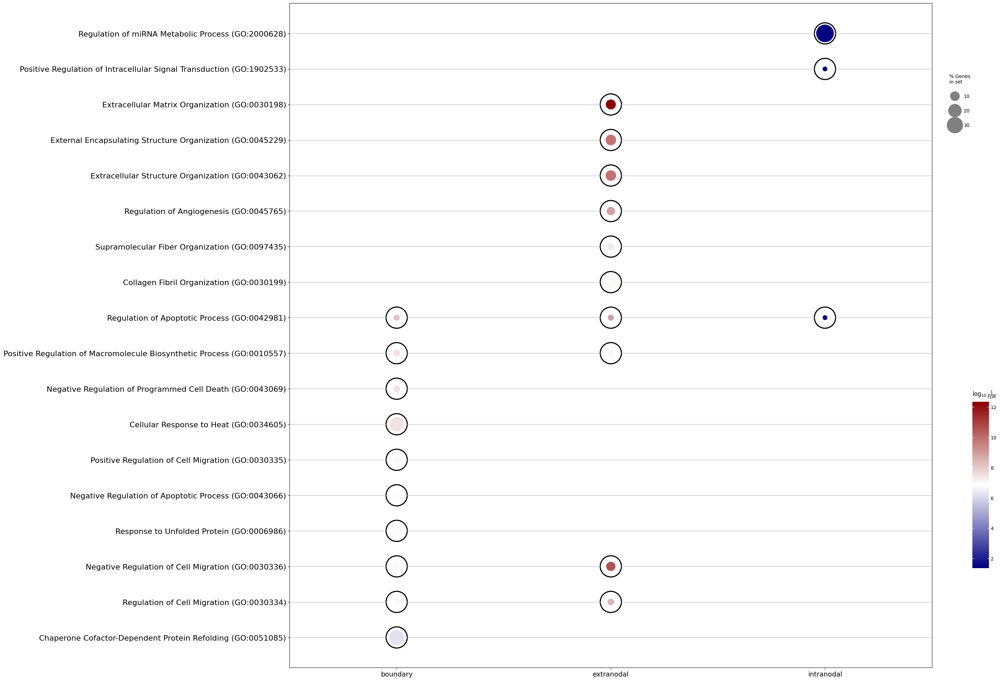

In [ ]:
from gseapy.scipalette import SciPalette
sci = SciPalette()
NbDr = sci.create_colormap()
# NbDr
ax = gp.dotplot(plot_df,figsize=(30,25),
                x='cluster',
                # x_order = ["UP","DOWN"],
                # title="GO_BP",
                cmap = NbDr,
                size=10,
                show_ring=True,
                )
ax.set_xlabel("")

fig = ax.figure
fig.savefig("./visum/enrich/HNSCC14_gobp_pathway_dotplot.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
import scanpy as sc
from pathlib import Path

outdir = Path("./visum/DEG_ENE_region")
outdir.mkdir(parents=True, exist_ok=True)

# 提取所有区域的结果
deg = sc.get.rank_genes_groups_df(adata, group=None)

# 保存完整结果，group 列表示所属区域
deg.to_csv(outdir / "ENE_region_all_genes.csv", index=False)

# 分区域保存
for region, df in deg.groupby("group", observed=True):
    df.to_csv(outdir / f"{region}_all_genes.csv", index=False)

    # 筛选显著差异基因
    sig = df[
        (df["pvals_adj"] < 0.05)
        & (df["logfoldchanges"].abs() > 1)
    ]
    sig.to_csv(outdir / f"{region}_DEG.csv", index=False)

## 距离计算

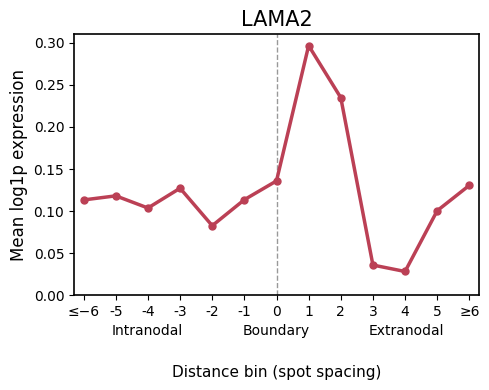

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from pathlib import Path

# ========= 参数 =========
SAMPLE = "HNSCC14"
REGION = "ENE_region"
KEY = "q05_cell_abundance_w_sf"

MAX_BIN = 6          # 第6层及更远的 spot 合并
MIN_SPOTS = 5        # 少于5个有效 spot 的距离层不画
CELL_TYPES = "CAF"   # None：展示平均占比最高的8类
# 也可以指定：
# CELL_TYPES = ["CAF_COL14A1", "myCAF_CTHRC1", "qCAF"]

outdir = Path("./visum/figure/ENE_gradient")
outdir.mkdir(parents=True, exist_ok=True)

# ========= 1. 提取样本 =========
slide = adata[adata.obs["sample"].eq(SAMPLE)].copy()

region_all = (
    slide.obs[REGION].astype("string").str.strip().str.lower()
    .replace({"extrnodal": "extranodal"})
)
keep = region_all.isin(["intranodal", "boundary", "extranodal"])
sub = slide[keep].copy()
region = region_all.loc[sub.obs_names]

xy_all = np.asarray(slide.obsm["spatial"], dtype=float)
xy = np.asarray(sub.obsm["spatial"], dtype=float)

boundary_mask = region.eq("boundary").to_numpy(dtype=bool)
if not boundary_mask.any():
    raise ValueError("没有 boundary spot")

# ========= 2. 计算距离分层 =========
# 用整张切片的最近邻距离中位数估计 spot 中心间距
nn_dist = cKDTree(xy_all).query(xy_all, k=2)[0][:, 1]
spacing = np.median(nn_dist[nn_dist > 0])

# 每个 spot 到最近 boundary spot 中心的距离
distance = cKDTree(xy[boundary_mask]).query(xy, k=1)[0]
distance_units = distance / spacing

# 按一个 spot 间距分层：
# 1层：(0, 1]；2层：(1, 2]；以此类推
level = np.maximum(
    1, np.ceil(distance_units - 1e-6).astype(int)
)
level = np.minimum(level, MAX_BIN)

sign = np.where(region.eq("intranodal"), -1, 1)
distance_bin = sign * level
distance_bin[boundary_mask] = 0

sub.obs["boundary_distance_bin"] = distance_bin

import scipy.sparse as sp

# ========= 3. 提取基因表达 =========
GENE = "LAMA2"
USE_RAW = True    # 与你前面的差异分析保持一致
                 # 注意：raw 中应为归一化后的 log1p 表达，并不一定是 counts

source = sub.raw if USE_RAW else sub

if source is None:
    raise ValueError("sub.raw 不存在，请改用 USE_RAW=False")
if GENE not in source.var_names:
    raise ValueError(f"{GENE} 不在所选表达矩阵中")

x = source[:, [GENE]].X
expression = x.toarray().ravel() if sp.issparse(x) else np.asarray(x).ravel()

df = pd.DataFrame({
    "distance_bin": sub.obs["boundary_distance_bin"].to_numpy(),
    "expression": expression,
}, index=sub.obs_names)

# ========= 4. 按距离层汇总，包含零表达 spot =========
bin_order = np.arange(-MAX_BIN, MAX_BIN + 1)

profile = (
    df.groupby("distance_bin")["expression"]
    .agg(
        mean_expression="mean",
        median_expression="median",
        n_spots="count",
    )
    .reindex(bin_order)
)

# spot 过少的层不绘制，避免不稳定的均值
y = profile["mean_expression"].where(
    profile["n_spots"] >= MIN_SPOTS
)

# ========= 5. 绘图 =========
fig, ax = plt.subplots(figsize=(5, 4))

ax.plot(
    profile.index, y,
    color="#bb4055",
    linewidth=2.5,
    marker="o",
    markersize=5
)

ax.axvline(
    0, color="0.6", linestyle="--",
    linewidth=1, zorder=0
)

labels = [str(i) for i in bin_order]
labels[0] = f"≤−{MAX_BIN}"
labels[-1] = f"≥{MAX_BIN}"

ax.set_xticks(bin_order)
ax.set_xticklabels(labels)
ax.set_xlim(-MAX_BIN - 0.3, MAX_BIN + 0.3)
ax.set_ylim(bottom=0)

ax.set_title(GENE, fontsize=15)
ax.set_ylabel("Mean log1p expression", fontsize=12)
ax.set_xlabel("Distance bin (spot spacing)", labelpad=33, fontsize=11)

for pos, label in [
    (0.18, "Intranodal"),
    (0.50, "Boundary"),
    (0.82, "Extranodal"),
]:
    ax.text(
        pos, -0.15, label,
        transform=ax.transAxes,
        ha="center", fontsize=10
    )

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

fig.tight_layout()
# fig.savefig(
#     outdir / f"{SAMPLE}_{GENE}_distance_gradient.tiff",
#     dpi=600,
#     bbox_inches="tight",
#     pil_kwargs={"compression": "tiff_lzw"}
# )
plt.show()

# 保存每层的统计结果
# profile.to_csv(outdir / f"{SAMPLE}_{GENE}_distance_expression.csv")

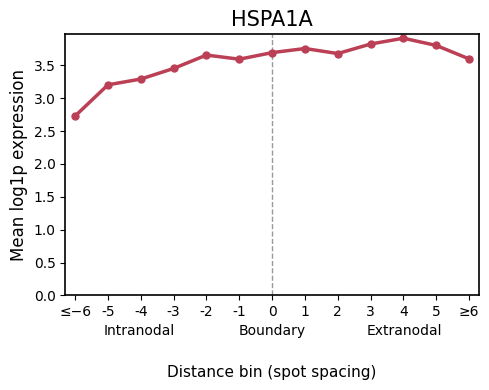

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from pathlib import Path

# ========= 参数 =========
SAMPLE = "HNSCC14"
REGION = "ENE_region"
KEY = "q05_cell_abundance_w_sf"

MAX_BIN = 6          # 第6层及更远的 spot 合并
MIN_SPOTS = 5        # 少于5个有效 spot 的距离层不画
CELL_TYPES = "CAF"   # None：展示平均占比最高的8类
# 也可以指定：
# CELL_TYPES = ["CAF_COL14A1", "myCAF_CTHRC1", "qCAF"]

outdir = Path("./visum/figure/ENE_gradient")
outdir.mkdir(parents=True, exist_ok=True)

# ========= 1. 提取样本 =========
slide = adata[adata.obs["sample"].eq(SAMPLE)].copy()

region_all = (
    slide.obs[REGION].astype("string").str.strip().str.lower()
    .replace({"extrnodal": "extranodal"})
)
keep = region_all.isin(["intranodal", "boundary", "extranodal"])
sub = slide[keep].copy()
region = region_all.loc[sub.obs_names]

xy_all = np.asarray(slide.obsm["spatial"], dtype=float)
xy = np.asarray(sub.obsm["spatial"], dtype=float)

boundary_mask = region.eq("boundary").to_numpy(dtype=bool)
if not boundary_mask.any():
    raise ValueError("没有 boundary spot")

# ========= 2. 计算距离分层 =========
# 用整张切片的最近邻距离中位数估计 spot 中心间距
nn_dist = cKDTree(xy_all).query(xy_all, k=2)[0][:, 1]
spacing = np.median(nn_dist[nn_dist > 0])

# 每个 spot 到最近 boundary spot 中心的距离
distance = cKDTree(xy[boundary_mask]).query(xy, k=1)[0]
distance_units = distance / spacing

# 按一个 spot 间距分层：
# 1层：(0, 1]；2层：(1, 2]；以此类推
level = np.maximum(
    1, np.ceil(distance_units - 1e-6).astype(int)
)
level = np.minimum(level, MAX_BIN)

sign = np.where(region.eq("intranodal"), -1, 1)
distance_bin = sign * level
distance_bin[boundary_mask] = 0

sub.obs["boundary_distance_bin"] = distance_bin

import scipy.sparse as sp

# ========= 3. 提取基因表达 =========
GENE = "HSPA1A"
USE_RAW = True    # 与你前面的差异分析保持一致
                 # 注意：raw 中应为归一化后的 log1p 表达，并不一定是 counts

source = sub.raw if USE_RAW else sub

if source is None:
    raise ValueError("sub.raw 不存在，请改用 USE_RAW=False")
if GENE not in source.var_names:
    raise ValueError(f"{GENE} 不在所选表达矩阵中")

x = source[:, [GENE]].X
expression = x.toarray().ravel() if sp.issparse(x) else np.asarray(x).ravel()

df = pd.DataFrame({
    "distance_bin": sub.obs["boundary_distance_bin"].to_numpy(),
    "expression": expression,
}, index=sub.obs_names)

# ========= 4. 按距离层汇总，包含零表达 spot =========
bin_order = np.arange(-MAX_BIN, MAX_BIN + 1)

profile = (
    df.groupby("distance_bin")["expression"]
    .agg(
        mean_expression="mean",
        median_expression="median",
        n_spots="count",
    )
    .reindex(bin_order)
)

# spot 过少的层不绘制，避免不稳定的均值
y = profile["mean_expression"].where(
    profile["n_spots"] >= MIN_SPOTS
)

# ========= 5. 绘图 =========
fig, ax = plt.subplots(figsize=(5, 4))

ax.plot(
    profile.index, y,
    color="#bb4055",
    linewidth=2.5,
    marker="o",
    markersize=5
)

ax.axvline(
    0, color="0.6", linestyle="--",
    linewidth=1, zorder=0
)

labels = [str(i) for i in bin_order]
labels[0] = f"≤−{MAX_BIN}"
labels[-1] = f"≥{MAX_BIN}"

ax.set_xticks(bin_order)
ax.set_xticklabels(labels)
ax.set_xlim(-MAX_BIN - 0.3, MAX_BIN + 0.3)
ax.set_ylim(bottom=0)

ax.set_title(GENE, fontsize=15)
ax.set_ylabel("Mean log1p expression", fontsize=12)
ax.set_xlabel("Distance bin (spot spacing)", labelpad=33, fontsize=11)

for pos, label in [
    (0.18, "Intranodal"),
    (0.50, "Boundary"),
    (0.82, "Extranodal"),
]:
    ax.text(
        pos, -0.15, label,
        transform=ax.transAxes,
        ha="center", fontsize=10
    )

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

fig.tight_layout()
# fig.savefig(
#     outdir / f"{SAMPLE}_{GENE}_distance_gradient.tiff",
#     dpi=600,
#     bbox_inches="tight",
#     pil_kwargs={"compression": "tiff_lzw"}
# )
plt.show()

# 保存每层的统计结果
# profile.to_csv(outdir / f"{SAMPLE}_{GENE}_distance_expression.csv")

## DEG

In [ ]:
df = pd.read_csv("./visum/DEG_ENE_region/boundary_all_genes.csv")

In [ ]:
df.loc[df["names"] == "LAMA2"]

         group  names    scores  logfoldchanges    pvals  pvals_adj
2427  boundary  LAMA2  0.339583        0.259702  0.73417        1.0

In [ ]:
df = pd.read_csv("./visum/DEG_ENE_region/extranodal_all_genes.csv")

In [ ]:
df.loc[df["names"] == "LAMA2"]

          group  names    scores  logfoldchanges     pvals  pvals_adj
542  extranodal  LAMA2  0.521233        0.376825  0.602205        1.0

In [ ]:
df = pd.read_csv("./visum/DEG_ENE_region/intranodal_all_genes.csv")

In [ ]:
df.loc[df["names"] == "LAMA2"]

            group  names    scores  logfoldchanges     pvals  pvals_adj
17160  intranodal  LAMA2 -0.636406        -0.35385  0.524512        1.0

In [ ]:
df

          group     names     scores  logfoldchanges         pvals  \
0      boundary    HSPA1A  11.805646        1.228741  3.649771e-32   
1      boundary    DNAJB1   9.814741        1.443780  9.728721e-23   
2      boundary  HSP90AA1   8.609990        0.947769  7.306716e-18   
3      boundary     TIMP1   7.752150        0.830242  9.034916e-15   
4      boundary     SPARC   7.588399        0.746411  3.238840e-14   
...         ...       ...        ...             ...           ...   
17765  boundary     KRT15  -6.037108       -0.505212  1.569006e-09   
17766  boundary    IFNGR2  -6.129960       -0.636845  8.790137e-10   
17767  boundary       PGD  -6.343185       -0.751565  2.250623e-10   
17768  boundary      EEF2  -6.813987       -0.298116  9.493014e-12   
17769  boundary    PABPC1  -7.590605       -0.404076  3.184162e-14   

          pvals_adj  
0      6.485643e-28  
1      8.643968e-19  
2      4.328011e-14  
3      4.013762e-11  
4      9.592366e-11  
...             ...  
17765

# boundary59

In [ ]:
adata =sc.read_h5ad("./visum/data/LN inte.h5ad")

In [ ]:
sc.pp.normalize_total(
    adata,
    target_sum=1e4
)

sc.pp.log1p(adata)

In [ ]:
adata.raw = adata.copy()

In [ ]:
os.getcwd()

'/content/drive/MyDrive/pharynx'

In [ ]:
anno59

                 Barcode                   anno2
0     AAACAACGAATAGTTC-1  Tinned fibrous capsule
1     AAACAAGTATCTCCCA-1                   Tumor
2     AAACAATCTACTAGCA-1                   Tumor
3     AAACACCAATAACTGC-1                   Tumor
4     AAACAGAGCGACTCCT-1                   Tumor
...                  ...                     ...
4531  TTGTTTCACATCCAGG-1                   Tumor
4532  TTGTTTCATTAGTCTA-1                   Tumor
4533  TTGTTTCCATACAACT-1                   Tumor
4534  TTGTTTGTATTACACG-1                   Tumor
4535  TTGTTTGTGTAAATTC-1                   Tumor

[4536 rows x 2 columns]

In [ ]:
import pandas as pd

anno59 = pd.read_csv("./visum/anno59 LN.csv")

# barcode -> annotation
anno_map = anno59.set_index("Barcode")["anno2"]

# 先创建空列
adata.obs["ENE_region"] = pd.NA

# 只处理 HNSCC59
mask59 = adata.obs["sample"].eq("HNSCC59")

# HNSCC59 当前 obs_names
names59 = adata.obs_names[mask59]

# 直接匹配；如果当前名字本身就是原始 barcode，会直接成功
adata.obs.loc[mask59, "ENE_region"] = (
    pd.Series(names59, index=names59)
    .map(anno_map)
    .values
)

In [ ]:
adata.obs["ENE_region"] = pd.NA

mask59 = adata.obs["sample"].eq("HNSCC59")

anno_map = anno59.set_index("Barcode")["anno2"]

for bc, region in anno_map.items():
    hit = (
        mask59
        & adata.obs_names.to_series().str.startswith(bc)
    )
    adata.obs.loc[hit, "ENE_region"] = region

In [ ]:
n_total = mask59.sum()
n_match = adata.obs.loc[mask59, "ENE_region"].notna().sum()

print("HNSCC59总spot数:", n_total)
print("成功匹配:", n_match)
print("未匹配:", n_total - n_match)
print("匹配率:", n_match / n_total)

HNSCC59总spot数: 4536
成功匹配: 4535
未匹配: 1
匹配率: 0.9997795414462081


In [ ]:
# import pandas as pd

# # 1. 读取注释
# anno = pd.read_csv("./visum/anno59.csv", index_col=0)
# print(anno.head())   # 查看实际的分组列名

# ANNO_COL = "anno59"       # 修改为 CSV 中的分组列名
# OUT_COL = "ENE_region"    # 写入 adata.obs 的列名

# # 兼容 AAACA...-1、HNSCC14_AAACA...-1、
# # HNSCC14_HNSCC14_AAACA...-1 等 spot 名
# def clean_spot(index):
#     return (
#         pd.Index(index).astype(str).str.strip()
#         .str.replace(r"^(?:HNSCC59_)+", "", regex=True)
#     )

# anno.index = clean_spot(anno.index)

# if not anno.index.is_unique:
#     raise ValueError("anno.csv 中清理后的 spot 名存在重复，请检查")

# # 2. 整理区域名称，将 extrnodal 拼写统一为 extranodal
# region = (
#     anno[ANNO_COL]
#     .astype("string")
#     .str.strip()
#     .str.lower()
#     .replace({"extrnodal": "extranodal"})
# )

# # 3. 仅匹配 HNSCC14
# mask = adata.obs["sample"].eq("HNSCC59")
# spot_ids = clean_spot(adata.obs_names[mask])
# matched = region.reindex(spot_ids)

# if matched.notna().sum() == 0:
#     raise ValueError(
#         "没有匹配到有效注释，请检查 spot 名和分组列名。\n"
#         f"adata 示例：{spot_ids[:3].tolist()}\n"
#         f"CSV 示例：{anno.index[:3].tolist()}"
#     )

# # 4. 写入 obs；未匹配的 spot 保留为空
# if OUT_COL not in adata.obs:
#     adata.obs[OUT_COL] = pd.Series(
#         pd.NA, index=adata.obs_names, dtype="string"
#     )
# else:
#     adata.obs[OUT_COL] = adata.obs[OUT_COL].astype("string")

# # 使用数组，避免清理后的 spot 名再次参与索引对齐
# adata.obs.loc[mask, OUT_COL] = matched.to_numpy()

# print(f"HNSCC14：成功注释 {matched.notna().sum()} / {mask.sum()} 个 spot")
# print(adata.obs.loc[mask, OUT_COL].value_counts(dropna=False))

                        anno59
Barcode                       
AAACAACGAATAGTTC-1    boundary
AAACAAGTATCTCCCA-1  intranodal
AAACAATCTACTAGCA-1  intranodal
AAACACCAATAACTGC-1  intranodal
AAACAGAGCGACTCCT-1  intranodal
HNSCC14：成功注释 4536 / 4536 个 spot
ENE_region
intranodal    4432
boundary        64
extranodal      40
Name: count, dtype: Int64


In [ ]:
adata.obs["ENE_region"].unique()

array([<NA>, 'Tinned fibrous capsule', 'Tumor', nan], dtype=object)

In [ ]:
# adata = adata[adata.obs["sample"]=="HNSCC59"].copy()

In [ ]:
adata

AnnData object with n_obs × n_vars = 4536 × 17770
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'ENE_region'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'hvg', 'log1p', 'neighbors', 'pca', 'spatial', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'spatial'
    obsp: 'connectivities', 'distances'
    layers: 'counts', None (.X)

/tmp/ipykernel_1594/2378984977.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


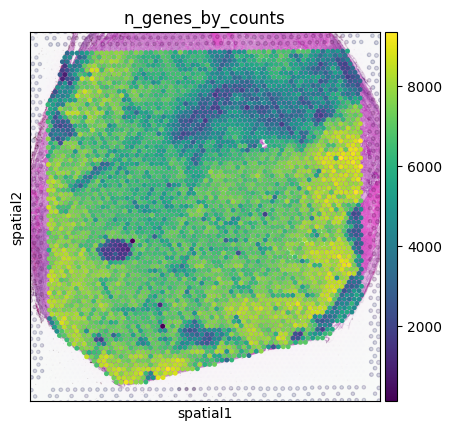

In [ ]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC59"],
    color=["n_genes_by_counts"],
    library_id="HNSCC59",
    # cmap="magma",
    img_key="hires",
    spot_size =120,
    # vmin=0, vmax='p99'

)

/tmp/ipykernel_1594/3924187125.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()


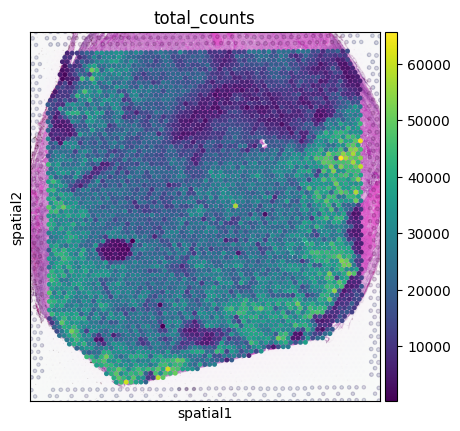

In [ ]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC59"],
    color=["total_counts"],
    library_id="HNSCC59",
    # cmap="magma",
    img_key="hires",
    spot_size =120,
    # vmin=0, vmax='p99'

)

/tmp/ipykernel_1594/1604324334.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


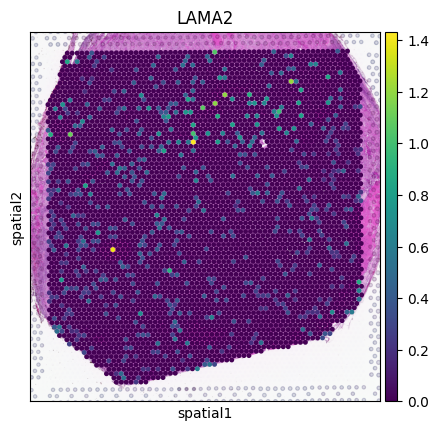

In [ ]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC59"],
    color=["LAMA2"],
    library_id="HNSCC59",
    # cmap="magma",
    img_key="hires",
    spot_size =120,
    # vmin=0, vmax='p99'

)

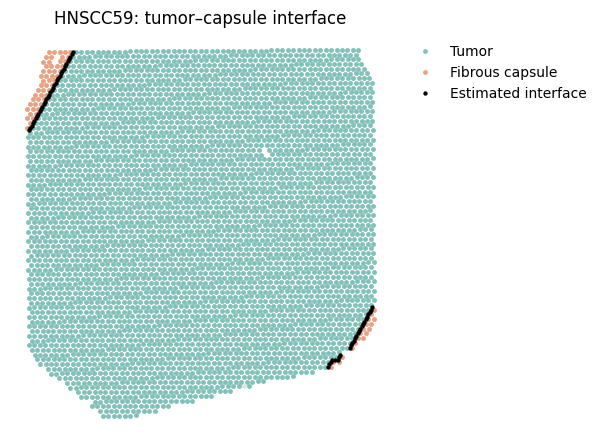

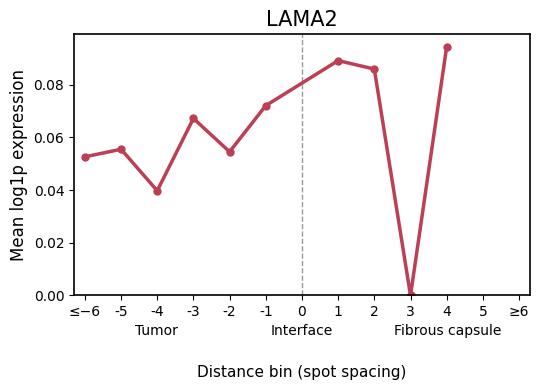

              mean_expression  median_expression  n_spots
distance_bin                                             
-6                   0.052625                0.0     4226
-5                   0.055503                0.0       51
-4                   0.039745                0.0       77
-3                   0.067205                0.0       40
-2                   0.054537                0.0       38
-1                   0.072072                0.0       33
 1                   0.089158                0.0       30
 2                   0.085939                0.0       20
 3                   0.000000                0.0       11
 4                   0.094407                0.0        9
 5                        NaN                NaN        0
 6                        NaN                NaN        0


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.spatial import cKDTree
from pathlib import Path

# ========= 参数 =========
SAMPLE = "HNSCC59"        # 改成这张切片的实际 sample 名称
REGION = "ENE_region"
GENE = "LAMA2"

TUMOR_LABEL = "tumor"
CAPSULE_LABEL = "tinned fibrous capsule"

USE_RAW = True           # 确认 raw.X 是归一化后的 log1p 表达
MAX_BIN = 6               # 第6层及更远的 spot 合并
MIN_SPOTS = 5
ADJ_FACTOR = 1.2          # 跨区域相邻 spot 的最大距离 / spot间距
SAVE = False             # 改为 True 保存 TIFF 和 CSV

outdir = Path("./visum/figure/tumor_capsule_gradient")

# ========= 1. 提取样本 =========
slide = adata[adata.obs["sample"].eq(SAMPLE)].copy()

if slide.n_obs < 2:
    raise ValueError(f"{SAMPLE} 的 spot 数不足，请检查 SAMPLE")

region_all = (
    slide.obs[REGION]
    .astype("string")
    .str.strip()
    .str.lower()
)

# 仅保留 tumor 和被膜
keep = region_all.isin([TUMOR_LABEL, CAPSULE_LABEL])
sub = slide[keep.to_numpy()].copy()
region = region_all.loc[sub.obs_names]

xy_all = np.asarray(slide.obsm["spatial"], dtype=float)
xy = np.asarray(sub.obsm["spatial"], dtype=float)

if not np.isfinite(xy_all).all():
    raise ValueError("spatial 坐标包含缺失值或无穷值")

tumor_mask = region.eq(TUMOR_LABEL).to_numpy(dtype=bool)
capsule_mask = region.eq(CAPSULE_LABEL).to_numpy(dtype=bool)

if not tumor_mask.any() or not capsule_mask.any():
    raise ValueError(
        "需要同时存在 tumor 和 thickened fibrous capsule。\n"
        f"当前标签：{region_all.dropna().unique().tolist()}"
    )

# ========= 2. 估计 spot 中心间距 =========
nn_dist = cKDTree(xy_all).query(xy_all, k=2)[0][:, 1]
valid_dist = nn_dist[np.isfinite(nn_dist) & (nn_dist > 0)]

if valid_dist.size == 0:
    raise ValueError("无法估计 spot 间距")

spacing = np.median(valid_dist)

# ========= 3. 找到 tumor–被膜交界 =========
xy_tumor = xy[tumor_mask]
xy_capsule = xy[capsule_mask]

neighbors = cKDTree(xy_tumor).query_ball_tree(
    cKDTree(xy_capsule),
    r=ADJ_FACTOR * spacing,
)

pairs = np.array(
    [(i, j) for i, js in enumerate(neighbors) for j in js],
    dtype=int,
).reshape(-1, 2)

if len(pairs) == 0:
    raise ValueError(
        "没有找到相邻的 tumor–被膜 spot，"
        "请检查两类标注是否直接接壤。"
    )

# 跨区域相邻 spot 的中点，作为交界参考点
interface_xy = (
    xy_tumor[pairs[:, 0]] + xy_capsule[pairs[:, 1]]
) / 2

interface_xy = np.unique(interface_xy, axis=0)

# ========= 4. 计算距离分层 =========
# 到最近交界参考点的欧氏距离
distance = cKDTree(interface_xy).query(xy, k=1)[0]
distance_units = distance / spacing

# 第1层：(0, 1]；第2层：(1, 2]；以此类推
level = np.maximum(
    1,
    np.ceil(distance_units - 1e-6).astype(int),
)
level = np.minimum(level, MAX_BIN)

# tumor 为负，被膜为正
sign = np.where(tumor_mask, -1, 1)
distance_bin = sign * level

sub.obs["tumor_capsule_distance"] = sign * distance_units
sub.obs["tumor_capsule_bin"] = distance_bin

# ========= 5. 提取表达 =========
source = sub.raw if USE_RAW else sub

if source is None:
    raise ValueError("sub.raw 不存在，请设置 USE_RAW=False")

if GENE not in source.var_names:
    raise ValueError(f"{GENE} 不在所选表达矩阵中")

x = source[:, [GENE]].X
expression = (
    x.toarray().ravel()
    if sp.issparse(x)
    else np.asarray(x).ravel()
).astype(float)

expression[~np.isfinite(expression)] = np.nan

df = pd.DataFrame({
    "region": region.to_numpy(),
    "distance_signed": sign * distance_units,
    "distance_bin": distance_bin,
    "expression": expression,
}, index=sub.obs_names)

# ========= 6. 汇总每层表达，包含0值 =========
bin_order = np.r_[
    np.arange(-MAX_BIN, 0),
    np.arange(1, MAX_BIN + 1),
]

profile = (
    df.groupby("distance_bin")["expression"]
    .agg(
        mean_expression="mean",
        median_expression="median",
        n_spots="count",
    )
    .reindex(bin_order)
)

profile.index.name = "distance_bin"
profile["n_spots"] = profile["n_spots"].fillna(0).astype(int)

y = profile["mean_expression"].where(
    profile["n_spots"] >= MIN_SPOTS
)

# ========= 7. 交界定位检查图 =========
fig_check, ax_check = plt.subplots(figsize=(6, 6))

# 整张切片作为浅灰色背景
ax_check.scatter(
    xy_all[:, 0], xy_all[:, 1],
    s=10, color="#E0E0E0",
    linewidths=0,
)

ax_check.scatter(
    xy_tumor[:, 0], xy_tumor[:, 1],
    s=12, color="#80c2ba",
    linewidths=0, label="Tumor",
)

ax_check.scatter(
    xy_capsule[:, 0], xy_capsule[:, 1],
    s=12, color="#eba07f",
    linewidths=0, label="Fibrous capsule",
)

# 不连接中点，避免把不连续的交界强行连起来
ax_check.scatter(
    interface_xy[:, 0], interface_xy[:, 1],
    s=10, color="black",
    linewidths=0, label="Estimated interface",
    zorder=5,
)

ax_check.set_aspect("equal")
ax_check.invert_yaxis()
ax_check.set_axis_off()
ax_check.set_title(f"{SAMPLE}: tumor–capsule interface")
ax_check.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False,
)
fig_check.tight_layout()

# ========= 8. 表达梯度图 =========
fig, ax = plt.subplots(figsize=(5.5, 4))

# 两侧分别画；0处没有实际表达观测值
ax.plot(
    profile.index,
    y,
    color="#bb4055",
    linewidth=2.5,
    marker="o",
    markersize=5,
)

ax.axvline(
    0,
    color="0.6",
    linestyle="--",
    linewidth=1,
    zorder=0,
)

ticks = np.arange(-MAX_BIN, MAX_BIN + 1)
labels = [str(i) for i in ticks]
labels[0] = f"≤−{MAX_BIN}"
labels[-1] = f"≥{MAX_BIN}"

ax.set_xticks(ticks)
ax.set_xticklabels(labels)
ax.set_xlim(-MAX_BIN - 0.3, MAX_BIN + 0.3)
ax.set_ylim(bottom=0)

ax.set_title(GENE, fontsize=15)
ax.set_ylabel("Mean log1p expression", fontsize=12)
ax.set_xlabel(
    "Distance bin (spot spacing)",
    labelpad=33,
    fontsize=11,
)

for pos, label in [
    (0.18, "Tumor"),
    (0.50, "Interface"),
    (0.82, "Fibrous capsule"),
]:
    ax.text(
        pos, -0.15, label,
        transform=ax.transAxes,
        ha="center",
        fontsize=10,
    )

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

fig.tight_layout()

# ========= 9. 保存 =========
if SAVE:
    outdir.mkdir(parents=True, exist_ok=True)
    prefix = f"{SAMPLE}_{GENE}_tumor_capsule"

    for figure, suffix in [
        (fig_check, "interface_check"),
        (fig, "gradient"),
    ]:
        figure.savefig(
            outdir / f"{prefix}_{suffix}.tiff",
            dpi=600,
            bbox_inches="tight",
            pil_kwargs={"compression": "tiff_lzw"},
        )

    profile.to_csv(outdir / f"{prefix}_profile.csv")
    df.to_csv(outdir / f"{prefix}_spot_data.csv")

plt.show()
print(profile)

HNSCC59 | LAMA2
                        mean_expression  median_expression  n_spots
region                                                             
tumor                            0.0527                0.0     4465
tinned fibrous capsule           0.0749                0.0       70


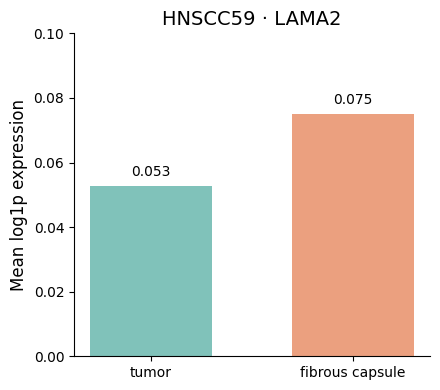

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from pathlib import Path

# ========= 参数 =========
SAMPLE = "HNSCC59"       # 改为实际样本名
REGION = "ENE_region"
GENE = "LAMA2"
USE_RAW = True          # 确认 raw.X 为归一化后的 log1p 表达
SAVE = False

ORDER = ["tumor", "tinned fibrous capsule"]
LABELS = ["tumor", "fibrous capsule"]
COLORS = ["#80c2ba", "#eba07f"]

outdir = Path("./visum/figure/region_expression")

# ========= 1. 提取样本和区域 =========
slide = adata[adata.obs["sample"].eq(SAMPLE)].copy()

region = (
    slide.obs[REGION]
    .astype("string")
    .str.strip()
    .str.lower()
)

keep = region.isin(ORDER)
sub = slide[keep.to_numpy()].copy()
region = region.loc[sub.obs_names]

if sub.n_obs == 0:
    raise ValueError("没有匹配的 spot，请检查 SAMPLE 和区域名称")

# ========= 2. 提取表达 =========
source = sub.raw if USE_RAW else sub

if source is None:
    raise ValueError("raw 不存在，请设置 USE_RAW=False")
if GENE not in source.var_names:
    raise ValueError(f"{GENE} 不在所选表达矩阵中")

x = source[:, [GENE]].X
expression = (
    x.toarray().ravel()
    if sp.issparse(x)
    else np.asarray(x).ravel()
).astype(float)

expression[~np.isfinite(expression)] = np.nan

df = pd.DataFrame({
    "region": region.to_numpy(),
    "expression": expression,
}, index=sub.obs_names)

# ========= 3. 量化：包含零表达 spot =========
summary = (
    df.groupby("region")["expression"]
    .agg(
        mean_expression="mean",
        median_expression="median",
        n_spots="count",
    )
    .reindex(ORDER)
)

print(f"{SAMPLE} | {GENE}")
print(summary.round(4))

# ========= 4. 柱状图 =========
fig, ax = plt.subplots(figsize=(4.5, 4))

# 没有有效表达数据的区域不画柱子
valid = summary["mean_expression"].notna().to_numpy()
positions = np.arange(len(ORDER))[valid]
means = summary.loc[valid, "mean_expression"].to_numpy()

bars = ax.bar(
    positions,
    means,
    width=0.6,
    color=np.array(COLORS)[valid],
    edgecolor="none",
)

# 标注均值
for bar, value in zip(bars, means):
    ax.annotate(
        f"{value:.3f}",
        xy=(bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
    )

ax.set_xticks(np.arange(len(ORDER)))
ax.set_xticklabels(LABELS, fontsize=10)
ax.set_ylabel("Mean log1p expression", fontsize=12)
ax.set_title(f"{SAMPLE} · {GENE}", fontsize=14)
ax.set_ylim(
    0,
    max(float(means.max()) * 1.2, 0.1) if len(means) else 1,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()

# ========= 5. 保存 =========
if SAVE:
    outdir.mkdir(parents=True, exist_ok=True)

    fig.savefig(
        outdir / f"{SAMPLE}_{GENE}_region_mean.tiff",
        dpi=600,
        bbox_inches="tight",
        pil_kwargs={"compression": "tiff_lzw"},
    )
    summary.to_csv(
        outdir / f"{SAMPLE}_{GENE}_region_summary.csv"
    )

plt.show()

/tmp/ipykernel_48267/3213679046.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()


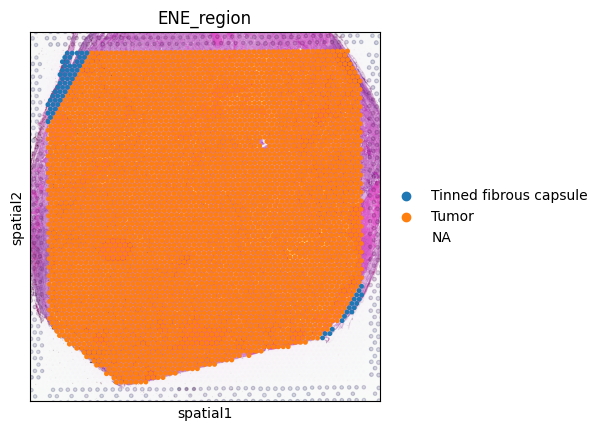

In [ ]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC59"],
    color=["ENE_region"],
    library_id="HNSCC59",
    # cmap="magma",
    img_key="hires",
    spot_size =120,
    # vmin=0, vmax='p99'

)

In [ ]:
sc.tl.rank_genes_groups(adata, groupby='ENE_region', method="wilcoxon",use_raw=True)
sc.tl.dendrogram(adata, groupby='ENE_region')
result = adata.uns['rank_genes_groups']
groups = result['names'].dtype.names
degs = pd.DataFrame(
    {group + '_' + key: result[key][group]
    for group in groups for key in ['names','scores', 'pvals','pvals_adj','logfoldchanges']})

{'mainplot_ax': <Axes: >,
 'group_extra_ax': <Axes: >,
 'gene_group_ax': <Axes: >,
 'size_legend_ax': <Axes: title={'center': 'Fraction of cells\nin group (%)'}>,
 'color_legend_ax': <Axes: title={'center': 'Mean expression\nin group'}>}

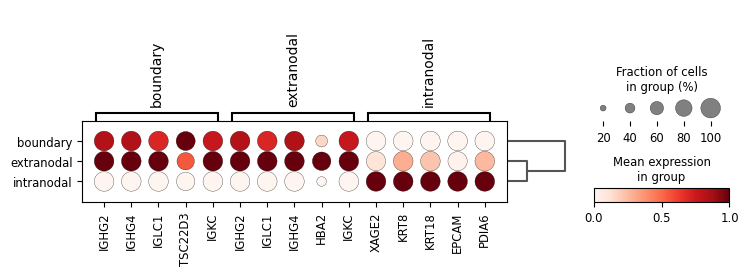

In [ ]:
sc.pl.rank_genes_groups_dotplot(
    adata, groupby="ENE_region",
    standard_scale="var",
    n_genes=5,
    show =False
)


/tmp/ipykernel_1594/1298965628.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()


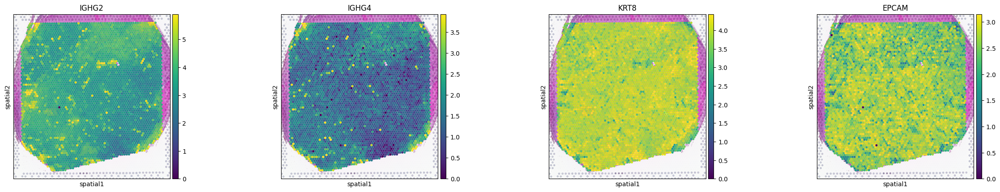

In [ ]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC59"],
    color=["IGHG2","IGHG4","KRT8","EPCAM"],
    library_id="HNSCC59",
    # cmap="magma",
    img_key="hires",
    spot_size =120,
    vmin=0, vmax='p99.2'

)

In [ ]:
result = adata.uns['rank_genes_groups']
groups = result['names'].dtype.names  # 获取所有 cluster 名称

# 整理成一个 DataFrame
dfs = []
for group in groups:
    df = pd.DataFrame({
        'cluster': group,
        'gene': result['names'][group],
        'log2FC': result['logfoldchanges'][group],
        'pval': result['pvals'][group],
        'pval_adj': result['pvals_adj'][group],
        'scores': result['scores'][group]
    })
    dfs.append(df)

# 合并所有 cluster
markers = pd.concat(dfs, axis=0)

# 保存为 CSV 文件
# markers.to_csv('./fibro_degene_new.csv', index=False)

In [ ]:
top200_per_cluster = markers.groupby('cluster', group_keys=False).apply(
    lambda x: x.sort_values('scores', ascending=False).head(200)
)

/tmp/ipykernel_1594/3688369590.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  top200_per_cluster = markers.groupby('cluster', group_keys=False).apply(


In [ ]:


res_all = []

for clu in top200_per_cluster['cluster'].unique():
    print(f'Running enrichment for {clu} ...')

    gene_list = (
        top200_per_cluster
        .loc[top200_per_cluster['cluster'] == clu, 'gene']
        .dropna()
        .unique()
        .tolist()
    )

    # #
    # if len(gene_list) < 5:
    #     print(f'Skip {clu}, too few genes')
    #     continue

    # enr = gp.enrichr(
    #     gene_list=gene_list,
    #     gene_sets='KEGG_2021_Human',
    #     organism='Human',
    #     outdir='./',
    #     cutoff=0.05
    # )

    enr = gp.enrichr(
        gene_list=gene_list,
        gene_sets='GO_Biological_Process_2025',
        organism='human',
        outdir='./',
        cutoff=0.05
    )
    # msig = gp.Msigdb()
    # gmt = msig.get_gmt(category='h.all', dbver="2025.1.Hs")
    # enr = gp.enrichr(
    # gene_list=gene_list,
    # gene_sets=gmt,
    # organism='Human',
    # outdir='./',
    # cutoff=0.05
    # )

    if enr.results is not None and enr.results.shape[0] > 0:
        df = enr.results.copy()
        df['cluster'] = clu
        res_all.append(df)

# 5. concat
enr_all = pd.concat(res_all, axis=0, ignore_index=True)


Running enrichment for boundary ...
Running enrichment for extranodal ...
Running enrichment for intranodal ...


In [ ]:
plot_df = (
    enr_all
    .groupby('cluster', group_keys=False)
    .apply(lambda x: x.sort_values('Adjusted P-value').head(30))
)

/tmp/ipykernel_1594/3810599432.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sort_values('Adjusted P-value').head(30))


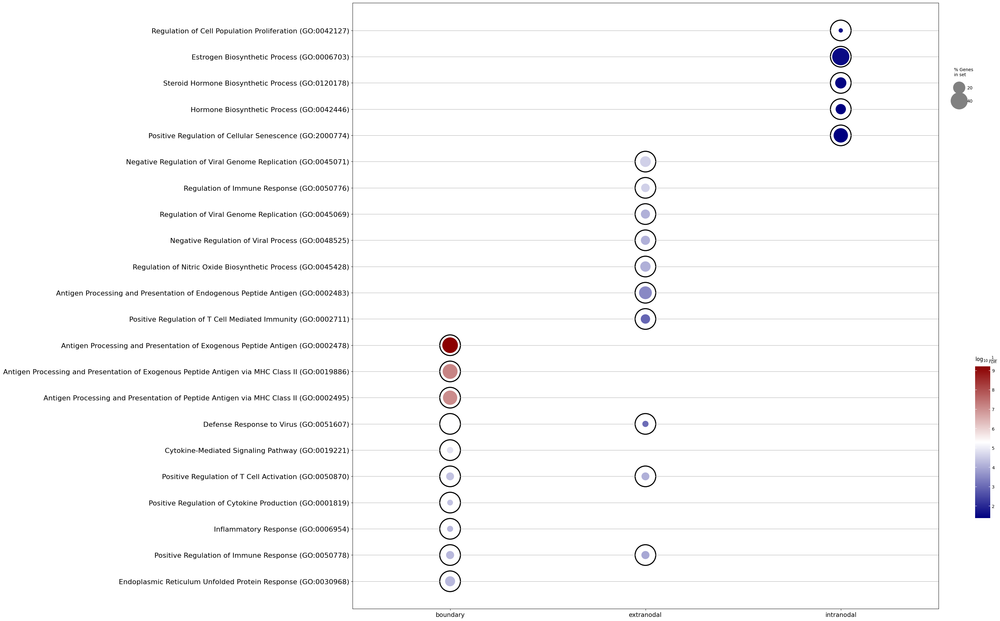

In [ ]:
from gseapy.scipalette import SciPalette
sci = SciPalette()
NbDr = sci.create_colormap()
# NbDr
ax = gp.dotplot(plot_df,figsize=(30,25),
                x='cluster',
                # x_order = ["UP","DOWN"],
                # title="GO_BP",
                cmap = NbDr,
                size=10,
                show_ring=True,
                )
ax.set_xlabel("")

fig = ax.figure
# fig.savefig("./fibro_gobp_pathway_dotplot.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
import scanpy as sc
from pathlib import Path

outdir = Path("./visum/DEG_ENE_region")
outdir.mkdir(parents=True, exist_ok=True)

# 提取所有区域的结果
deg = sc.get.rank_genes_groups_df(adata, group=None)

# 保存完整结果，group 列表示所属区域
deg.to_csv(outdir / "ENE_region_all_genes.csv", index=False)

# 分区域保存
for region, df in deg.groupby("group", observed=True):
    df.to_csv(outdir / f"{region}_all_genes.csv", index=False)

    # 筛选显著差异基因
    sig = df[
        (df["pvals_adj"] < 0.05)
        & (df["logfoldchanges"].abs() > 1)
    ]
    sig.to_csv(outdir / f"{region}_DEG.csv", index=False)

## 距离计算

In [ ]:
# adata.obs["ENE_region"] = adata_2.obs["ENE_region"].reindex(adata.obs_names)

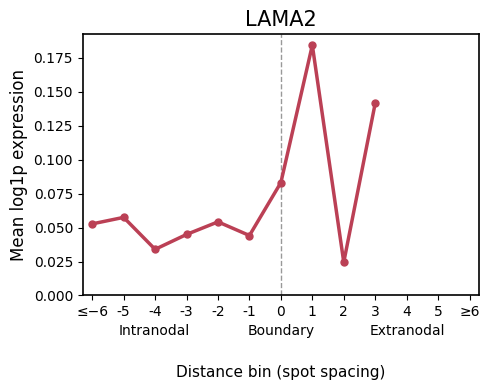

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from pathlib import Path

# ========= 参数 =========
SAMPLE = "HNSCC59"
REGION = "ENE_region"
KEY = "q05_cell_abundance_w_sf"

MAX_BIN = 6          # 第6层及更远的 spot 合并
MIN_SPOTS = 5        # 少于5个有效 spot 的距离层不画
CELL_TYPES = "CAF"   # None：展示平均占比最高的8类
# 也可以指定：
# CELL_TYPES = ["CAF_COL14A1", "myCAF_CTHRC1", "qCAF"]

outdir = Path("./visum/figure/ENE_gradient")
outdir.mkdir(parents=True, exist_ok=True)

# ========= 1. 提取样本 =========
slide = adata[adata.obs["sample"].eq(SAMPLE)].copy()

region_all = (
    slide.obs[REGION].astype("string").str.strip().str.lower()
    .replace({"extrnodal": "extranodal"})
)
keep = region_all.isin(["intranodal", "boundary", "extranodal"])
sub = slide[keep].copy()
region = region_all.loc[sub.obs_names]

xy_all = np.asarray(slide.obsm["spatial"], dtype=float)
xy = np.asarray(sub.obsm["spatial"], dtype=float)

boundary_mask = region.eq("boundary").to_numpy(dtype=bool)
if not boundary_mask.any():
    raise ValueError("没有 boundary spot")

# ========= 2. 计算距离分层 =========
# 用整张切片的最近邻距离中位数估计 spot 中心间距
nn_dist = cKDTree(xy_all).query(xy_all, k=2)[0][:, 1]
spacing = np.median(nn_dist[nn_dist > 0])

# 每个 spot 到最近 boundary spot 中心的距离
distance = cKDTree(xy[boundary_mask]).query(xy, k=1)[0]
distance_units = distance / spacing

# 按一个 spot 间距分层：
# 1层：(0, 1]；2层：(1, 2]；以此类推
level = np.maximum(
    1, np.ceil(distance_units - 1e-6).astype(int)
)
level = np.minimum(level, MAX_BIN)

sign = np.where(region.eq("intranodal"), -1, 1)
distance_bin = sign * level
distance_bin[boundary_mask] = 0

sub.obs["boundary_distance_bin"] = distance_bin

import scipy.sparse as sp

# ========= 3. 提取基因表达 =========
GENE = "LAMA2"
USE_RAW = True    # 与你前面的差异分析保持一致
                 # 注意：raw 中应为归一化后的 log1p 表达，并不一定是 counts

source = sub.raw if USE_RAW else sub

if source is None:
    raise ValueError("sub.raw 不存在，请改用 USE_RAW=False")
if GENE not in source.var_names:
    raise ValueError(f"{GENE} 不在所选表达矩阵中")

x = source[:, [GENE]].X
expression = x.toarray().ravel() if sp.issparse(x) else np.asarray(x).ravel()

df = pd.DataFrame({
    "distance_bin": sub.obs["boundary_distance_bin"].to_numpy(),
    "expression": expression,
}, index=sub.obs_names)

# ========= 4. 按距离层汇总，包含零表达 spot =========
bin_order = np.arange(-MAX_BIN, MAX_BIN + 1)

profile = (
    df.groupby("distance_bin")["expression"]
    .agg(
        mean_expression="mean",
        median_expression="median",
        n_spots="count",
    )
    .reindex(bin_order)
)

# spot 过少的层不绘制，避免不稳定的均值
y = profile["mean_expression"].where(
    profile["n_spots"] >= MIN_SPOTS
)

# ========= 5. 绘图 =========
fig, ax = plt.subplots(figsize=(5, 4))

ax.plot(
    profile.index, y,
    color="#bb4055",
    linewidth=2.5,
    marker="o",
    markersize=5
)

ax.axvline(
    0, color="0.6", linestyle="--",
    linewidth=1, zorder=0
)

labels = [str(i) for i in bin_order]
labels[0] = f"≤−{MAX_BIN}"
labels[-1] = f"≥{MAX_BIN}"

ax.set_xticks(bin_order)
ax.set_xticklabels(labels)
ax.set_xlim(-MAX_BIN - 0.3, MAX_BIN + 0.3)
ax.set_ylim(bottom=0)

ax.set_title(GENE, fontsize=15)
ax.set_ylabel("Mean log1p expression", fontsize=12)
ax.set_xlabel("Distance bin (spot spacing)", labelpad=33, fontsize=11)

for pos, label in [
    (0.18, "Intranodal"),
    (0.50, "Boundary"),
    (0.82, "Extranodal"),
]:
    ax.text(
        pos, -0.15, label,
        transform=ax.transAxes,
        ha="center", fontsize=10
    )

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

fig.tight_layout()
# fig.savefig(
#     outdir / f"{SAMPLE}_{GENE}_distance_gradient.tiff",
#     dpi=600,
#     bbox_inches="tight",
#     pil_kwargs={"compression": "tiff_lzw"}
# )
plt.show()

# 保存每层的统计结果
# profile.to_csv(outdir / f"{SAMPLE}_{GENE}_distance_expression.csv")

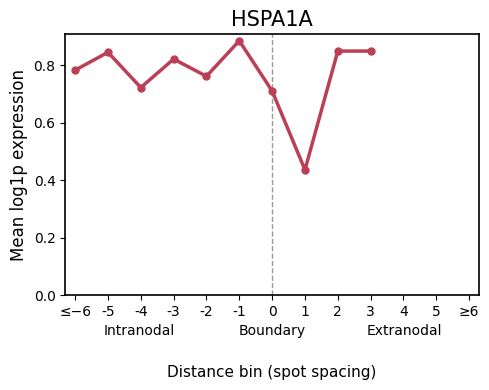

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from pathlib import Path

# ========= 参数 =========
SAMPLE = "HNSCC59"
REGION = "ENE_region"
KEY = "q05_cell_abundance_w_sf"

MAX_BIN = 6          # 第6层及更远的 spot 合并
MIN_SPOTS = 5        # 少于5个有效 spot 的距离层不画
CELL_TYPES = "CAF"   # None：展示平均占比最高的8类
# 也可以指定：
# CELL_TYPES = ["CAF_COL14A1", "myCAF_CTHRC1", "qCAF"]

outdir = Path("./visum/figure/ENE_gradient")
outdir.mkdir(parents=True, exist_ok=True)

# ========= 1. 提取样本 =========
slide = adata[adata.obs["sample"].eq(SAMPLE)].copy()

region_all = (
    slide.obs[REGION].astype("string").str.strip().str.lower()
    .replace({"extrnodal": "extranodal"})
)
keep = region_all.isin(["intranodal", "boundary", "extranodal"])
sub = slide[keep].copy()
region = region_all.loc[sub.obs_names]

xy_all = np.asarray(slide.obsm["spatial"], dtype=float)
xy = np.asarray(sub.obsm["spatial"], dtype=float)

boundary_mask = region.eq("boundary").to_numpy(dtype=bool)
if not boundary_mask.any():
    raise ValueError("没有 boundary spot")

# ========= 2. 计算距离分层 =========
# 用整张切片的最近邻距离中位数估计 spot 中心间距
nn_dist = cKDTree(xy_all).query(xy_all, k=2)[0][:, 1]
spacing = np.median(nn_dist[nn_dist > 0])

# 每个 spot 到最近 boundary spot 中心的距离
distance = cKDTree(xy[boundary_mask]).query(xy, k=1)[0]
distance_units = distance / spacing

# 按一个 spot 间距分层：
# 1层：(0, 1]；2层：(1, 2]；以此类推
level = np.maximum(
    1, np.ceil(distance_units - 1e-6).astype(int)
)
level = np.minimum(level, MAX_BIN)

sign = np.where(region.eq("intranodal"), -1, 1)
distance_bin = sign * level
distance_bin[boundary_mask] = 0

sub.obs["boundary_distance_bin"] = distance_bin

import scipy.sparse as sp

# ========= 3. 提取基因表达 =========
GENE = "HSPA1A"
USE_RAW = True    # 与你前面的差异分析保持一致
                 # 注意：raw 中应为归一化后的 log1p 表达，并不一定是 counts

source = sub.raw if USE_RAW else sub

if source is None:
    raise ValueError("sub.raw 不存在，请改用 USE_RAW=False")
if GENE not in source.var_names:
    raise ValueError(f"{GENE} 不在所选表达矩阵中")

x = source[:, [GENE]].X
expression = x.toarray().ravel() if sp.issparse(x) else np.asarray(x).ravel()

df = pd.DataFrame({
    "distance_bin": sub.obs["boundary_distance_bin"].to_numpy(),
    "expression": expression,
}, index=sub.obs_names)

# ========= 4. 按距离层汇总，包含零表达 spot =========
bin_order = np.arange(-MAX_BIN, MAX_BIN + 1)

profile = (
    df.groupby("distance_bin")["expression"]
    .agg(
        mean_expression="mean",
        median_expression="median",
        n_spots="count",
    )
    .reindex(bin_order)
)

# spot 过少的层不绘制，避免不稳定的均值
y = profile["mean_expression"].where(
    profile["n_spots"] >= MIN_SPOTS
)

# ========= 5. 绘图 =========
fig, ax = plt.subplots(figsize=(5, 4))

ax.plot(
    profile.index, y,
    color="#bb4055",
    linewidth=2.5,
    marker="o",
    markersize=5
)

ax.axvline(
    0, color="0.6", linestyle="--",
    linewidth=1, zorder=0
)

labels = [str(i) for i in bin_order]
labels[0] = f"≤−{MAX_BIN}"
labels[-1] = f"≥{MAX_BIN}"

ax.set_xticks(bin_order)
ax.set_xticklabels(labels)
ax.set_xlim(-MAX_BIN - 0.3, MAX_BIN + 0.3)
ax.set_ylim(bottom=0)

ax.set_title(GENE, fontsize=15)
ax.set_ylabel("Mean log1p expression", fontsize=12)
ax.set_xlabel("Distance bin (spot spacing)", labelpad=33, fontsize=11)

for pos, label in [
    (0.18, "Intranodal"),
    (0.50, "Boundary"),
    (0.82, "Extranodal"),
]:
    ax.text(
        pos, -0.15, label,
        transform=ax.transAxes,
        ha="center", fontsize=10
    )

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

fig.tight_layout()
# fig.savefig(
#     outdir / f"{SAMPLE}_{GENE}_distance_gradient.tiff",
#     dpi=600,
#     bbox_inches="tight",
#     pil_kwargs={"compression": "tiff_lzw"}
# )
plt.show()

# 保存每层的统计结果
# profile.to_csv(outdir / f"{SAMPLE}_{GENE}_distance_expression.csv")

# inte distance

In [ ]:
adata =sc.read_h5ad("./visum/data/LN inte.h5ad")

In [ ]:
import pandas as pd

# 1. 读取注释
anno = pd.read_csv("./visum/anno14 LN.csv", index_col=0)
print(anno.head())   # 查看实际的分组列名

ANNO_COL = "anno2"       # 修改为 CSV 中的分组列名
OUT_COL = "ENE_region"    # 写入 adata.obs 的列名

# 兼容 AAACA...-1、HNSCC14_AAACA...-1、
# HNSCC14_HNSCC14_AAACA...-1 等 spot 名
def clean_spot(index):
    return (
        pd.Index(index).astype(str).str.strip()
        .str.replace(r"^(?:HNSCC14_)+", "", regex=True)
    )

anno.index = clean_spot(anno.index)

if not anno.index.is_unique:
    raise ValueError("anno.csv 中清理后的 spot 名存在重复，请检查")

# 2. 整理区域名称，将 extrnodal 拼写统一为 extranodal
region = (
    anno[ANNO_COL]
    .astype("string")
    .str.strip()
    .replace({"extrnodal": "extranodal"})
)

# 3. 仅匹配 HNSCC14
mask = adata.obs["sample"].eq("HNSCC14")
spot_ids = clean_spot(adata.obs_names[mask])
matched = region.reindex(spot_ids)

if matched.notna().sum() == 0:
    raise ValueError(
        "没有匹配到有效注释，请检查 spot 名和分组列名。\n"
        f"adata 示例：{spot_ids[:3].tolist()}\n"
        f"CSV 示例：{anno.index[:3].tolist()}"
    )

# 4. 写入 obs；未匹配的 spot 保留为空
if OUT_COL not in adata.obs:
    adata.obs[OUT_COL] = pd.Series(
        pd.NA, index=adata.obs_names, dtype="string"
    )
else:
    adata.obs[OUT_COL] = adata.obs[OUT_COL].astype("string")

# 使用数组，避免清理后的 spot 名再次参与索引对齐
adata.obs.loc[mask, OUT_COL] = matched.to_numpy()

print(f"HNSCC14：成功注释 {matched.notna().sum()} / {mask.sum()} 个 spot")
print(adata.obs.loc[mask, OUT_COL].value_counts(dropna=False))

                                        anno2
Barcode                                      
AAACAAGTATCTCCCA-1                      Tumor
AAACAATCTACTAGCA-1  Thickened fibrous capsule
AAACACCAATAACTGC-1                      Tumor
AAACAGAGCGACTCCT-1                      Tumor
AAACAGCTTTCAGAAG-1                      Tumor
HNSCC14：成功注释 3931 / 3932 个 spot
ENE_region
Tumor                        3385
Thickened fibrous capsule     317
CAF                           229
<NA>                            1
Name: count, dtype: Int64


In [ ]:
import pandas as pd
import re

SAMPLE = "HNSCC59"

# ========= 1. 读取注释 =========
anno59 = pd.read_csv("./visum/anno59 LN.csv")
anno59["Barcode"] = anno59["Barcode"].astype(str).str.strip()

anno_map = anno59.set_index("Barcode")["anno2"]

# ========= 2. 准备注释列，保留其他样本的已有注释 =========
if "ENE_region" not in adata.obs.columns:
    adata.obs["ENE_region"] = pd.NA
else:
    adata.obs["ENE_region"] = adata.obs["ENE_region"].astype(object)

mask59 = adata.obs["sample"].eq(SAMPLE)

# ========= 3. 去掉开头的样本名及分隔符 =========
names59 = adata.obs_names[mask59].astype(str)

clean_names59 = names59.str.replace(
    rf"^{re.escape(SAMPLE)}[_:\-]+",
    "",
    regex=True,
).str.strip()

# 看一下清理结果
print(pd.DataFrame({
    "原始名称": names59[:5],
    "匹配用barcode": clean_names59[:5],
}))

# ========= 4. 精确匹配并写入 =========
matched = pd.Series(
    clean_names59.to_numpy(),
    index=names59,
).map(anno_map)

adata.obs.loc[mask59, "ENE_region"] = matched.to_numpy()

# ========= 5. 检查匹配情况 =========
n_total = int(mask59.sum())
n_match = int(matched.notna().sum())

print("HNSCC59 总spot数:", n_total)
print("成功匹配:", n_match)
print("未匹配:", n_total - n_match)
print("匹配率:", f"{n_match / n_total:.2%}" if n_total else "无该样本")

print("\n注释分布：")
print(adata.obs.loc[mask59, "ENE_region"].value_counts(dropna=False))

if matched.isna().any():
    print("\n未匹配的 barcode（前10个）：")
    print(clean_names59[matched.isna().to_numpy()][:10].tolist())

                   原始名称            匹配用barcode
0    AAACAACGAATAGTTC-1    AAACAACGAATAGTTC-1
1  AAACAAGTATCTCCCA-1-1  AAACAAGTATCTCCCA-1-1
2  AAACAATCTACTAGCA-1-1  AAACAATCTACTAGCA-1-1
3  AAACACCAATAACTGC-1-1  AAACACCAATAACTGC-1-1
4  AAACAGAGCGACTCCT-1-1  AAACAGAGCGACTCCT-1-1
HNSCC59 总spot数: 4536
成功匹配: 656
未匹配: 3880
匹配率: 14.46%

注释分布：
ENE_region
NaN                       3880
Tumor                      586
Tinned fibrous capsule      70
Name: count, dtype: int64

未匹配的 barcode（前10个）：
['AAACAAGTATCTCCCA-1-1', 'AAACAATCTACTAGCA-1-1', 'AAACACCAATAACTGC-1-1', 'AAACAGAGCGACTCCT-1-1', 'AAACAGCTTTCAGAAG-1-1', 'AAACAGGGTCTATATT-1-1', 'AAACAGTGTTCCTGGG-1-1', 'AAACATGGTGAGAGGA-1-1', 'AAACCACTACACAGAT-1-1', 'AAACCCGAACGAAATC-1-1']


In [ ]:
import pandas as pd
import re

SAMPLE = "HNSCC59"

# =========================
# 1. Barcode 标准化函数
# =========================
def clean_barcode(x):
    x = str(x).strip()

    # 删除样本名前缀
    x = re.sub(
        rf"^(?:{re.escape(SAMPLE)}[_:\-]+)+",
        "",
        x
    )

    # 将重复的 -1 统一为 -1
    # AAACAAGTATCTCCCA-1-1 -> AAACAAGTATCTCCCA-1
    x = re.sub(r"(?:-1)+$", "-1", x)

    return x


# =========================
# 2. 读取注释
# =========================
anno59 = pd.read_csv("./visum/anno59 LN.csv")

anno59["barcode_clean"] = (
    anno59["Barcode"]
    .map(clean_barcode)
)

# 统一注释名称
anno59["anno2"] = (
    anno59["anno2"]
    .replace({"extrnodal": "extranodal"})
)

# 检查 CSV 中重复 barcode 是否有不同注释
conflicts = (
    anno59.groupby("barcode_clean")["anno2"]
    .nunique(dropna=True)
)

if (conflicts > 1).any():
    raise ValueError(
        "CSV中存在相同barcode对应不同注释，请检查："
        + str(conflicts[conflicts > 1].index.tolist()[:10])
    )

# 去除标准化后的重复 barcode
anno_map = (
    anno59.dropna(subset=["anno2"])
    .drop_duplicates(subset="barcode_clean")
    .set_index("barcode_clean")["anno2"]
)


# =========================
# 3. 提取 HNSCC59
# =========================
mask59 = adata.obs["sample"].eq(SAMPLE)

names59 = adata.obs_names[mask59].astype(str)

clean_names59 = pd.Index(
    [clean_barcode(x) for x in names59]
)

print("Barcode清理示例：")
print(pd.DataFrame({
    "原始名称": names59[:10],
    "清理后": clean_names59[:10]
}))


# =========================
# 4. 匹配注释
# =========================
matched = pd.Series(
    clean_names59.to_numpy(),
    index=names59
).map(anno_map)

if "ENE_region" not in adata.obs.columns:
    adata.obs["ENE_region"] = pd.NA
else:
    adata.obs["ENE_region"] = (
        adata.obs["ENE_region"].astype(object)
    )

# 只修改 HNSCC59
adata.obs.loc[
    mask59, "ENE_region"
] = matched.to_numpy()


# =========================
# 5. 检查结果
# =========================
n_total = int(mask59.sum())
n_barcode_match = int(clean_names59.isin(
    anno59["barcode_clean"]
).sum())
n_match = int(matched.notna().sum())

print("\n========== 匹配结果 ==========")

print("HNSCC59 总spot数:", n_total)
print("Barcode匹配数:", n_barcode_match)
print("有有效注释数:", n_match)
print("未获得注释:", n_total - n_match)

print(
    "有效注释率:",
    f"{n_match / n_total:.2%}"
)

print("\n注释分布：")
print(
    adata.obs.loc[
        mask59, "ENE_region"
    ].value_counts(dropna=False)
)

print("\n========== Barcode重复检查 ==========")
print("原始barcode数量:", len(names59))
print("标准化后唯一barcode数:", clean_names59.nunique())
print("标准化后重复数量:", clean_names59.duplicated().sum())

# 未匹配 barcode
unmatched = clean_names59[
    ~clean_names59.isin(anno59["barcode_clean"])
]

print("\nCSV中不存在的barcode（前10个）：")
print(unmatched[:10].tolist())

Barcode清理示例：
                   原始名称                 清理后
0    AAACAACGAATAGTTC-1  AAACAACGAATAGTTC-1
1  AAACAAGTATCTCCCA-1-1  AAACAAGTATCTCCCA-1
2  AAACAATCTACTAGCA-1-1  AAACAATCTACTAGCA-1
3  AAACACCAATAACTGC-1-1  AAACACCAATAACTGC-1
4  AAACAGAGCGACTCCT-1-1  AAACAGAGCGACTCCT-1
5  AAACAGCTTTCAGAAG-1-1  AAACAGCTTTCAGAAG-1
6  AAACAGGGTCTATATT-1-1  AAACAGGGTCTATATT-1
7  AAACAGTGTTCCTGGG-1-1  AAACAGTGTTCCTGGG-1
8  AAACATGGTGAGAGGA-1-1  AAACATGGTGAGAGGA-1
9    AAACATTTCCCGGATT-1  AAACATTTCCCGGATT-1

========== 匹配结果 ==========
HNSCC59 总spot数: 4536
Barcode匹配数: 4536
有有效注释数: 4535
未获得注释: 1
有效注释率: 99.98%

注释分布：
ENE_region
Tumor                     4465
Tinned fibrous capsule      70
NaN                          1
Name: count, dtype: int64

========== Barcode重复检查 ==========
原始barcode数量: 4536
标准化后唯一barcode数: 4536
标准化后重复数量: 0

CSV中不存在的barcode（前10个）：
[]


In [ ]:
adata.obs["ENE_region"].value_counts()

ENE_region
Tumor                        7850
Thickened fibrous capsule     317
CAF                           229
Tinned fibrous capsule         70
Name: count, dtype: int64

In [ ]:
adata.obs["ENE_region"] = (
    adata.obs["ENE_region"]
    .astype(object)
    .replace({
        "Thickened fibrous capsule": "Fibrous capsule",
        "Tinned fibrous capsule": "Fibrous capsule",
        "CAF": "Fibrous Stroma",
    })
)

# 检查
print(adata.obs["ENE_region"].value_counts(dropna=False))

ENE_region
Tumor              7850
Fibrous capsule     387
Fibrous Stroma      229
<NA>                  1
NaN                   1
Name: count, dtype: int64


/tmp/ipykernel_70522/4197146858.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()


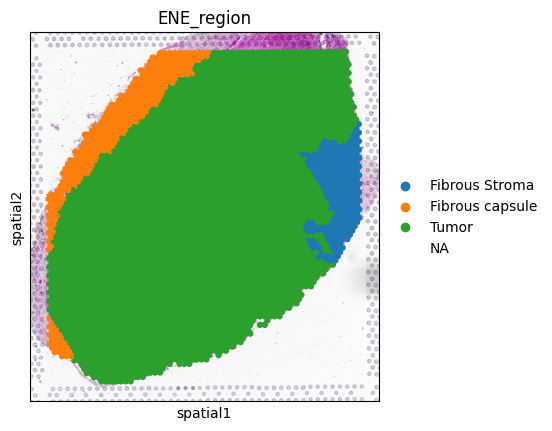

In [ ]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC14"],
    color="ENE_region",
    library_id="HNSCC14",
    img_key="hires",
    spot_size=150,
    # cmap="RdBu_r",
    # vmin=vmin,
    # vmax="p99.2"
)

/tmp/ipykernel_70522/1981624960.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()


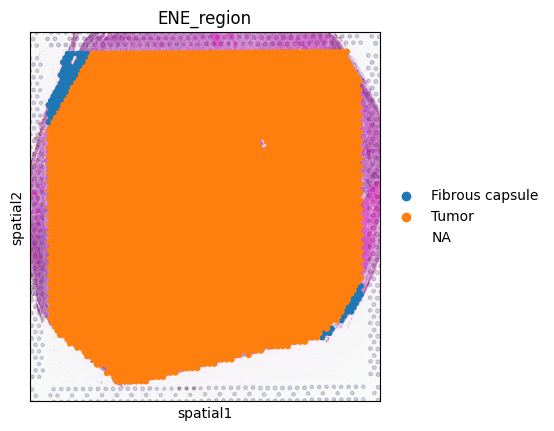

In [ ]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC59"],
    color="ENE_region",
    library_id="HNSCC59",
    img_key="hires",
    spot_size=150,
    # cmap="RdBu_r",
    # vmin=vmin,
    # vmax="p99.2"
)

In [ ]:
adata = adata[adata.obs["ENE_region"].notna()].copy()

In [ ]:
print(adata.obs["ENE_region"].value_counts(dropna=False))

ENE_region
Tumor              7850
Fibrous capsule     387
Fibrous Stroma      229
Name: count, dtype: int64


保存成功: HNSCC14_LAMA2_interface.tiff
文件大小: 1463.4 KB
保存成功: HNSCC14_LAMA2_interface.png
文件大小: 182.1 KB
保存成功: HNSCC14_LAMA2_gradient.tiff
文件大小: 441.8 KB
保存成功: HNSCC14_LAMA2_gradient.png
文件大小: 113.3 KB

输出文件夹: visum/figure/LN


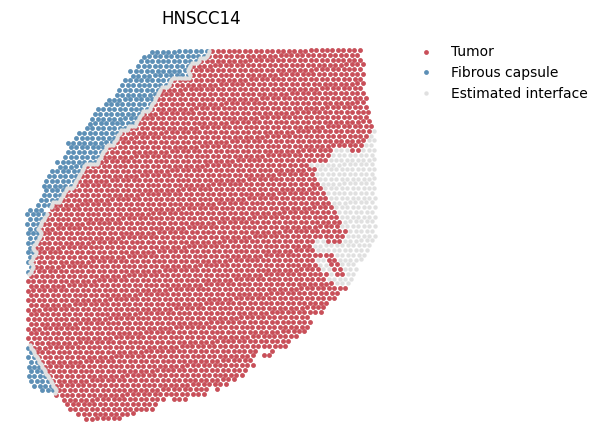

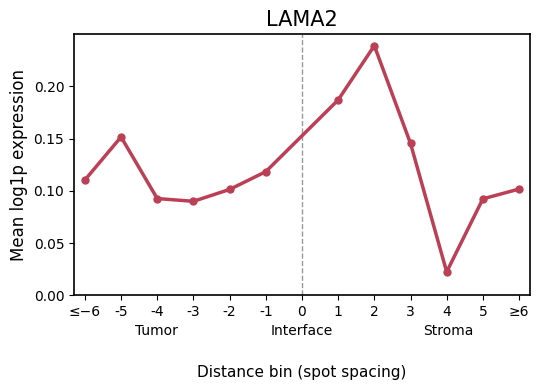

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.spatial import cKDTree
from pathlib import Path

# ========= 参数 =========
SAMPLE = "HNSCC14"        # 改成这张切片的实际 sample 名称
REGION = "ENE_region"
GENE = "LAMA2"

TUMOR_LABEL = "Tumor"
CAPSULE_LABEL = "Fibrous capsule"

USE_RAW = True           # 确认 raw.X 是归一化后的 log1p 表达
MAX_BIN = 6               # 第6层及更远的 spot 合并
MIN_SPOTS = 5
ADJ_FACTOR = 1.2          # 跨区域相邻 spot 的最大距离 / spot间距
SAVE = False             # 改为 True 保存 TIFF 和 CSV

outdir = Path("./visum/figure/LN")

# ========= 1. 提取样本 =========
slide = adata[adata.obs["sample"].eq(SAMPLE)].copy()

if slide.n_obs < 2:
    raise ValueError(f"{SAMPLE} 的 spot 数不足，请检查 SAMPLE")

region_all = (
    slide.obs[REGION]
    .astype("string")
    .str.strip()
    # .str.lower()
)

# 仅保留 tumor 和被膜
keep = region_all.isin([TUMOR_LABEL, CAPSULE_LABEL])
sub = slide[keep.to_numpy()].copy()
region = region_all.loc[sub.obs_names]

xy_all = np.asarray(slide.obsm["spatial"], dtype=float)
xy = np.asarray(sub.obsm["spatial"], dtype=float)

if not np.isfinite(xy_all).all():
    raise ValueError("spatial 坐标包含缺失值或无穷值")

tumor_mask = region.eq(TUMOR_LABEL).to_numpy(dtype=bool)
capsule_mask = region.eq(CAPSULE_LABEL).to_numpy(dtype=bool)

if not tumor_mask.any() or not capsule_mask.any():
    raise ValueError(
        "需要同时存在 tumor 和 thickened fibrous capsule。\n"
        f"当前标签：{region_all.dropna().unique().tolist()}"
    )

# ========= 2. 估计 spot 中心间距 =========
nn_dist = cKDTree(xy_all).query(xy_all, k=2)[0][:, 1]
valid_dist = nn_dist[np.isfinite(nn_dist) & (nn_dist > 0)]

if valid_dist.size == 0:
    raise ValueError("无法估计 spot 间距")

spacing = np.median(valid_dist)

# ========= 3. 找到 tumor–被膜交界 =========
xy_tumor = xy[tumor_mask]
xy_capsule = xy[capsule_mask]

neighbors = cKDTree(xy_tumor).query_ball_tree(
    cKDTree(xy_capsule),
    r=ADJ_FACTOR * spacing,
)

pairs = np.array(
    [(i, j) for i, js in enumerate(neighbors) for j in js],
    dtype=int,
).reshape(-1, 2)

if len(pairs) == 0:
    raise ValueError(
        "没有找到相邻的 tumor–被膜 spot，"
        "请检查两类标注是否直接接壤。"
    )

# 跨区域相邻 spot 的中点，作为交界参考点
interface_xy = (
    xy_tumor[pairs[:, 0]] + xy_capsule[pairs[:, 1]]
) / 2

interface_xy = np.unique(interface_xy, axis=0)

# ========= 4. 计算距离分层 =========
# 到最近交界参考点的欧氏距离
distance = cKDTree(interface_xy).query(xy, k=1)[0]
distance_units = distance / spacing

# 第1层：(0, 1]；第2层：(1, 2]；以此类推
level = np.maximum(
    1,
    np.ceil(distance_units - 1e-6).astype(int),
)
level = np.minimum(level, MAX_BIN)

# tumor 为负，被膜为正
sign = np.where(tumor_mask, -1, 1)
distance_bin = sign * level

sub.obs["tumor_capsule_distance"] = sign * distance_units
sub.obs["tumor_capsule_bin"] = distance_bin

# ========= 5. 提取表达 =========
source = sub.raw if USE_RAW else sub

if source is None:
    raise ValueError("sub.raw 不存在，请设置 USE_RAW=False")

if GENE not in source.var_names:
    raise ValueError(f"{GENE} 不在所选表达矩阵中")

x = source[:, [GENE]].X
expression = (
    x.toarray().ravel()
    if sp.issparse(x)
    else np.asarray(x).ravel()
).astype(float)

expression[~np.isfinite(expression)] = np.nan

df = pd.DataFrame({
    "region": region.to_numpy(),
    "distance_signed": sign * distance_units,
    "distance_bin": distance_bin,
    "expression": expression,
}, index=sub.obs_names)

# ========= 6. 汇总每层表达，包含0值 =========
bin_order = np.r_[
    np.arange(-MAX_BIN, 0),
    np.arange(1, MAX_BIN + 1),
]

profile = (
    df.groupby("distance_bin")["expression"]
    .agg(
        mean_expression="mean",
        median_expression="median",
        n_spots="count",
    )
    .reindex(bin_order)
)

profile.index.name = "distance_bin"
profile["n_spots"] = profile["n_spots"].fillna(0).astype(int)

y = profile["mean_expression"].where(
    profile["n_spots"] >= MIN_SPOTS
)

# ========= 7. 交界定位检查图 =========
fig_check, ax_check = plt.subplots(figsize=(6, 6))

# 整张切片作为浅灰色背景
ax_check.scatter(
    xy_all[:, 0], xy_all[:, 1],
    s=10, color="#E0E0E0",
    linewidths=0,
)

ax_check.scatter(
    xy_tumor[:, 0], xy_tumor[:, 1],
    s=12, color="#C94F59",##80c2ba
    linewidths=0, label="Tumor",
)

ax_check.scatter(
    xy_capsule[:, 0], xy_capsule[:, 1],
    s=12, color="#5C8FB6",#eba07f
    linewidths=0, label="Fibrous capsule",
)

# 不连接中点，避免把不连续的交界强行连起来
ax_check.scatter(
    interface_xy[:, 0], interface_xy[:, 1],
    s=10, color="#E0E0E0",
    linewidths=0, label="Estimated interface",
    zorder=5,
)

ax_check.set_aspect("equal")
ax_check.invert_yaxis()
ax_check.set_axis_off()
ax_check.set_title(f"{SAMPLE}")
ax_check.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False,
)
fig_check.tight_layout()

# ========= 8. 表达梯度图 =========
fig, ax = plt.subplots(figsize=(5.5, 4))

# 两侧分别画；0处没有实际表达观测值
ax.plot(
    profile.index,
    y,
    color="#bb4055",
    linewidth=2.5,
    marker="o",
    markersize=5,
)

ax.axvline(
    0,
    color="0.6",
    linestyle="--",
    linewidth=1,
    zorder=0,
)

ticks = np.arange(-MAX_BIN, MAX_BIN + 1)
labels = [str(i) for i in ticks]
labels[0] = f"≤−{MAX_BIN}"
labels[-1] = f"≥{MAX_BIN}"

ax.set_xticks(ticks)
ax.set_xticklabels(labels)
ax.set_xlim(-MAX_BIN - 0.3, MAX_BIN + 0.3)
ax.set_ylim(bottom=0)

ax.set_title(GENE, fontsize=15)
ax.set_ylabel("Mean log1p expression", fontsize=12)
ax.set_xlabel(
    "Distance bin (spot spacing)",
    labelpad=33,
    fontsize=11,
)

for pos, label in [
    (0.18, "Tumor"),
    (0.50, "Interface"),
    (0.82, "Stroma"),
]:
    ax.text(
        pos, -0.15, label,
        transform=ax.transAxes,
        ha="center",
        fontsize=10,
    )

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

fig.tight_layout()

# ========= 9. 分别保存图片 =========
from pathlib import Path
import matplotlib.pyplot as plt

# outdir = Path("./visum/figure/LN").resolve()
# outdir.mkdir(parents=True, exist_ok=True)

prefix = f"{SAMPLE}_{GENE}"

# 分别保存两个 Figure
figures = {
    "interface": fig_check,
    "gradient": fig,
}

for name, figure in figures.items():

    # TIFF，600 dpi，LZW压缩
    tiff_path = outdir / f"{prefix}_{name}.tiff"

    figure.savefig(
        tiff_path,
        format="tiff",
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
        pil_kwargs={"compression": "tiff_lzw"},
    )

    # PNG，300 dpi
    png_path = outdir / f"{prefix}_{name}.png"

    figure.savefig(
        png_path,
        format="png",
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    # 检查文件是否存在
    for path in [tiff_path, png_path]:
        if path.exists() and path.stat().st_size > 0:
            print(f"保存成功: {path.name}")
            print(f"文件大小: {path.stat().st_size / 1024:.1f} KB")
        else:
            print(f"保存失败: {path}")

# 保存数据
profile.to_csv(outdir / f"{prefix}_profile.csv")
df.to_csv(outdir / f"{prefix}_spot_data.csv")

print(f"\n输出文件夹: {outdir}")

plt.show()

病理区域 spot 数量：
ENE_region
Tumor              3385
Fibrous capsule     317
Fibrous Stroma      229
Name: count, dtype: Int64

Spot spacing: 116.970
Tumor–capsule 邻接边数: 141
估计交界点数: 141

结果已保存至: visum/figure/ln


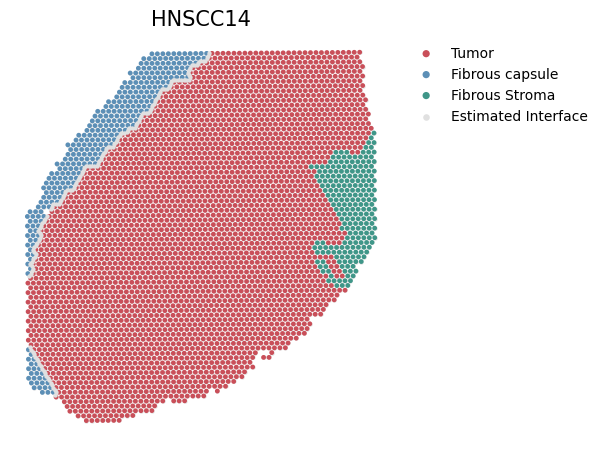

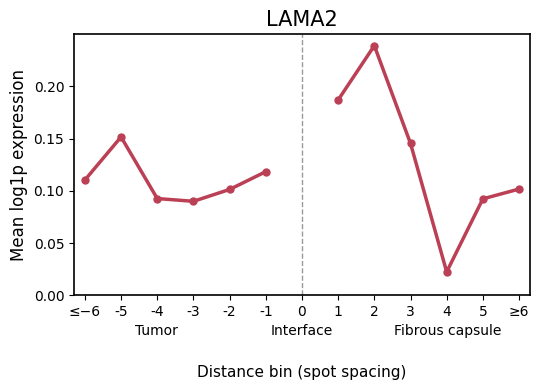

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp

from scipy.spatial import cKDTree
from pathlib import Path

# =========================
# 1. 参数
# =========================
SAMPLE = "HNSCC14"
REGION = "ENE_region"
GENE = "LAMA2"

TUMOR_LABEL = "Tumor"
CAPSULE_LABEL = "Fibrous capsule"
STROMA_LABEL = "Fibrous Stroma"

USE_RAW = True

MAX_BIN = 6
MIN_SPOTS = 5
ADJ_FACTOR = 1.2

SAVE = True

outdir = Path("./visum/figure/ln")
outdir.mkdir(parents=True, exist_ok=True)

# 配色
COLORS = {
    "Tumor": "#C94F59",
    "Fibrous capsule": "#5C8FB6",
    "Fibrous Stroma": "#3F9688",
    "Interface": "#E0E0E0",
    # "Other": "#E0E0E0",
}

# =========================
# 2. 提取样本及病理区域
# =========================
slide = adata[
    adata.obs["sample"].eq(SAMPLE)
].copy()

if slide.n_obs < 2:
    raise ValueError(f"{SAMPLE} 的 spot 数不足")

region_all = (
    slide.obs[REGION]
    .astype("string")
    .str.strip()
    .replace({
        "Fibrous_stroma": "Fibrous Stroma",
        "Thickened fibrous capsule": "Fibrous capsule",
        "Tinned fibrous capsule": "Fibrous capsule",
    })
)

region_values = (
    region_all.fillna("Unannotated")
    .to_numpy(dtype=str)
)

xy_all = np.asarray(
    slide.obsm["spatial"],
    dtype=float
)

if not np.isfinite(xy_all).all():
    raise ValueError("spatial 坐标存在非有限值")

print("病理区域 spot 数量：")
print(region_all.value_counts(dropna=False))

# =========================
# 3. 计算 spot 间距
# =========================
tree_all = cKDTree(xy_all)

nn_dist = tree_all.query(
    xy_all,
    k=2
)[0][:, 1]

valid_dist = nn_dist[
    np.isfinite(nn_dist) & (nn_dist > 0)
]

if len(valid_dist) == 0:
    raise ValueError("无法估计 spot 间距")

spacing = np.median(valid_dist)

print(f"\nSpot spacing: {spacing:.3f}")

# =========================
# 4. 建立整张切片的邻接关系
# =========================
# 关键修改：
# 先用全部 spot 建立真实邻接关系，
# 再筛选 Tumor 与 Fibrous capsule 的直接邻接边。

all_pairs = np.array(
    list(tree_all.query_pairs(
        r=ADJ_FACTOR * spacing
    )),
    dtype=int
).reshape(-1, 2)

if len(all_pairs) == 0:
    raise ValueError("没有找到相邻 spot")

label_i = region_values[all_pairs[:, 0]]
label_j = region_values[all_pairs[:, 1]]

# 仅 Tumor–Fibrous capsule 邻接
tc_mask = (
    (
        (label_i == TUMOR_LABEL) &
        (label_j == CAPSULE_LABEL)
    )
    |
    (
        (label_i == CAPSULE_LABEL) &
        (label_j == TUMOR_LABEL)
    )
)

boundary_pairs = all_pairs[tc_mask]

if len(boundary_pairs) == 0:
    raise ValueError(
        "没有找到直接相邻的 Tumor–Fibrous capsule spot"
    )

# 交界点：直接相邻的两个 spot 中点
interface_xy = (
    xy_all[boundary_pairs[:, 0]] +
    xy_all[boundary_pairs[:, 1]]
) / 2

interface_xy = np.unique(
    interface_xy,
    axis=0
)

print("Tumor–capsule 邻接边数:", len(boundary_pairs))
print("估计交界点数:", len(interface_xy))

# =========================
# 5. 只计算 Tumor–capsule 距离
# =========================
# Fibrous Stroma 不参与梯度分析

keep = np.isin(
    region_values,
    [TUMOR_LABEL, CAPSULE_LABEL]
)

sub = slide[keep].copy()

region = region_values[keep]

xy = xy_all[keep]

tumor_mask = region == TUMOR_LABEL
capsule_mask = region == CAPSULE_LABEL

if not tumor_mask.any() or not capsule_mask.any():
    raise ValueError("Tumor 或 Fibrous capsule 为空")

# 到最近交界点的距离
interface_tree = cKDTree(interface_xy)

distance = interface_tree.query(
    xy,
    k=1
)[0]

distance_units = distance / spacing

# 距离分层
level = np.maximum(
    1,
    np.ceil(distance_units - 1e-6).astype(int)
)

level = np.minimum(
    level,
    MAX_BIN
)

# Tumor 负方向，Capsule 正方向
sign = np.where(tumor_mask, -1, 1)

distance_bin = sign * level

sub.obs["tumor_capsule_distance"] = (
    sign * distance_units
)

sub.obs["tumor_capsule_bin"] = distance_bin

# =========================
# 6. 提取基因表达
# =========================
source = sub.raw if USE_RAW else sub

if source is None:
    raise ValueError("sub.raw 不存在")

if GENE not in source.var_names:
    raise ValueError(f"{GENE} 不在表达矩阵中")

x = source[:, [GENE]].X

expression = (
    x.toarray().ravel()
    if sp.issparse(x)
    else np.asarray(x).ravel()
).astype(float)

expression[~np.isfinite(expression)] = np.nan

df = pd.DataFrame({
    "region": region,
    "distance_signed": sign * distance_units,
    "distance_bin": distance_bin,
    "expression": expression,
}, index=sub.obs_names)

# =========================
# 7. 统计每层平均表达
# =========================
bin_order = np.r_[
    np.arange(-MAX_BIN, 0),
    np.arange(1, MAX_BIN + 1),
]

profile = (
    df.groupby("distance_bin")["expression"]
    .agg(
        mean_expression="mean",
        median_expression="median",
        n_spots="count",
    )
    .reindex(bin_order)
)

profile.index.name = "distance_bin"

profile["n_spots"] = (
    profile["n_spots"]
    .fillna(0)
    .astype(int)
)

y = profile["mean_expression"].where(
    profile["n_spots"] >= MIN_SPOTS
)

# =========================
# 8. 交界检查图
# =========================
fig_check, ax_check = plt.subplots(
    figsize=(6, 6)
)

# 统一散点大小
SPOT_SIZE = 12
BG_SIZE = 10

# 先绘制整张切片的灰色背景
ax_check.scatter(
    xy_all[:, 0],
    xy_all[:, 1],
    s=BG_SIZE,
    color="#E0E0E0",
    alpha=1,
    linewidths=0,
    zorder=1,
)

# 然后分别绘制三类病理区域
for label in [
    TUMOR_LABEL,
    CAPSULE_LABEL,
    STROMA_LABEL,
]:

    mask = region_values == label

    if not mask.any():
        continue

    ax_check.scatter(
        xy_all[mask, 0],
        xy_all[mask, 1],
        s=SPOT_SIZE,
        color=COLORS[label],
        alpha=1,
        linewidths=0,
        edgecolors="none",
        label=label,
        zorder=2,
    )

# 最后绘制交界参考点
ax_check.scatter(
    interface_xy[:, 0],
    interface_xy[:, 1],
    s=10,
    color="#E0E0E0",
    linewidths=0,
    label="Estimated Interface",
    zorder=5,
)

ax_check.set_aspect("equal")
ax_check.invert_yaxis()
ax_check.set_axis_off()

ax_check.set_title(
    SAMPLE,
    fontsize=15
)

ax_check.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False,
    fontsize=10,
    markerscale=1.5,
)

fig_check.tight_layout()

# =========================
# 9. LAMA2 表达梯度
# =========================
fig, ax = plt.subplots(
    figsize=(5.5, 4)
)

# Tumor 一侧
neg = profile.index < 0

ax.plot(
    profile.index[neg],
    y[neg],
    color="#bb4055",
    linewidth=2.5,
    marker="o",
    markersize=5,
)

# Fibrous capsule 一侧
pos = profile.index > 0

ax.plot(
    profile.index[pos],
    y[pos],
    color="#bb4055",
    linewidth=2.5,
    marker="o",
    markersize=5,
)

# 交界参考线
ax.axvline(
    0,
    color="0.6",
    linestyle="--",
    linewidth=1,
    zorder=0,
)

ticks = np.arange(
    -MAX_BIN,
    MAX_BIN + 1
)

labels = [str(i) for i in ticks]

labels[0] = f"≤−{MAX_BIN}"
labels[-1] = f"≥{MAX_BIN}"

ax.set_xticks(ticks)
ax.set_xticklabels(labels)

ax.set_xlim(
    -MAX_BIN - 0.3,
    MAX_BIN + 0.3
)

ax.set_ylim(bottom=0)

ax.set_title(
    GENE,
    fontsize=15
)

ax.set_ylabel(
    "Mean log1p expression",
    fontsize=12
)

ax.set_xlabel(
    "Distance bin (spot spacing)",
    labelpad=33,
    fontsize=11,
)

# 两侧病理区域名称
for pos, label in [
    (0.18, "Tumor"),
    (0.50, "Interface"),
    (0.82, "Fibrous capsule"),
]:
    ax.text(
        pos,
        -0.15,
        label,
        transform=ax.transAxes,
        ha="center",
        fontsize=10,
    )

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

fig.tight_layout()

# =========================
# 10. 保存结果
# =========================
if SAVE:

    prefix = f"{SAMPLE}_{GENE}"

    figures = {
        "interface": fig_check,
        "gradient": fig,
    }

    for name, figure in figures.items():

        figure.savefig(
            outdir / f"{prefix}_{name}.tiff",
            dpi=600,
            bbox_inches="tight",
            facecolor="white",
            pil_kwargs={
                "compression": "tiff_lzw"
            }
        )

        figure.savefig(
            outdir / f"{prefix}_{name}.png",
            dpi=300,
            bbox_inches="tight",
            facecolor="white",
        )

    profile.to_csv(
        outdir / f"{prefix}_profile.csv"
    )

    df.to_csv(
        outdir / f"{prefix}_spot_data.csv"
    )

    pd.DataFrame(
        interface_xy,
        columns=["spatial1", "spatial2"]
    ).to_csv(
        outdir / f"{prefix}_interface_xy.csv",
        index=False
    )

    print(f"\n结果已保存至: {outdir}")

plt.show()

In [ ]:
profile_extended = (
    df.groupby("distance_bin")["expression"]
    .agg(
        mean_expression="mean",
        median_expression="median",
        positive_fraction=lambda x: (x.dropna() > 0).mean(),
        positive_mean=lambda x: x[x > 0].mean(),
        n_spots="count",
    )
)

profile_extended["positive_percent"] = (
    profile_extended["positive_fraction"] * 100
)

print(profile_extended)

              mean_expression  median_expression  positive_fraction  \
distance_bin                                                          
-6                   0.052625                0.0           0.136772   
-5                   0.055503                0.0           0.137255   
-4                   0.039745                0.0           0.142857   
-3                   0.067205                0.0           0.150000   
-2                   0.054537                0.0           0.131579   
-1                   0.072072                0.0           0.121212   
 1                   0.089158                0.0           0.200000   
 2                   0.085939                0.0           0.150000   
 3                   0.000000                0.0           0.000000   
 4                   0.094407                0.0           0.111111   

              positive_mean  n_spots  positive_percent  
distance_bin                                            
-6                 0.384765     4

保存成功：
/content/drive/MyDrive/pharynx/visum/figure/LN/LAMA2_combined_gradient_2samples.tiff
/content/drive/MyDrive/pharynx/visum/figure/LN/LAMA2_combined_gradient_2samples.png
/content/drive/MyDrive/pharynx/visum/figure/LN/LAMA2_combined_profile.csv


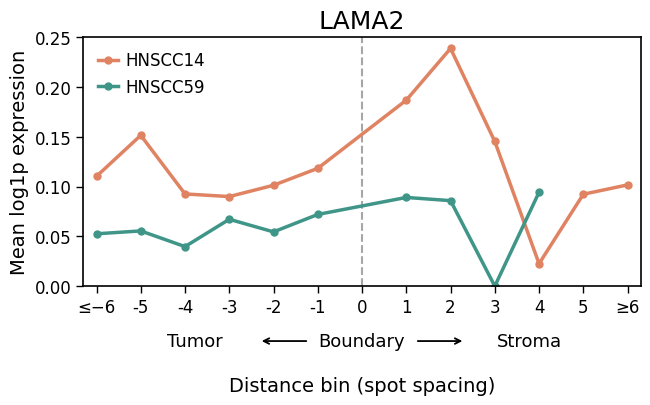

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# =========================
# 参数
# =========================
SAMPLES = ["HNSCC14", "HNSCC59"]
GENE = "LAMA2"
MAX_BIN = 6
MIN_SPOTS = 5
TITLE_SIZE = 18
AXIS_LABEL_SIZE = 14
TICK_SIZE = 12
LEGEND_SIZE = 12
REGION_SIZE = 13
ARROW_SIZE = 18
# 输入目录
indir = Path("./visum/figure/LN").resolve()

# 输出目录
outdir = Path("./visum/figure/LN").resolve()
outdir.mkdir(parents=True, exist_ok=True)

# 两条折线的颜色
COLORS = {
    "HNSCC14": "#E08363",  # 橙红
    "HNSCC59": "#3F9688",  # 青绿
}

# 恢复 Matplotlib 默认绘图设置
# 避免之前设置的 Arial 字体继续生效
plt.rcdefaults()


# =========================
# 1. 读取两个样本的 profile
# =========================
profiles = {}

for sample in SAMPLES:

    file = indir / f"{sample}_{GENE}_profile.csv"

    if not file.exists():
        raise FileNotFoundError(f"未找到文件: {file}")

    profile = pd.read_csv(
        file,
        index_col="distance_bin"
    )

    profile.index = profile.index.astype(int)

    # 只显示 spot 数量 >= MIN_SPOTS 的距离层
    profile["plot_expression"] = (
        profile["mean_expression"].where(
            profile["n_spots"] >= MIN_SPOTS
        )
    )

    profiles[sample] = profile


# =========================
# 2. 绘制两个样本的折线图
# =========================
fig, ax = plt.subplots(figsize=(6.8, 4.8))

for sample in SAMPLES:

    profile = profiles[sample]

    # 去除缺失表达值
    plot_data = (
        profile[["plot_expression"]]
        .dropna()
        .sort_index()
    )

    ax.plot(
        plot_data.index,
        plot_data["plot_expression"],
        color=COLORS[sample],
        linewidth=2.5,
        marker="o",
        markersize=5,
        label=sample,
    )


# =========================
# 3. Boundary 虚线
# =========================
ax.axvline(
    0,
    color="0.65",
    linestyle="--",
    linewidth=1.5,
    zorder=0,
)


# =========================
# 4. 坐标轴
# =========================
ticks = np.arange(-MAX_BIN, MAX_BIN + 1)

tick_labels = [str(i) for i in ticks]

tick_labels[0] = f"≤−{MAX_BIN}"
tick_labels[-1] = f"≥{MAX_BIN}"

ax.set_xticks(ticks)
ax.set_xticklabels(tick_labels)

ax.set_xlim(
    -MAX_BIN - 0.3,
    MAX_BIN + 0.3
)

ax.set_ylim(bottom=0)

# 标题和坐标轴名称
# =========================
# 字体大小设置
# =========================
TITLE_SIZE = 18
AXIS_LABEL_SIZE = 14
TICK_SIZE = 12
LEGEND_SIZE = 12
REGION_SIZE = 13
ARROW_SIZE = 18

# 标题和坐标轴名称
ax.set_title(GENE, fontsize=TITLE_SIZE)
ax.set_ylabel("Mean log1p expression", fontsize=AXIS_LABEL_SIZE)
ax.set_xlabel("Distance bin (spot spacing)", fontsize=AXIS_LABEL_SIZE)

# x轴标题下移
ax.xaxis.set_label_coords(0.5, -0.36)

# 坐标轴边框
for spine in ax.spines.values():
    spine.set_linewidth(1.2)

# 坐标轴刻度
ax.tick_params(
    axis="both",
    width=1.0,
    length=5,
    labelsize=TICK_SIZE,
)

# 图例
ax.legend(
    loc="upper left",
    frameon=False,
    handlelength=1.2,
    handletextpad=0.4,
    fontsize=LEGEND_SIZE,
)


# =========================
# 6. 下方区域标签及箭头
# =========================

# =========================
# 下方区域标签及等长箭头
# =========================
y_text = -0.22

# 文字位置
x_tumor = 0.20
x_boundary = 0.50
x_stroma = 0.80

# 箭头长度控制：左右完全一样
arrow_len = 0.08

# 左箭头中心和右箭头中心
x_left_center = 0.36
x_right_center = 0.64

# 字体大小
REGION_SIZE = 13
ARROW_LW = 1.3

# 三个标签
ax.text(
    x_tumor, y_text, "Tumor",
    transform=ax.transAxes,
    ha="center", va="center",
    fontsize=REGION_SIZE,
    clip_on=False,
)

ax.text(
    x_boundary, y_text, "Boundary",
    transform=ax.transAxes,
    ha="center", va="center",
    fontsize=REGION_SIZE,
    clip_on=False,
)

ax.text(
    x_stroma, y_text, "Stroma",
    transform=ax.transAxes,
    ha="center", va="center",
    fontsize=REGION_SIZE,
    clip_on=False,
)

# 左箭头：Boundary 指向 Tumor
ax.annotate(
    "",
    xy=(x_left_center - arrow_len/2, y_text),   # 箭头尖端（左）
    xytext=(x_left_center + arrow_len/2, y_text),  # 起点（右）
    xycoords=ax.transAxes,
    textcoords=ax.transAxes,
    arrowprops=dict(
        arrowstyle="->",
        lw=ARROW_LW,
        color="black",
        shrinkA=0,
        shrinkB=0,
    ),
    annotation_clip=False,
)

# 右箭头：Boundary 指向 Stroma
ax.annotate(
    "",
    xy=(x_right_center + arrow_len/2, y_text),   # 箭头尖端（右）
    xytext=(x_right_center - arrow_len/2, y_text),  # 起点（左）
    xycoords=ax.transAxes,
    textcoords=ax.transAxes,
    arrowprops=dict(
        arrowstyle="->",
        lw=ARROW_LW,
        color="black",
        shrinkA=0,
        shrinkB=0,
    ),
    annotation_clip=False,
)

# =========================
# 7. 调整图形边距
# =========================
fig.subplots_adjust(
    left=0.14,
    right=0.96,
    top=0.88,
    bottom=0.36,
)


# =========================
# 8. 保存图片
# =========================
tiff_path = (
    outdir /
    f"{GENE}_combined_gradient_2samples.tiff"
)

png_path = (
    outdir /
    f"{GENE}_combined_gradient_2samples.png"
)

# TIFF 600 dpi + LZW压缩
fig.savefig(
    tiff_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
    pil_kwargs={
        "compression": "tiff_lzw"
    },
)

# PNG 300 dpi
fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)


# =========================
# 9. 保存合并后的数据
# =========================
combined_profile = pd.concat(
    profiles,
    names=["sample", "distance_bin"]
)

csv_path = (
    outdir /
    f"{GENE}_combined_profile.csv"
)

combined_profile.to_csv(csv_path)


# =========================
# 10. 显示
# =========================
print("保存成功：")
print(tiff_path)
print(png_path)
print(csv_path)

plt.show()

已保存： LAMA2_LN_mean_expression


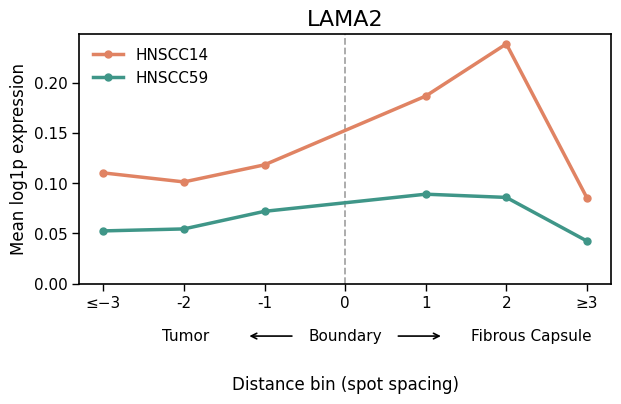

已保存： LAMA2_LN_positive_percent


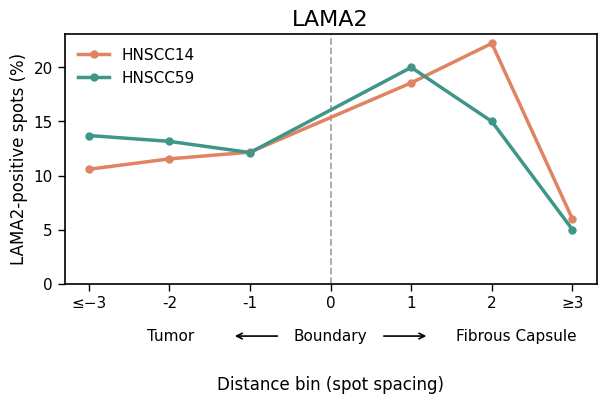

已保存： LAMA2_LN_positive_mean


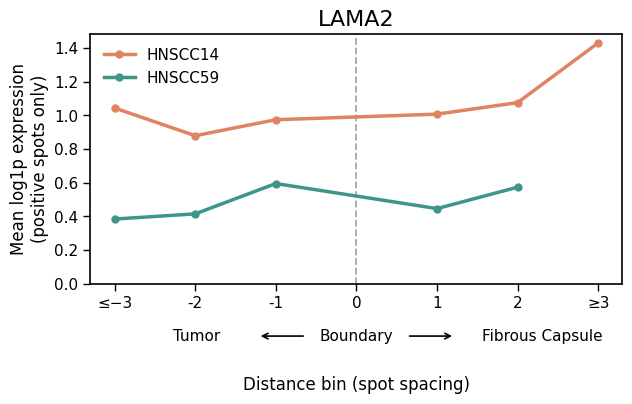


保存完成
输出目录: /content/drive/MyDrive/pharynx/visum/figure/LN
                      n_spots  mean_expression  median_expression  n_positive  \
sample  distance_bin                                                            
HNSCC14 -3               3233         0.110385                0.0         342   
        -2                 78         0.101388                0.0           9   
        -1                 74         0.118419                0.0           9   
         1                 70         0.186961                0.0          13   
         2                 63         0.238937                0.0          14   
         3                184         0.085495                0.0          11   
HNSCC59 -3               4394         0.052566                0.0         602   
        -2                 38         0.054537                0.0           5   
        -1                 33         0.072072                0.0           4   
         1                 30         0.089158    

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# =========================
# 1. 参数
# =========================
SAMPLES = ["HNSCC14", "HNSCC59"]
GENE = "LAMA2"

MAX_BIN = 3          # 可设为3或6
MIN_SPOTS = 5
MIN_POS_SPOTS = 3

CONNECT_BOUNDARY = True

# 淋巴结样本目录
indir = Path("./visum/figure/LN").resolve()
outdir = indir
outdir.mkdir(parents=True, exist_ok=True)

# 样本配色
COLORS = {
    "HNSCC14": "#E08363",
    "HNSCC59": "#3F9688",
}

# 字体
TITLE_SIZE = 16
LABEL_SIZE = 12
TICK_SIZE = 11
LEGEND_SIZE = 11
REGION_SIZE = 11

plt.rcdefaults()


# =========================
# 2. 读取spot数据并计算指标
# =========================
bin_order = np.r_[
    np.arange(-MAX_BIN, 0),
    np.arange(1, MAX_BIN + 1)
]

profiles = {}

for sample in SAMPLES:

    file = indir / f"{sample}_{GENE}_spot_data.csv"

    if not file.exists():
        raise FileNotFoundError(
            f"未找到文件：{file}"
        )

    df = pd.read_csv(file, index_col=0)

    df["expression"] = pd.to_numeric(
        df["expression"],
        errors="coerce"
    )

    df["distance_bin"] = pd.to_numeric(
        df["distance_bin"],
        errors="coerce"
    )

    # 清理缺失和非有限值
    df = df.dropna(
        subset=["expression", "distance_bin"]
    ).copy()

    df = df[
        np.isfinite(df["expression"]) &
        np.isfinite(df["distance_bin"])
    ].copy()

    # 不把0当作独立距离层
    df = df[
        df["distance_bin"] != 0
    ].copy()

    # =========================
    # 合并两端距离层
    # =========================
    # MAX_BIN=3时：
    # <=-3 的所有spot合并到-3
    # >= 3 的所有spot合并到 3

    df["plot_bin"] = (
        df["distance_bin"]
        .clip(
            lower=-MAX_BIN,
            upper=MAX_BIN
        )
        .astype(int)
    )

    # =========================
    # 重新计算三个指标
    # =========================
    profile = (
        df.groupby("plot_bin")["expression"]
        .agg(
            n_spots="count",
            mean_expression="mean",
            median_expression="median",
            n_positive=lambda x: (x > 0).sum(),
            positive_mean=lambda x: x[x > 0].mean()
        )
        .reindex(bin_order)
    )

    profile.index.name = "distance_bin"

    profile["n_spots"] = (
        profile["n_spots"]
        .fillna(0)
        .astype(int)
    )

    profile["n_positive"] = (
        profile["n_positive"]
        .fillna(0)
        .astype(int)
    )

    # LAMA2阳性spot比例
    profile["positive_percent"] = (
        profile["n_positive"]
        / profile["n_spots"].replace(0, np.nan)
        * 100
    )

    # 至少5个spot
    valid = (
        profile["n_spots"] >= MIN_SPOTS
    )

    profile["plot_mean"] = (
        profile["mean_expression"].where(valid)
    )

    profile["plot_percent"] = (
        profile["positive_percent"].where(valid)
    )

    # 阳性spot至少3个
    valid_positive = (
        valid &
        (profile["n_positive"] >= MIN_POS_SPOTS)
    )

    profile["plot_positive_mean"] = (
        profile["positive_mean"].where(
            valid_positive
        )
    )

    profiles[sample] = profile


# =========================
# 3. 定义三个指标
# =========================
metrics = [
    (
        "plot_mean",
        "Mean log1p expression",
        "mean_expression"
    ),
    (
        "plot_percent",
        f"{GENE}-positive spots (%)",
        "positive_percent"
    ),
    (
        "plot_positive_mean",
        "Mean log1p expression\n(positive spots only)",
        "positive_mean"
    ),
]


# =========================
# 4. 绘制折线
# =========================
def draw_metric(ax, metric, ylabel):

    for sample in SAMPLES:

        profile = profiles[sample]
        color = COLORS[sample]

        tumor = profile.loc[
            profile.index < 0
        ]

        stroma = profile.loc[
            profile.index > 0
        ]

        # Tumor侧
        ax.plot(
            tumor.index,
            tumor[metric],
            color=color,
            linewidth=2.5,
            marker="o",
            markersize=5,
            label=sample,
        )

        # Stroma侧
        ax.plot(
            stroma.index,
            stroma[metric],
            color=color,
            linewidth=2.5,
            marker="o",
            markersize=5,
        )

        # 连接-1和+1
        if CONNECT_BOUNDARY:

            y_left = profile.loc[-1, metric]
            y_right = profile.loc[1, metric]

            if (
                pd.notna(y_left) and
                pd.notna(y_right)
            ):
                ax.plot(
                    [-1, 1],
                    [y_left, y_right],
                    color=color,
                    linewidth=2.5,
                )

    # Boundary虚线
    ax.axvline(
        0,
        color="0.65",
        linestyle="--",
        linewidth=1.3,
        zorder=0,
    )

    # X轴
    ticks = np.arange(
        -MAX_BIN,
        MAX_BIN + 1
    )

    tick_labels = [
        str(i) for i in ticks
    ]

    tick_labels[0] = f"≤−{MAX_BIN}"
    tick_labels[-1] = f"≥{MAX_BIN}"

    ax.set_xticks(ticks)
    ax.set_xticklabels(tick_labels)

    ax.set_xlim(
        -MAX_BIN - 0.3,
        MAX_BIN + 0.3
    )

    ax.set_ylim(bottom=0)

    # Y轴
    ax.set_ylabel(
        ylabel,
        fontsize=LABEL_SIZE
    )

    ax.tick_params(
        axis="both",
        labelsize=TICK_SIZE,
        width=1.0,
        length=5,
    )

    for spine in ax.spines.values():
        spine.set_linewidth(1.2)


# =========================
# 5. 添加区域标签和箭头
# =========================
def add_region_labels(ax):

    y_text = -0.21

    region_labels = [
        (0.20, "Tumor"),
        (0.50, "Boundary"),
        (0.85, "Fibrous Capsule"),
    ]

    for x, label in region_labels:

        ax.text(
            x,
            y_text,
            label,
            transform=ax.transAxes,
            ha="center",
            va="center",
            fontsize=REGION_SIZE,
            clip_on=False,
        )

    # 左右等长箭头
    arrow_len = 0.08

    for center, direction in [
        (0.36, -1),
        (0.64, 1),
    ]:

        start = (
            center -
            direction * arrow_len / 2
        )

        end = (
            center +
            direction * arrow_len / 2
        )

        ax.annotate(
            "",
            xy=(end, y_text),
            xytext=(start, y_text),
            xycoords=ax.transAxes,
            textcoords=ax.transAxes,
            arrowprops=dict(
                arrowstyle="->",
                lw=1.2,
                color="black",
                shrinkA=0,
                shrinkB=0,
            ),
            annotation_clip=False,
        )

    # X轴名称
    ax.set_xlabel(
        "Distance bin (spot spacing)",
        fontsize=LABEL_SIZE
    )

    ax.xaxis.set_label_coords(
        0.5,
        -0.37
    )


# =========================
# 6. 保存图片函数
# =========================
def save_figure(fig, filename):

    tiff_path = outdir / f"{filename}.tiff"
    png_path = outdir / f"{filename}.png"

    fig.savefig(
        tiff_path,
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
        pil_kwargs={
            "compression": "tiff_lzw"
        },
    )

    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    print("已保存：", filename)


# =========================
# 7. 分别保存三个指标
# =========================
for metric, ylabel, filename in metrics:

    fig, ax = plt.subplots(
        figsize=(7, 4.8)
    )

    draw_metric(
        ax,
        metric,
        ylabel
    )

    ax.set_title(
        GENE,
        fontsize=TITLE_SIZE
    )

    ax.legend(
        loc="upper left",
        frameon=False,
        fontsize=LEGEND_SIZE,
    )

    add_region_labels(ax)

    fig.subplots_adjust(
        left=0.20,
        right=0.96,
        top=0.88,
        bottom=0.36,
    )

    save_figure(
        fig,
        f"{GENE}_LN_{filename}"
    )

    plt.show()
    plt.close(fig)


# # =========================
# # 8. 保存三联图
# # =========================
# fig, axes = plt.subplots(
#     3,
#     1,
#     figsize=(7, 10),
#     sharex=True,
# )

# for ax, (metric, ylabel, _) in zip(
#     axes,
#     metrics
# ):

#     draw_metric(
#         ax,
#         metric,
#         ylabel
#     )

#     # 显示每个panel的X轴刻度
#     ax.tick_params(
#         axis="x",
#         labelbottom=True
#     )

# axes[0].set_title(
#     GENE,
#     fontsize=TITLE_SIZE
# )

# axes[0].legend(
#     loc="upper right",
#     frameon=False,
#     fontsize=LEGEND_SIZE,
# )

# # 三联图只在最下面添加区域标签
# add_region_labels(axes[-1])

# fig.subplots_adjust(
#     left=0.20,
#     right=0.96,
#     top=0.95,
#     bottom=0.17,
#     hspace=0.32,
# )

# save_figure(
#     fig,
#     f"{GENE}_LN_three_metrics_combined"
# )

# plt.show()
# plt.close(fig)


# =========================
# 9. 保存统计数据
# =========================
combined_profile = pd.concat(
    profiles,
    names=["sample", "distance_bin"]
)

csv_path = (
    outdir /
    f"{GENE}_LN_three_metrics.csv"
)

combined_profile.to_csv(csv_path)

print("\n保存完成")
print("输出目录:", outdir)
print(combined_profile)